# Regulators of nuclear 3'UTR lengthening during motor neuron maturation (D22 → D35)

This notebook finds the RNA-binding proteins (RBPs, from CLIP data) and RNA modifications whose activity at 3'UTRs **changes between D22 and D35 in the nuclear fraction of control (WT) motor neurons**, the window in which the nuclear long-3'UTR programme is set up. These are the *regulators of lengthening*. `Figure_global_regulators_NuclearWT_D35.ipynb` selects its regulators from a single time point (D35). Here they are selected from their D22 → D35 change. The notebook then characterises them:
- activity over the time course and correlation with the expression of their own gene;
- gene and protein expression in CTRL vs VCP;
- STRING interactions and pathway enrichment;
- whether they act in both fractions (APA) or only in the nucleus (nuclear retention);
- their activity in CTRL vs VCP at D35, per region and fraction;
- overlap with the regulators of the VCP effect (VCP vs CTRL at D35);
- condensate propensity;
- behaviour in VCP knock-in cells ± ML240;
- cross-links on condensate-associated lncRNAs.

**Inputs**
- Welch profiles of every CLIP dataset (`MN_diff/results/3UTR_analysis/CLIP/analysis/welch_{proximal,distal}.csv`) and of RNA modification sites (m1A, m6A, m5C, m7G, Nm, pseudouridine, RNA editing; `MN_diff/results/RNA_modifs/<modif>/welch/analysis/`). For each 50-nt bin from −1000 to +200 nt around the proximal (pPAS) or distal (dPAS) poly(A) site, the **Welch score** (`-log10(pval)*dPUD`, column `mean_score_lg10`) is the signed significance of the PUD difference linked to a site in that bin. It is computed per day, fraction and genotype. VCP-R155C and VCP-R191Q are pooled as "VCP".
- Gene-level normalised expression (`df_genes_filtered_normalized.csv`) and proteomics (GSE152983, already log2), parsed with `utrals.expression`.
- Condensate propensity z-scores of RBPs (`ALS_Comp/AxonLoc/Supplementary_tables.csv`, an Excel workbook despite its name, 6th sheet).
- Welch profiles of VCP knock-in cells ± ML240, for every CLIP dataset (`VCP-KI-Ml240/results/3UTR_analysis/CLIP`) and for m6A sites (`VCP-KI-Ml240/results/RNA_modifs/m6A/welch`), loaded with `cliptools`.
- CLIP cross-links per transcript on NEAT1, XIST, MALAT1, NORAD and SFPQ (`MN_diff/results/paraspeckles/<gene>/<gene>_cross_links.csv`).

**Regions** (distances in nt relative to the PAS, defined in the setup cells)
- **Region 1 (R1)**: proximal isoform, [−350, −50] upstream of the pPAS. Score = maximum Welch score in the window, clipped at 0 (enrichment).
- **Region 2 (R2)**: proximal isoform, [0, 150] downstream of the pPAS. Score = −(minimum Welch score in the window), clipped at 0, so a **positive value = depletion strength**.
- **Region 3 (R3)**: distal isoform, [−350, −50] upstream of the dPAS. Score = maximum of the sign-flipped Welch score, clipped at 0.

**Selection of the regulators of lengthening.** For each region, the change of score D35 − D22 (Nuclear WT) of every regulator is z-scored against the changes of all regulators (RBPs and modifications together). The one-sided normal p-value is taken in the direction expected for lengthening: a decrease in R1, an increase in R2 and R3. A regulator is kept in a region if p < 0.05. Only one CLIP dataset is kept per RBP.

The STRING cells are pinned to STRING v12.5 and read STRING's archived responses (`../cache/STRING_v12.5/`, `../cache/STRING_v12.5_responses/`), so the figures are reproduced exactly; network access is only needed for a request that is not archived yet. All figures are saved under `../Figures/Figure_regulators_lengthening`, and every saved file is listed with its legend in `../Figures/README.md`. Tables (.csv) are saved under `../Tables/Figure_regulators_lengthening/` and listed with a description of their columns in `../Tables/README.md`. The APA / nuclear-retention classification of the regulators of each region is written to `regulators_of_nuclear_3UTR_lengthening_D22_to_D35_CTRL_<region>_APA_vs_nuclear_retention_class.csv` (`<region>` = `region1_upstream_pPAS`, `region2_downstream_pPAS` or `region3_upstream_dPAS`) (path given by `utrals.figures.lengthening_regulators_csv`), the candidate RBP lists of the `Figure_m6A_*` notebooks and of the m6A-switch pipeline.

---

## Contents

Each section lists the files it saves, relative to `../Figures/Figure_regulators_lengthening/`.

- [Setup and data loading](#setup)
- [Regulators of lengthening: change in activity between D22 and D35](#d22-d35-zscore)
    - `regulators_activity_D22_to_D35/bubble_zscore_D35_minus_D22_NuclearWT_significant_regulators.pdf`
- [Welch score of the regulators over time (Nuclear WT)](#welch-over-time)
    - `regulators_activity_over_time/heatmap_welch_score_over_time_NuclearWT_significant_regulators_zscore_per_region.pdf`
- [Correlation between regulator activity and its own gene expression over time](#activity-expression)
    - `../Tables/Figure_regulators_lengthening/correlation_Welch_activity_vs_own_gene_expression_D0_to_D35_NuclearCTRL_regulators_of_nuclear_3UTR_lengthening.csv`
    - `regulators_activity_vs_expression/heatmap_correlation_activity_vs_gene_expression_NuclearWT_significant_regulators.pdf`
- [Regulator lists per region](#region-lists) (no figure)
- [Gene and protein expression of the regulators over time, CTRL vs VCP](#expression)
    - `regulators_expression_CTRL_vs_VCP/heatmap_{gene,protein}_expression_{Nuclear,Cytoplasmic}_significant_R{1,2,3}_regulators_CTRL_vs_VCP.pdf`
- [Expression levels of the regulators at D35](#expression-d35)
    - `regulators_expression_CTRL_vs_VCP/barplot_{gene,protein}_expression_D35_{Nuclear,Cytoplasmic}_significant_regulators_CTRL_vs_VCP.pdf`
- [STRING network and pathway enrichment of the regulators](#string)
    - `regulators_STRING_networks/STRING_network_significant_R{1,2,3}_regulators.pdf`
    - `regulators_pathway_enrichment/bubble_enrichment_significant_regulators_genome_background.pdf`
- [APA vs nuclear retention: nuclear vs cytoplasmic activity at D35](#apa-vs-nr)
    - `regulators_APA_vs_nuclear_retention/scatter_nuclear_vs_cytoplasmic_welch_D35_CTRL_significant_R{1,2,3}_regulators.pdf`
- [Regulators of the VCP effect at D35 (VCP vs CTRL, nuclear)](#vcp-effect)
    - `regulators_VCP_vs_CTRL_D35/bubble_zscore_VCP_minus_CTRL_D35_nuclear.pdf`
- [Overlap between the regulators of lengthening and of the VCP effect (Region 2)](#lengthening-vs-vcp)
    - `regulators_lengthening_vs_VCP_overlap/venn_R2_regulators_lengthening_vs_VCP_effect_APA_and_NR.pdf`
- [Condensate propensity of APA vs nuclear-retention regulators (Region 2)](#condensates)
    - `regulators_condensate_propensity/boxplot_condensate_zscore_R2_lengthening_regulators_APA_vs_NR.pdf`
- [Regulators and m6A in VCP knock-in cells ± ML240](#vcp-ki)
    - `regulators_VCP-KI_ML240/barplot_R{1,2,3}_welch_nuclear_VCP-KI_ML240_lengthening_regulators.pdf`
    - `regulators_VCP-KI_ML240/boxplot_welch_change_VCP-KI_ML240_lengthening_regulators.pdf`
    - `regulators_VCP-KI_ML240/barplot_R{1,2,3}_welch_nuclear_VCP-KI_ML240_regulators_of_shortening_in_VCP.pdf`
    - `regulators_VCP-KI_ML240/boxplot_welch_change_VCP-KI_ML240_shortening_in_VCP_regulators.pdf`
    - `regulators_VCP-KI_ML240/barplot_R1_R2_R3_welch_nuclear_VCP-KI_ML240_m6A.pdf`
- [Cross-links of the Region 2 regulators on condensate-associated lncRNAs](#lncrna-crosslinks)
    - `regulators_lncRNA_crosslinks/boxplot_crosslinks_<gene>_R2_regulators_APA_vs_NR.pdf` (NEAT1, XIST, MALAT1, NORAD, SFPQ)

<a id="setup"></a>
## Setup and data loading

Imports, output folder, region boundaries (`positive_proximal_region` = R1, `negative_proximal_region` = R2, `positive_distal_region` = R3), colour palette and a sort key for the condition columns (fraction, then genotype, then day).

In [1]:
import pandas as pd

from scipy.stats import pearsonr
from matplotlib.lines import Line2D

from numpy.linalg import svd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
from scipy.stats import ttest_ind

import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np


from utrals.paths import PROJECT_DIR, PROTEOMICS_CSV, AXONLOC_CSV  # data locations outside the repository (paths.env)
from utrals.rbp_names import parse_rbp_name, get_clip_name, get_RBP_name
from utrals import expression, figures
figures.fix_random_seeds(0)  # fixed jitter and bootstrap confidence intervals: identical figures on every run

import matplotlib
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

import warnings
warnings.filterwarnings("ignore")

In [2]:
figures_subfolder = "../Figures/Figure_regulators_lengthening"
tables_subfolder = "../Tables/Figure_regulators_lengthening"
import os
from functools import partial

if not os.path.exists(f"{figures_subfolder}"):
    os.makedirs(f"{figures_subfolder}")

# save_figure / register_figure save a file and list it, with its legend, in ../Figures/README.md;
# save_table saves a .csv / .xlsx table and lists it, with its description, in ../Tables/README.md
from utrals import expression, figures
save_figure = partial(figures.save_figure, notebook="Figure_regulators_lengthening.ipynb")
register_figure = partial(figures.register_figure, notebook="Figure_regulators_lengthening.ipynb")
save_table = partial(figures.save_table, notebook="Figure_regulators_lengthening.ipynb")
    

In [3]:
positive_proximal_region = [-350, -50]
negative_proximal_region = [0, 150]
positive_distal_region = [-350, -50]

In [4]:
palette_condition = {"Cytoplasmic_WT": "#767676", 
                     "Nuclear_WT":  "#c5c5c5",
                     "Nuclear_VCP": "#d39eff",
                    "Cytoplasmic_VCP": "#8936ce"}

In [5]:



day_order = {'D0': 0, 'D3': 1, 'D7': 2, 'D14': 3, 'D22': 4, 'D35': 5}
compartment_order = {'Cytoplasmic': 0, 'Nuclear': 1}
vcp_order = {'WT': 0, 'VCP': 1}

def sort_key(col):
    parts = col.split('_')
    compartment = parts[0]
    vcp = parts[1]
    day = parts[2]
    return (compartment_order.get(compartment, 99), vcp_order.get(vcp, 99), day_order.get(day, 99))





### Load Welch scores and build the region matrices

Loads the proximal and distal Welch tables of all CLIP datasets and of the 7 RNA modifications (`proximal`, `distal`, concatenated into `df`). For every regulator and condition (`<Compartment>_<Genotype>_<Day>`), it takes the extreme Welch score inside each region and pivots it into `matrix_region1`, `matrix_region2` (R2 positive = depletion) and `matrix_region3` (regulators × conditions, column suffix `_region{1,2,3}`). `data_scaled` (Nuclear WT D35 scores divided by their SD) is only used below to list the regulators of the panel.

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt



# Load RBPs welch
proximal = pd.read_csv(f"{PROJECT_DIR}/MN_diff/results/3UTR_analysis/CLIP/analysis/welch_proximal.csv", index_col=0)
distal = pd.read_csv(f"{PROJECT_DIR}/MN_diff/results/3UTR_analysis/CLIP/analysis/welch_distal.csv", index_col=0)

proximal.rename(columns={"CLIP": "regulator"}, inplace=True)
distal.rename(columns={"CLIP": "regulator"}, inplace=True)



# Load modifications welch 
modifs = ["m1A", "m6A", "m5C", "m7G", "Nm", "Pseudo", "RNA-editing"]


welch_distals = []
welch_proximals = []
for modif in modifs:
    path_to_processed_RBPs = f"{PROJECT_DIR}/MN_diff/results/RNA_modifs/{modif}/welch/analysis"
    welch_distal = pd.read_csv(os.path.join(path_to_processed_RBPs, "welch_distal.csv"), index_col=0)
    welch_proximal = pd.read_csv(os.path.join(path_to_processed_RBPs, "welch_proximal.csv"), index_col=0)
    welch_distals.append(welch_distal)
    welch_proximals.append(welch_proximal)
    
welch_proximal = pd.concat(welch_proximals)
welch_distal = pd.concat(welch_distals)

welch_proximal.rename(columns={"CLIP": 'regulator'}, inplace=True)
welch_distal.rename(columns={"CLIP": 'regulator'}, inplace=True)

welch_proximal['regulator'] = welch_proximal['regulator'].apply(lambda x: x.split('hg38.')[1].split('.gff')[0])
welch_distal['regulator'] = welch_distal['regulator'].apply(lambda x: x.split('hg38.')[1].split('.gff')[0])

# Merge modifications and RBPs welch
proximal = pd.concat([proximal,
                      welch_proximal])

distal = pd.concat([distal, welch_distal])
df = pd.concat([proximal, distal])

df.replace({"Wildtype": "WT"}, inplace=True)
df.reset_index(inplace=True, drop=True)
df.replace({"VCP-R155C": "VCP", "VCP-R191Q": 'VCP'}, inplace=True)

region = positive_proximal_region
df_region = df[(df['dist'] >= region[0]) & (df['dist'] <= region[1]) & (df['Isoform'] == "Proximal 3'UTR Isoform")]
df_int = df_region.loc[df_region.groupby(["Compartment", "regulator", "VCP", "Day"])["mean_score_lg10"].idxmax()]
df_int['Condition'] = df_int['Compartment'] + '_' + df_int['VCP'] + '_' + df_int['Day']
df_int["mean_score_lg10"] = df_int["mean_score_lg10"].clip(lower=0)

matrix_region1 = df_int.pivot(index="regulator", columns='Condition', values='mean_score_lg10')
matrix_region1.columns = [col + '_region1' for col in matrix_region1.columns]

region = negative_proximal_region
df_region = df[(df['dist'] >= region[0]) & (df['dist'] <= region[1]) & (df['Isoform'] == "Proximal 3'UTR Isoform")]
df_int = df_region.loc[df_region.groupby(["Compartment", "regulator", "VCP", "Day"])["mean_score_lg10"].idxmin()]
df_int['Condition'] = df_int['Compartment'] + '_' + df_int['VCP'] + '_' + df_int['Day']
df_int["mean_score_lg10"] = df_int["mean_score_lg10"].clip(upper=0)

matrix_region2 = -df_int.pivot(index="regulator", columns='Condition', values='mean_score_lg10')
matrix_region2.columns = [col + '_region2' for col in matrix_region2.columns]

region = positive_distal_region
df_region = df[(df['dist'] >= region[0]) & (df['dist'] <= region[1]) & (df['Isoform'] == "Distal 3'UTR Isoform")]
df_region["mean_score_lg10"] = - df_region["mean_score_lg10"]
df_int = df_region.loc[df_region.groupby(["Compartment", "regulator", "VCP", "Day"])["mean_score_lg10"].apply(lambda x: x.idxmax())]
df_int['Condition'] = df_int['Compartment'] + '_' + df_int['VCP'] + '_' + df_int['Day']
df_int["mean_score_lg10"] = df_int["mean_score_lg10"].clip(lower=0)

matrix_region3 = df_int.pivot(index="regulator", columns='Condition', values='mean_score_lg10')
# matrix_region3 = -matrix_region3
matrix_region3.columns = [col + '_region3' for col in matrix_region3.columns]




matrix_not_scaled = pd.concat([matrix_region1, -matrix_region2, matrix_region3], axis=1)

data = matrix_not_scaled[["Nuclear_WT_D35_region1", 
                         "Nuclear_WT_D35_region2", 
                         "Nuclear_WT_D35_region3"]]
# Divide by per-column std, skipping NaNs
# Replace inf before scaling (1 inf present in region1 and region2 from the pipeline)
data = data.replace([np.inf, -np.inf], np.nan)
col_stds = data.apply(lambda col: np.nanstd(col.dropna(), ddof=1))
data_scaled = data / col_stds



<a id="d22-d35-zscore"></a>
## Regulators of lengthening: change in activity between D22 and D35

For each region, the change D35 − D22 of the Nuclear WT score of every regulator is z-scored against the changes of all regulators. The p-value is one-sided (normal survival function), in the direction expected for lengthening: a **decrease** for R1 and an **increase** for R2 and R3. Bubble plot of every regulator significant (p < 0.05) in at least one region. Rows are grouped by significance pattern (R1 only, R2 only, …, all) and sorted by mean signed z within each group. Several CLIPs of the same RBP collapse to the first one met from the top. Colour = z-score, size = −log10(p), grey dot = not significant; RNA modifications are labelled in bold orange.

The next two cells build `kept` (one CLIP per RBP, with its group).

Saved: `regulators_activity_D22_to_D35/bubble_zscore_D35_minus_D22_NuclearWT_significant_regulators.pdf`.

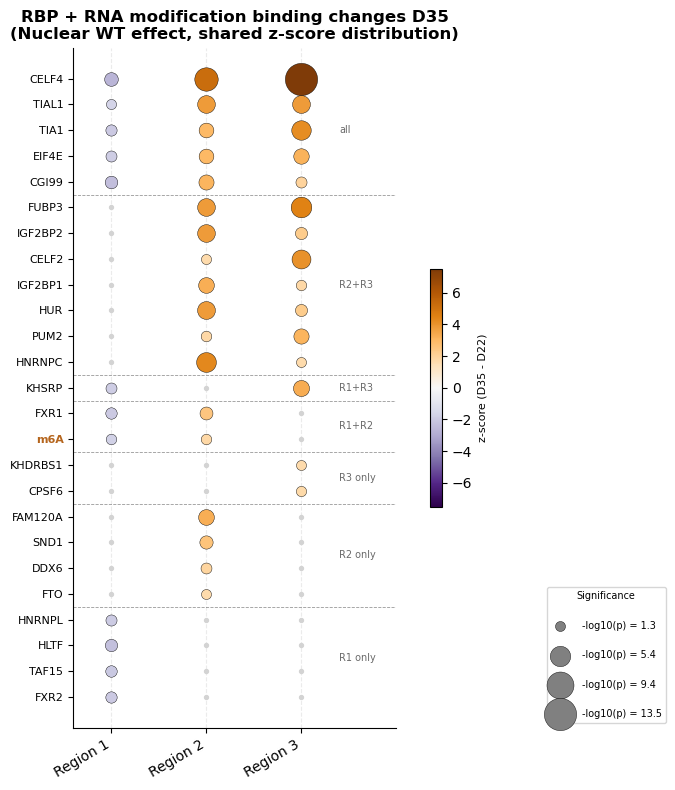

In [7]:
from scipy import stats
from scipy.spatial.distance import squareform
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import seaborn as sns
import numpy as np

# ---- z-score bubble plot: RBPs and RNA modifications share one z-score distribution, ordered together ----
matrix_merged_unscaled = pd.concat([matrix_region1, matrix_region2, matrix_region3], axis=1)


# matrix_merged_all = pd.concat([matrix_merged_unscaled, matrix_merged_modif], axis=0)

region_configs_all = {
    'Region 1': ('Nuclear_WT_D22_region1', 'Nuclear_WT_D35_region1', -1),
    'Region 2': ('Nuclear_WT_D22_region2', 'Nuclear_WT_D35_region2', +1),
    'Region 3': ('Nuclear_WT_D22_region3', 'Nuclear_WT_D35_region3', +1),
}

summaries_all = {}
for label, (col_d22, col_d35, sign) in region_configs_all.items():
    diff = matrix_merged_unscaled[col_d35] - matrix_merged_unscaled[col_d22]
    z = (diff - diff.mean()) / diff.std(ddof=0)   # z-score over the combined RBP + modif distribution
    signal_z = sign * z
    raw_z    = z
    p = stats.norm.sf(signal_z)
    summaries_all[label] = pd.DataFrame({'signal_z': signal_z, 'raw_z': raw_z, 'pvalue': p})

sig_all = set()
for df in summaries_all.values():
    sig_all.update(df[df['pvalue'] < 0.05].index)
sig_all = sorted(sig_all)

z_mat_all     = pd.DataFrame({r: summaries_all[r]['raw_z']    for r in summaries_all}).loc[sig_all]
sig_z_mat_all = pd.DataFrame({r: summaries_all[r]['signal_z'] for r in summaries_all}).loc[sig_all]
p_mat_all     = pd.DataFrame({r: summaries_all[r]['pvalue']   for r in summaries_all}).loc[sig_all]
nlp_mat_all   = -np.log10(p_mat_all)

sig_flag_all = (p_mat_all < 0.05)
regions_all  = list(sig_flag_all.columns)

_pattern_order = [
    ((True,  False, False), 'R1 only'),
    ((False, True,  False), 'R2 only'),
    ((False, False, True),  'R3 only'),
    ((True,  True,  False), 'R1+R2'),
    ((True,  False, True),  'R1+R3'),
    ((False, True,  True),  'R2+R3'),
    ((True,  True,  True),  'all'),
]

# Same ordering as z_score_bubble_WT_effect: grouped by significance pattern
# (R1 only, R2 only, ..., all), then by mean signal_z within each group. RNA
# modifications are ordered like any other RBP (no separate block).
ordered_all    = []
group_info_all = []   # (start_i, end_i, label)
for pattern, glabel in _pattern_order:
    group = [i for i in sig_all if tuple(sig_flag_all.loc[i, r] for r in regions_all) == pattern]
    if not group:
        continue
    group.sort(key=lambda i: sig_z_mat_all.loc[i].mean())
    start = len(ordered_all)
    ordered_all.extend(group)
    group_info_all.append((start, len(ordered_all) - 1, glabel))

# One row per RBP (get_RBP_name): several CLIPs of the same RBP (replicates, cell lines,
# iCLIP vs eCLIP) collapse to the first one met reading the plot from TOP to bottom.
# Row 0 is drawn at the bottom, so walk ordered_all from the end.
keep, seen = set(), set()
for entity in reversed(ordered_all):
    rbp_name = get_RBP_name(entity)
    if rbp_name not in seen:
        seen.add(rbp_name)
        keep.add(entity)

ordered_dedup, group_info_dedup = [], []
for start, end, glabel in group_info_all:
    members = [e for e in ordered_all[start:end + 1] if e in keep]
    if not members:
        continue
    s0 = len(ordered_dedup)
    ordered_dedup.extend(members)
    group_info_dedup.append((s0, len(ordered_dedup) - 1, glabel))
ordered_all, group_info_all = ordered_dedup, group_info_dedup
rbp_labels_all = [get_RBP_name(e) for e in ordered_all]

z_mat_all   = z_mat_all.loc[ordered_all]
p_mat_all   = p_mat_all.loc[ordered_all]
nlp_mat_all = nlp_mat_all.loc[ordered_all]

n_all = len(ordered_all)
col_positions_all = [i * 2 for i in range(len(regions_all))]

# ── Bubble plot ───────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, max(4, n_all * 0.32)))

cmap = sns.diverging_palette(250, 30, s=80, l=55, as_cmap=True)
cmap = cm.PuOr_r

absmax = max(abs(z_mat_all.values.max()), abs(z_mat_all.values.min()), 2)
norm_c = mcolors.TwoSlopeNorm(vmin=-absmax, vcenter=0, vmax=absmax)

for j, region in enumerate(regions_all):
    xpos = col_positions_all[j]
    for i, entity in enumerate(z_mat_all.index):
        z_val   = z_mat_all.loc[entity, region]
        p_val   = p_mat_all.loc[entity, region]
        nlp_val = nlp_mat_all.loc[entity, region]
        if p_val < 0.05:
            ax.scatter(xpos, i, s=nlp_val * 40, c=[cmap(norm_c(z_val))],
                       zorder=3, edgecolors='black', linewidths=0.3)
        else:
            ax.scatter(xpos, i, s=8, c='lightgrey', zorder=2)

# Group separators and labels (as in z_score_bubble_WT_effect)
for idx, (start, end, glabel) in enumerate(group_info_all):
    if idx > 0:
        ax.axhline(start - 0.5, color='black', linewidth=0.6, linestyle='--', alpha=0.4)
    ax.text(col_positions_all[-1] + 0.8, (start + end) / 2, glabel, fontsize=7, va='center', color='dimgrey')

ax.set_xticks(col_positions_all)
ax.set_xticklabels(regions_all, fontsize=10, rotation=30, ha='right')
ax.set_yticks(range(n_all))
ax.set_yticklabels(rbp_labels_all, fontsize=8)
for tick_label, entity in zip(ax.get_yticklabels(), z_mat_all.index):
    if entity in modifs:
        tick_label.set_color('#b5651d')
        tick_label.set_fontweight('bold')

ax.set_xlim(-0.8, col_positions_all[-1] + 2.0)
ax.grid(axis='x', alpha=0.25, linestyle='--')
ax.set_title("RBP + RNA modification binding changes D35\n(Nuclear WT effect, shared z-score distribution)", weight='bold')

sm = cm.ScalarMappable(cmap=cmap, norm=norm_c)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, shrink=0.35, pad=0.08)
cbar.set_label('z-score (D35 - D22)', fontsize=8)

nlp_max_all = nlp_mat_all[p_mat_all < 0.05].max().max()
legend_values_all = np.linspace(-np.log10(0.05), nlp_max_all, 4)
legend_handles_all = [
    plt.scatter([], [], s=nlp_ex * 40, c='grey', edgecolors='black', linewidths=0.3,
                label=f'-log10(p) = {nlp_ex:.1f}')
    for nlp_ex in legend_values_all
]
ax.legend(handles=legend_handles_all, title='Significance', fontsize=7, title_fontsize=7,
          loc='lower left', bbox_to_anchor=(1.45, 0),
          labelspacing=2, handletextpad=1.2)

sns.despine(ax=ax)
plt.tight_layout()

save_figure(f"{figures_subfolder}/regulators_activity_D22_to_D35/bubble_zscore_D35_minus_D22_NuclearWT_significant_regulators.pdf",
            legend="Regulators of 3'UTR lengthening: CLIP datasets and RNA modifications (orange bold labels) whose "
                   "Welch score changes significantly between D22 and D35 in the nuclear fraction of CTRL motor neurons "
                   "in at least one region. For each region (columns; R2 score = depletion strength, positive), the "
                   "change D35 - D22 is z-scored against the changes of all regulators (RBPs and modifications "
                   "together). Colour = z-score; bubble size = -log10(p), one-sided normal p in the direction tested "
                   "for lengthening (decrease for R1, increase for R2 and R3); grey dot = p >= 0.05. Rows grouped by "
                   "significance pattern (R1 only, ..., all); one row per RBP (the first CLIP from the top is kept).")
plt.show()

In [8]:
rbp_labels_all = [get_RBP_name(r) for r in ordered_all]

In [9]:
kept = pd.DataFrame({
    "regulator": ordered_all,
    "RBP": rbp_labels_all,
    "group": [g for s, e, g in group_info_all for _ in range(s, e + 1)],
}).iloc[::-1].reset_index(drop=True)
kept.drop_duplicates(['RBP'], keep='first', inplace=True)

<a id="welch-over-time"></a>
## Welch score of the regulators over time (Nuclear WT)

Heatmap of the regulators of lengthening (rows, same order and groups as the bubble plot) × days, one block per region, with scores oriented so that higher = stronger effect in every region. Each region is z-scored **as a whole**, with one mean and SD over all regulators × days of that region. Values can therefore be compared across days and regulators, but not across regions. NaN cells (including infinite scores from p = 0) are grey.

Saved: `regulators_activity_over_time/heatmap_welch_score_over_time_NuclearWT_significant_regulators_zscore_per_region.pdf`.

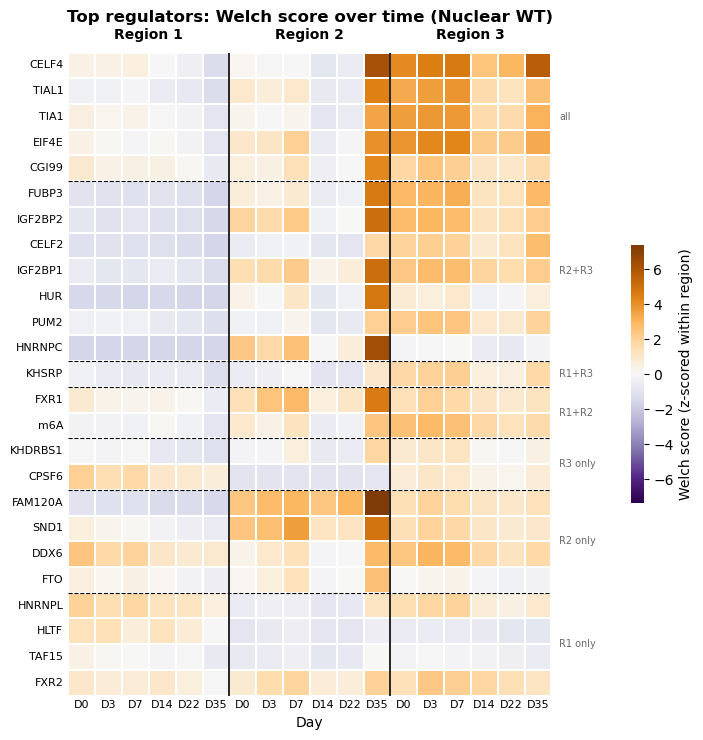

In [10]:
# ---- Welch score of the top regulators across days and regions (Nuclear WT), row-normalised ----
# Scores are oriented so that higher = stronger effect in every region
# (R1: proximal enrichment, R2: proximal depletion, R3: distal enrichment).
# Standardised WITHIN each region, with a single mean/std computed over all
# regulators x all days of that region: values stay comparable across days (time
# evolution) and across RBPs, but not across regions (whose scales differ ~10x).
days = ["D0", "D3", "D7", "D14", "D22", "D35"]
region_ids = [1, 2, 3]
heat_cols = [f"Nuclear_WT_{day}_region{r}" for r in region_ids for day in days]

missing_cols = [c for c in heat_cols if c not in matrix_merged_unscaled.columns]
if missing_cols:
    print(f"Missing columns (left blank): {missing_cols}")

# inf Welch scores (p-values underflowing to 0; 6 each in region 1 and 2) would make the
# region mean inf / std NaN and blank the whole block -> treat them as missing.
heat_all = matrix_merged_unscaled.reindex(columns=heat_cols).replace([np.inf, -np.inf], np.nan)
for r in region_ids:
    block = [c for c in heat_cols if c.endswith(f"_region{r}")]
    vals = heat_all[block].stack()
    heat_all[block] = (heat_all[block] - vals.mean()) / vals.std()

# Same rows as the bubble plot above (deduplicated ordered_all / rbp_labels_all, one row
# per RBP). The bubble plot draws row 0 at the bottom while the heatmap draws it at the
# top, so reverse the order (and the group spans) to read both plots the same way.
heat_rows = ordered_all[::-1]
heat_labels = [get_RBP_name(e) for e in heat_rows]
n_regs = len(heat_rows)
heat_group_info = [(n_regs - 1 - end, n_regs - 1 - start, glabel)
                   for start, end, glabel in group_info_all][::-1]
heat_norm = heat_all.loc[heat_rows]
fig, ax = plt.subplots(figsize=(7.5, max(4, n_regs * 0.3)))
absmax = np.nanmax(np.abs(heat_norm.values))
sns.heatmap(heat_norm, cmap=cm.PuOr_r, center=0, vmin=-absmax, vmax=absmax,
            xticklabels=days * len(region_ids), yticklabels=heat_labels,
            linewidths=0.3, linecolor="white",
            cbar_kws={"label": "Welch score (z-scored within region)", "shrink": 0.4, "pad": 0.12}, ax=ax)
ax.set_facecolor("lightgrey")   # NaN cells

# Region separators (vertical) and region labels on top
for k in range(1, len(region_ids)):
    ax.axvline(k * len(days), color="black", linewidth=1.2)
for k, r in enumerate(region_ids):
    ax.text(k * len(days) + len(days) / 2, -0.4, f"Region {r}",
            ha="center", va="bottom", fontsize=10, weight="bold")

# Regulator-group separators (horizontal) and labels on the right
for idx, (start, end, glabel) in enumerate(heat_group_info):
    if idx > 0:
        ax.axhline(start, color="black", linewidth=0.8, linestyle="--")
    ax.text(len(heat_cols) + 0.3, (start + end + 1) / 2, glabel,
            fontsize=7, va="center", color="dimgrey")

ax.set_xlabel("Day")
ax.set_ylabel("")
ax.tick_params(axis="y", labelsize=8, length=0)
ax.tick_params(axis="x", labelsize=8, rotation=0, length=0)
ax.set_title("Top regulators: Welch score over time (Nuclear WT)", weight="bold", pad=22)
plt.tight_layout()

save_figure(f"{figures_subfolder}/regulators_activity_over_time/heatmap_welch_score_over_time_NuclearWT_significant_regulators_zscore_per_region.pdf",
            legend="Welch score over MN differentiation (D0 -> D35, nuclear fraction, CTRL) of the regulators whose Welch score changes significantly between D22 and D35 in the nuclear fraction of CTRL motor neurons (one-sided z-test, p < 0.05, one CLIP per RBP) "
                   "(rows, same order and groups as the D22 -> D35 bubble plot), one block of 6 days per region (R2 = "
                   "depletion strength, positive). Each region z-scored as a whole (one mean and SD over all regulators "
                   "x days of that region): comparable across days and regulators, not across regions. Grey = missing.")
plt.show()

<a id="activity-expression"></a>
## Correlation between regulator activity and its own gene expression over time

For each regulator (rows, as in the heatmap above) and region (columns), the Spearman correlation across the 6 days between its activity (region score, Nuclear WT) and the nuclear WT expression of its own gene (log2(normalised counts + 1), mean of replicates). n = 6, so the p-values (`*` = p < 0.05) are indicative only. The correlation is computed only with at least 4 days and a non-flat activity. RNA modifications, and RBPs whose gene is not in the expression table, stay grey. `RBP_TO_SYMBOL` maps CLIP names to gene symbols (e.g. TDP43 → TARDBP). Pearson r is also written to the table.

Saved as `regulators_activity_vs_expression/heatmap_correlation_activity_vs_gene_expression_NuclearWT_significant_regulators.pdf`; the table is `../Tables/Figure_regulators_lengthening/correlation_Welch_activity_vs_own_gene_expression_D0_to_D35_NuclearCTRL_regulators_of_nuclear_3UTR_lengthening.csv`.

No gene expression (row left grey): ['m6A']


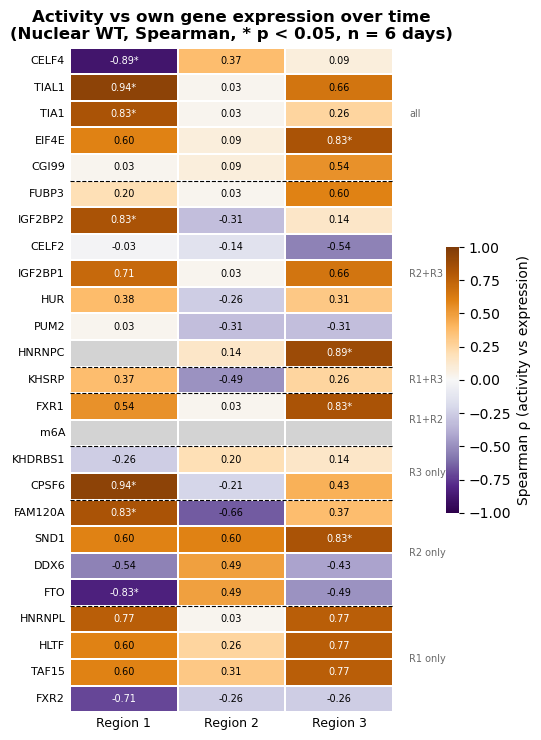

In [11]:
# ---- Correlation between regulator activity and its own gene expression over time ----
# Rows       = same regulators, order and groups as the Welch-over-time heatmap above
#              (heat_rows / heat_labels / heat_group_info: one row per RBP, top to bottom).
# Columns    = the 3 regions: every regulator is correlated in every region.
# Activity   = Welch score of that CLIP in the region, Nuclear WT, per day, oriented so that
#              higher = stronger effect (R1: proximal enrichment, R2: proximal depletion,
#              R3: distal enrichment).
# Expression = the RBP's gene, log2(normalised counts + 1), Nuclear WT, mean of replicates
#              (loaded/parsed with utrals.expression).
# Spearman correlation across the 6 days (D0-D35): n = 6, so p-values are indicative only.
from utrals.expression import load_expression_metadata, gene_expression_over_time, DAY_ORDER
from scipy.stats import spearmanr, pearsonr

expr_path = f"{PROJECT_DIR}/MN_diff/results/genes_preprocessing/df_genes_filtered_normalized.csv"
df_genes, meta_genes = load_expression_metadata(expr_path)

RBP_TO_SYMBOL = {"TDP43": "TARDBP", "CPSF160": "CPSF1", "HUR": "ELAVL1", "CGI99": "RTRAF"}

days = [f"D{d}" for d in DAY_ORDER]
region_ids = [1, 2, 3]
activity = pd.concat([matrix_region1, matrix_region2, matrix_region3], axis=1).replace([np.inf, -np.inf], np.nan)


def nuclear_wt_expression(rbp):
    """Mean Nuclear WT log2 expression per day of an RBP's gene (None if not in df_genes)."""
    symbol = RBP_TO_SYMBOL.get(rbp, rbp)
    if symbol not in df_genes.index:
        return None
    long = gene_expression_over_time(symbol, df_genes, meta_genes)
    long = long[(long["Compartment"] == "Nuclear") & (long["Genotype"] == "WT")]
    return long.groupby("Day")["log2_expression"].mean().reindex(DAY_ORDER).set_axis(days)


records = []
for reg, rbp in zip(heat_rows, heat_labels):
    expr = nuclear_wt_expression(rbp)
    for r in region_ids:
        rec = {"regulator": reg, "RBP": rbp, "region": f"Region {r}",
               "spearman_rho": np.nan, "spearman_p": np.nan, "pearson_r": np.nan, "pearson_p": np.nan,
               "n_days": 0}
        if expr is not None:
            act = activity.loc[reg, [f"Nuclear_WT_{d}_region{r}" for d in days]].set_axis(days)
            ok = act.notna() & expr.notna()
            rec["n_days"] = int(ok.sum())
            if ok.sum() >= 4 and act[ok].nunique() > 1:   # flat activity (e.g. all 0) -> undefined
                rec["spearman_rho"], rec["spearman_p"] = spearmanr(act[ok], expr[ok])
                rec["pearson_r"], rec["pearson_p"] = pearsonr(act[ok], expr[ok])
        records.append(rec)
no_expr = [rbp for rbp in heat_labels if nuclear_wt_expression(rbp) is None]
if no_expr:
    print(f"No gene expression (row left grey): {no_expr}")

corr_activity_expression = pd.DataFrame(records)
corr_dir = f"{figures_subfolder}/regulators_activity_vs_expression"
os.makedirs(corr_dir, exist_ok=True)
save_table(corr_activity_expression, f"{tables_subfolder}/correlation_Welch_activity_vs_own_gene_expression_D0_to_D35_NuclearCTRL_regulators_of_nuclear_3UTR_lengthening.csv", index=False,
           legend="Table behind heatmap_correlation_activity_vs_gene_expression_NuclearWT_significant_regulators.pdf: "
                  "one row per regulator of nuclear 3'UTR lengthening (Welch score changing significantly between D22 "
                  "and D35 in nuclear CTRL; one CLIP per RBP) and region (R1, R2, R3): regulator, RBP, Spearman rho / p "
                  "and Pearson r / p between its Welch score in the region (nuclear CTRL, oriented so that higher = "
                  "stronger effect) and the nuclear CTRL expression of its own gene (log2(normalised counts + 1), mean "
                  "of replicates) across the 6 days D0-D35, and n_days = days with both values (NaN = no expression, "
                  "e.g. RNA modifications, fewer than 4 days or flat activity).")

rho_mat = corr_activity_expression.pivot(index="regulator", columns="region", values="spearman_rho").loc[heat_rows]
p_mat_corr = corr_activity_expression.pivot(index="regulator", columns="region", values="spearman_p").loc[heat_rows]

# ── Heatmap: regulators x regions ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(5.5, max(4, len(heat_rows) * 0.3)))
sns.heatmap(rho_mat, cmap=cm.PuOr_r, center=0, vmin=-1, vmax=1,
            yticklabels=heat_labels, linewidths=0.3, linecolor="white",
            cbar_kws={"label": "Spearman ρ (activity vs expression)", "shrink": 0.4, "pad": 0.12}, ax=ax)
ax.set_facecolor("lightgrey")   # NaN: no expression, or activity flat over time in that region

# rho values (drawn by hand: seaborn's annot only fills the first rows on this matplotlib)
for i, reg in enumerate(heat_rows):
    for j, region in enumerate(rho_mat.columns):
        rho, pval = rho_mat.loc[reg, region], p_mat_corr.loc[reg, region]
        if np.isnan(rho):
            continue
        ax.text(j + 0.5, i + 0.5, f"{rho:.2f}" + ("*" if pval < 0.05 else ""), ha="center", va="center",
                fontsize=7, color="white" if abs(rho) > 0.7 else "black")

# Regulator-group separators (horizontal) and labels on the right, as in the Welch heatmap
for idx, (start, end, glabel) in enumerate(heat_group_info):
    if idx > 0:
        ax.axhline(start, color="black", linewidth=0.8, linestyle="--")
    ax.text(len(region_ids) + 0.15, (start + end + 1) / 2, glabel,
            fontsize=7, va="center", color="dimgrey")

ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="y", labelsize=8, length=0)
ax.tick_params(axis="x", labelsize=9, rotation=0, length=0)
ax.set_title("Activity vs own gene expression over time\n(Nuclear WT, Spearman, * p < 0.05, n = 6 days)",
             weight="bold")
plt.tight_layout()
save_figure(f"{corr_dir}/heatmap_correlation_activity_vs_gene_expression_NuclearWT_significant_regulators.pdf",
            legend="Spearman correlation, across the 6 days of MN differentiation (n = 6, p-values indicative only), "
                   "between the activity of each of the regulators whose Welch score changes significantly between D22 and D35 in the nuclear fraction of CTRL motor neurons (one-sided z-test, p < 0.05, one CLIP per RBP) (Welch score in the region, nuclear CTRL; higher = "
                   "stronger effect in every region) and the nuclear CTRL expression of its own gene (log2(normalised "
                   "counts + 1), mean of replicates). Rows as in the Welch-over-time heatmap; * = p < 0.05; grey = no "
                   "expression (e.g. RNA modifications) or activity flat over time.")
plt.show()


<a id="region-lists"></a>
## Regulator lists per region

`sig_region{1,2,3}`: CLIP datasets (and modifications) significant in each region, one per RBP (from `kept`). `genes_sig_region{1,2,3}`: the matching RBP names, without the RNA modifications, used for expression and STRING. No figure.

In [12]:
sig_region1 = p_mat_all[p_mat_all['Region 1'] < 0.05].index.tolist()
sig_region2 = p_mat_all[p_mat_all['Region 2'] < 0.05].index.tolist()
sig_region3 = p_mat_all[p_mat_all['Region 3'] < 0.05].index.tolist()

In [13]:
sig_region1 = [r for r in sig_region1 if r in kept['regulator'].values]
sig_region2 = [r for r in sig_region2 if r in kept['regulator'].values]
sig_region3 = [r for r in sig_region3 if r in kept['regulator'].values]

In [14]:
# Gene expression

genes_sig_region1 = [get_RBP_name(r) for r in sig_region1 if r not in modifs]
genes_sig_region2 = [get_RBP_name(r) for r in sig_region2 if r not in modifs]
genes_sig_region3 = [get_RBP_name(r) for r in sig_region3 if r not in modifs]


<a id="expression"></a>
## Gene and protein expression of the regulators over time, CTRL vs VCP

For each region's list, `utrals.expression.plot_wt_vs_vcp_heatmap` draws the mean expression per day, CTRL and VCP side by side. Each row is z-scored jointly over the 12 columns (6 days × 2 genotypes), rows are clustered on the CTRL panel, and `*` marks days where CTRL and VCP differ (Welch's t-test on replicates, p < 0.05, uncorrected). Gene expression (log2(normalised counts + 1)) and protein expression (proteomics, log2), each in the nuclear and the cytoplasmic fraction.

Saved in `regulators_expression_CTRL_vs_VCP/`: `heatmap_{gene,protein}_expression_{Nuclear,Cytoplasmic}_significant_R{1,2,3}_regulators_CTRL_vs_VCP.pdf` (12 files).

R1 - gene expression (Nuclear)


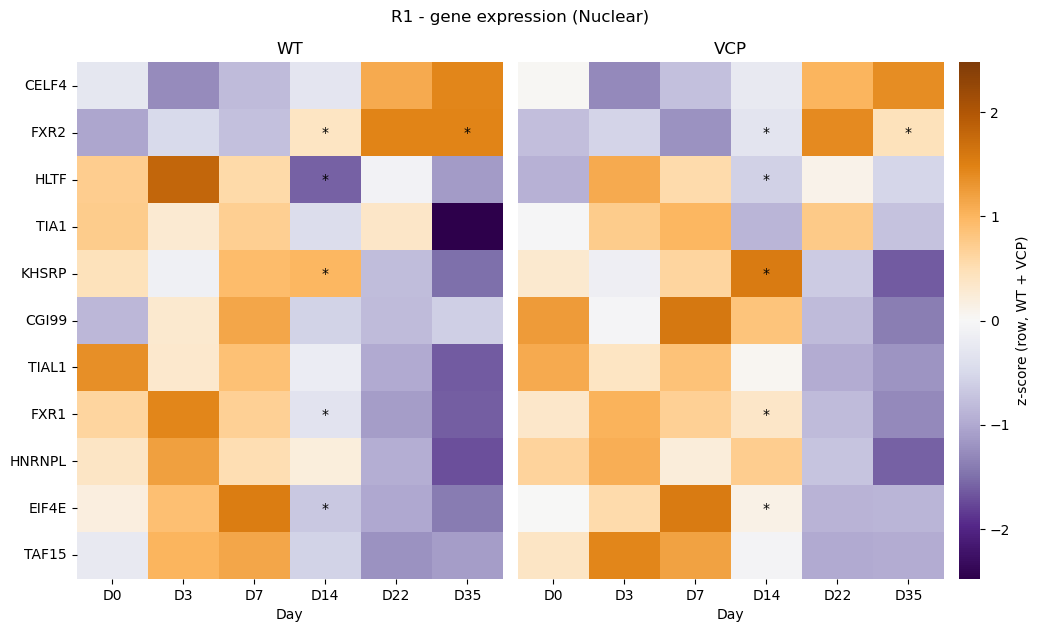

R2 - gene expression (Nuclear)


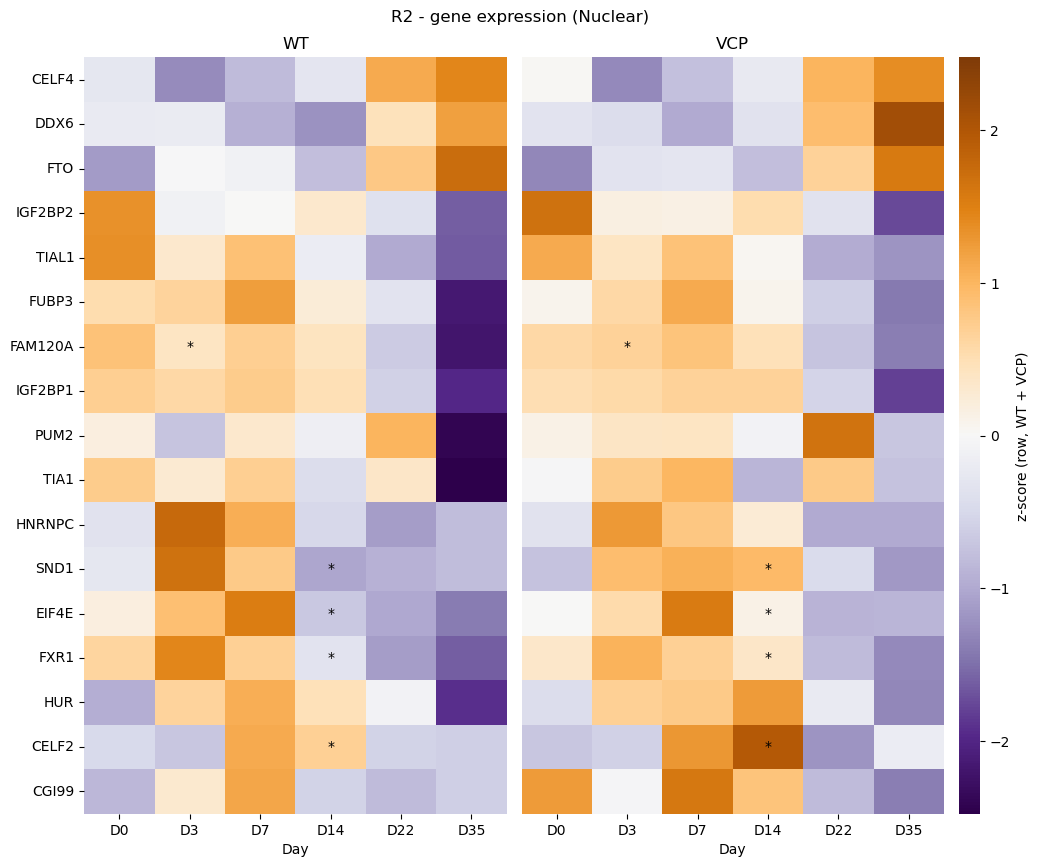

R3 - gene expression (Nuclear)


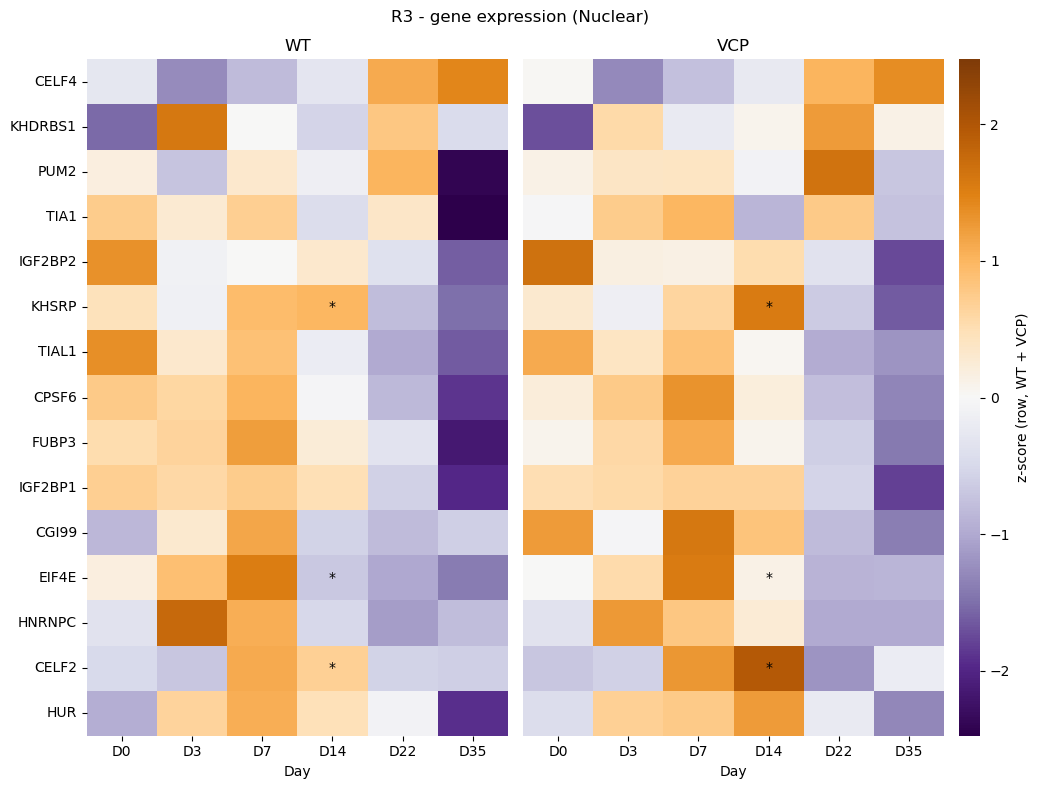

R1 - gene expression (Cytoplasmic)


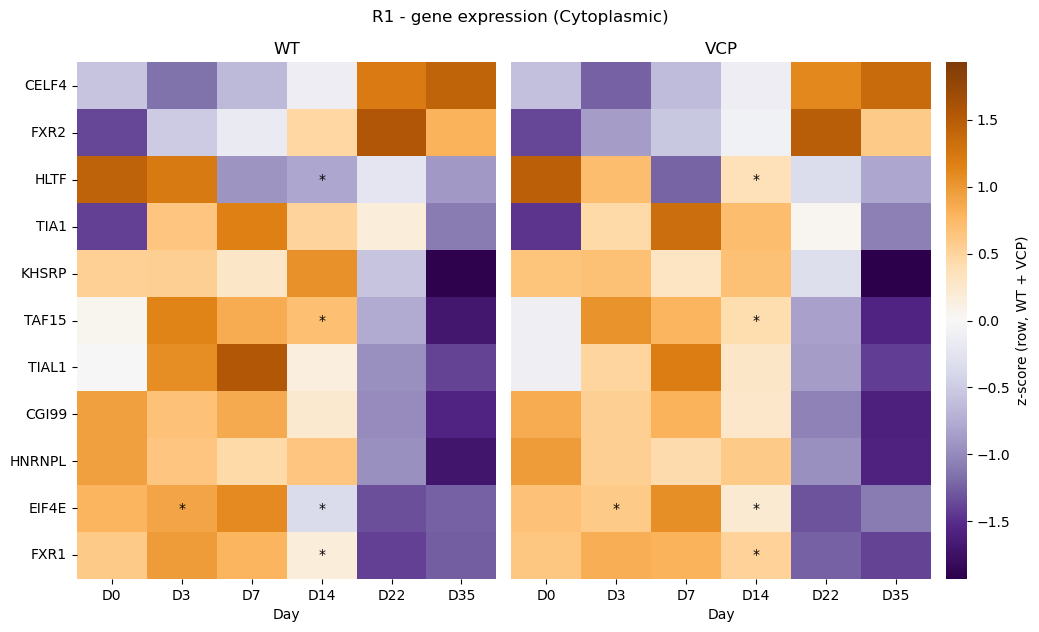

R2 - gene expression (Cytoplasmic)


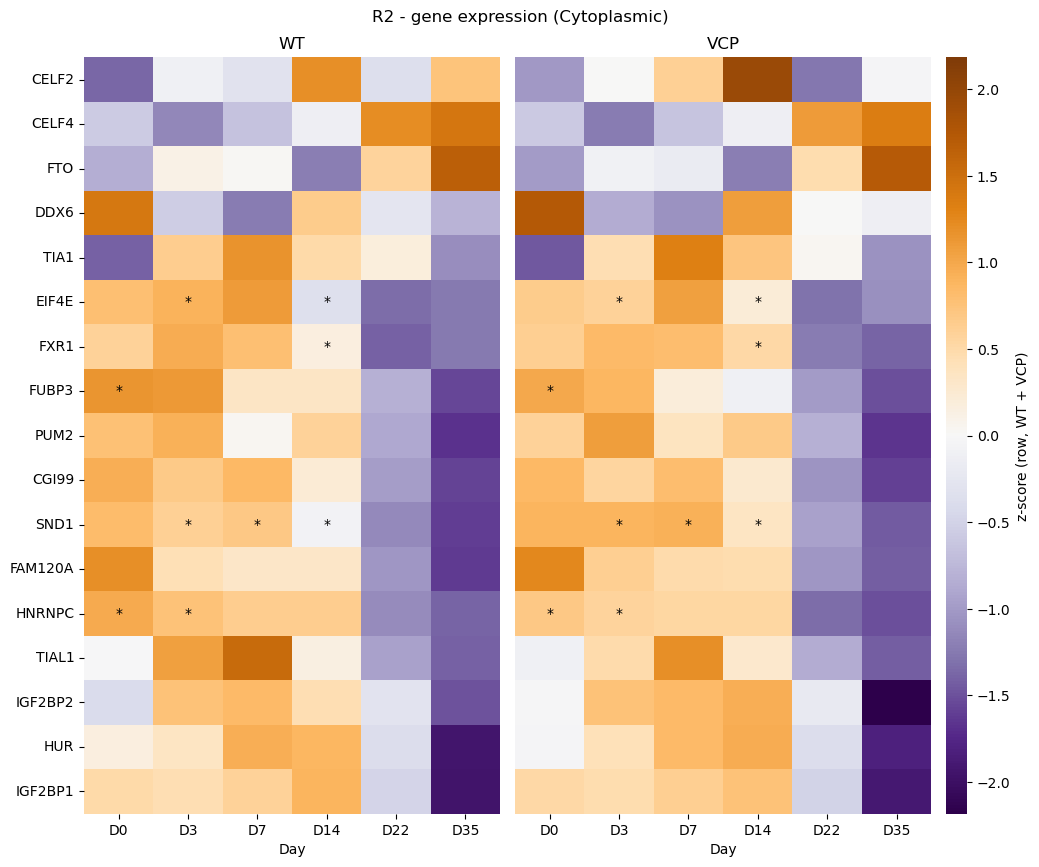

R3 - gene expression (Cytoplasmic)


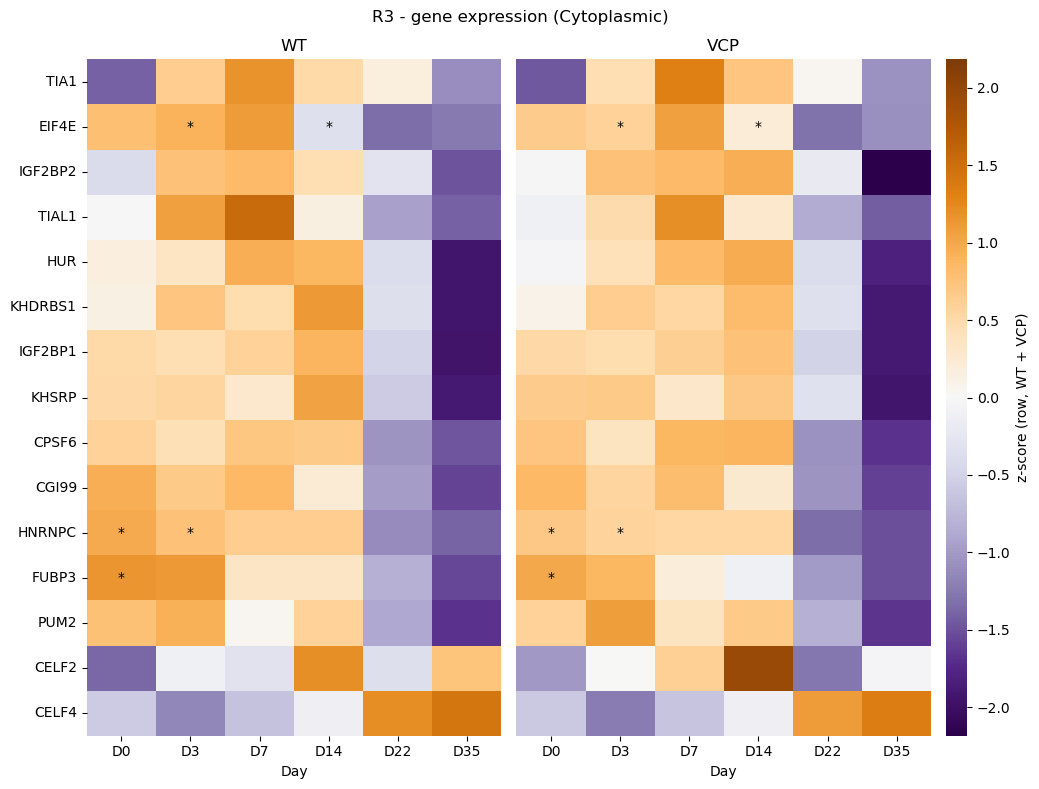

R1 - protein expression (Nuclear)
  not found: ['HLTF', 'CGI99', 'CELF4']
  no nuclear values over time: ['FXR2']


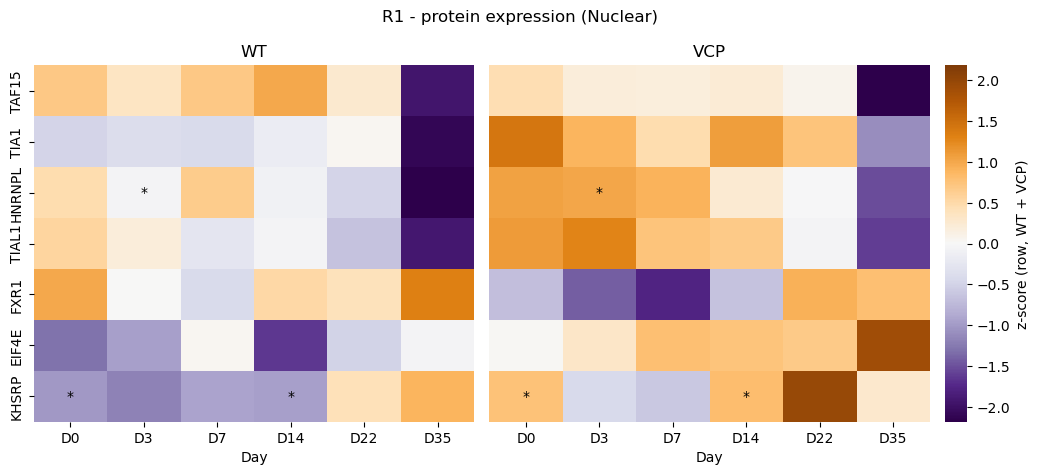

R2 - protein expression (Nuclear)
  not found: ['FTO', 'FAM120A', 'PUM2', 'IGF2BP1', 'CELF2', 'CGI99', 'CELF4']


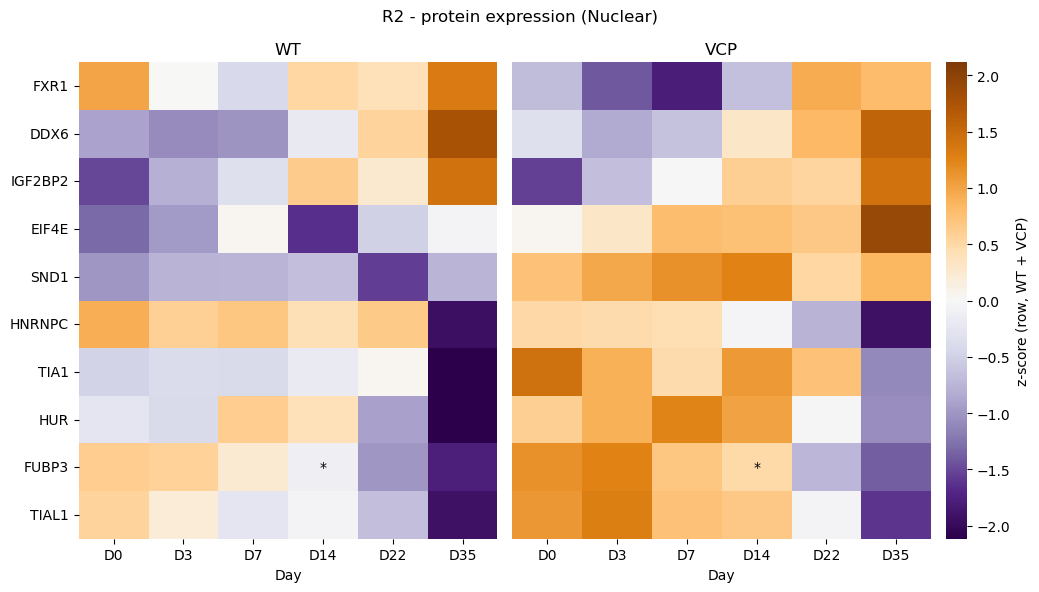

R3 - protein expression (Nuclear)
  not found: ['PUM2', 'IGF2BP1', 'CELF2', 'CGI99', 'CELF4']


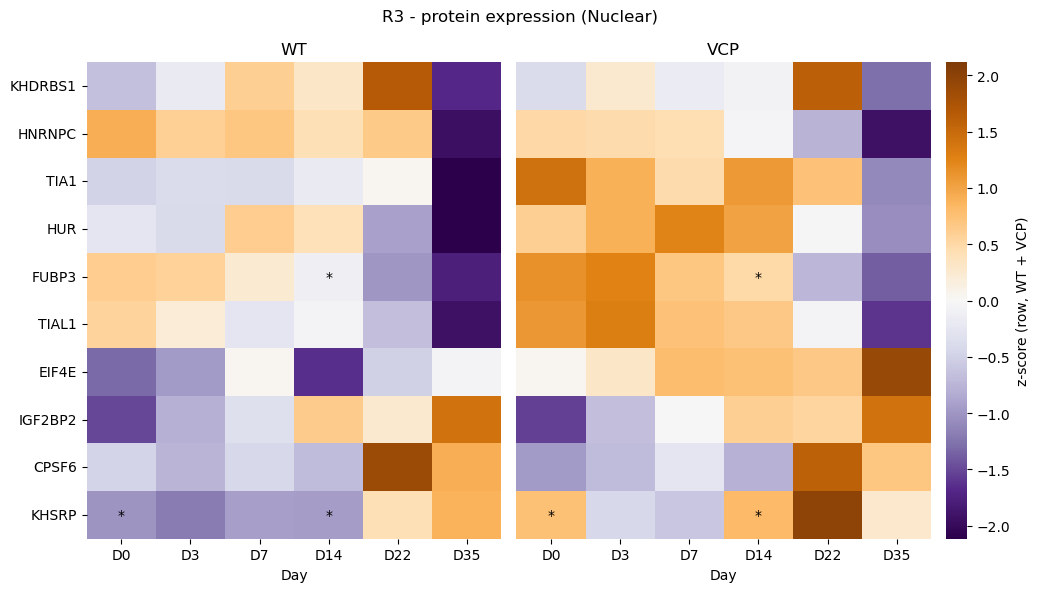

R1 - protein expression (Cytoplasmic)
  not found: ['HLTF', 'CGI99', 'CELF4']
  no cytoplasmic values over time: ['TAF15', 'KHSRP', 'TIA1', 'TIAL1']


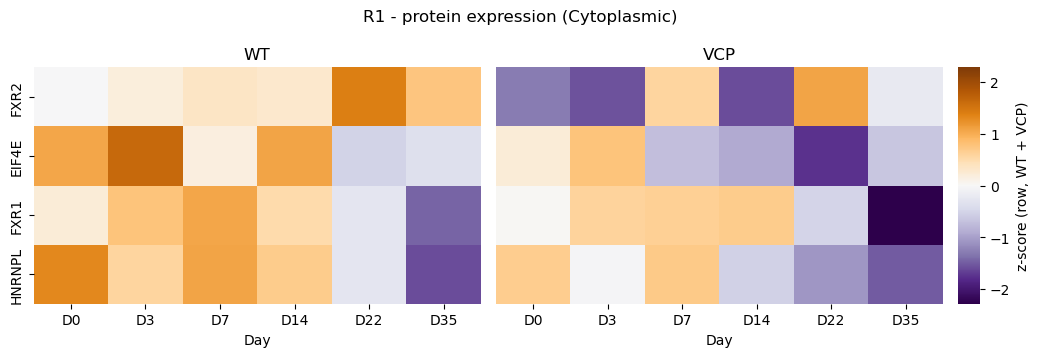

R2 - protein expression (Cytoplasmic)
  not found: ['FTO', 'FAM120A', 'PUM2', 'IGF2BP1', 'CELF2', 'CGI99', 'CELF4']
  no cytoplasmic values over time: ['TIA1', 'TIAL1']


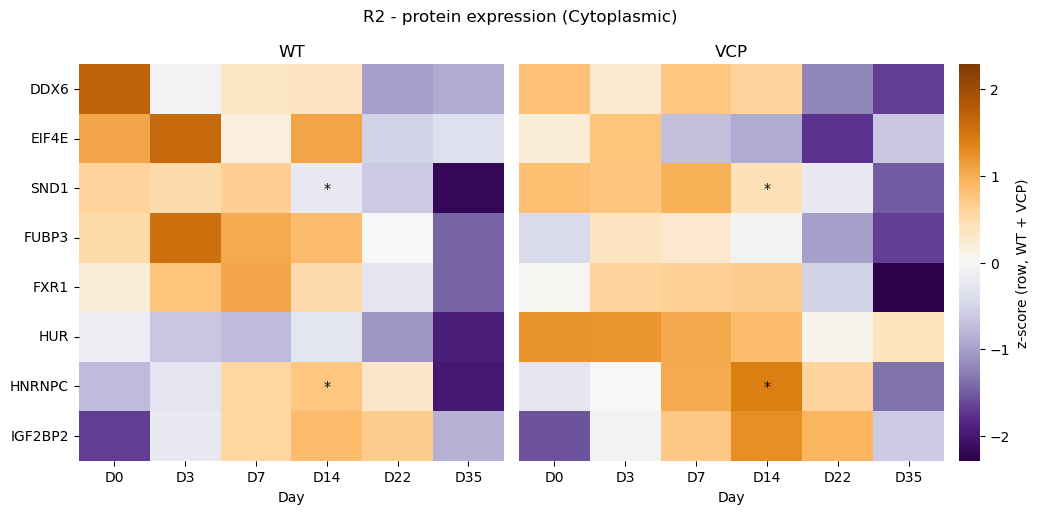

R3 - protein expression (Cytoplasmic)
  not found: ['PUM2', 'IGF2BP1', 'CELF2', 'CGI99', 'CELF4']
  no cytoplasmic values over time: ['KHSRP', 'TIA1', 'TIAL1']


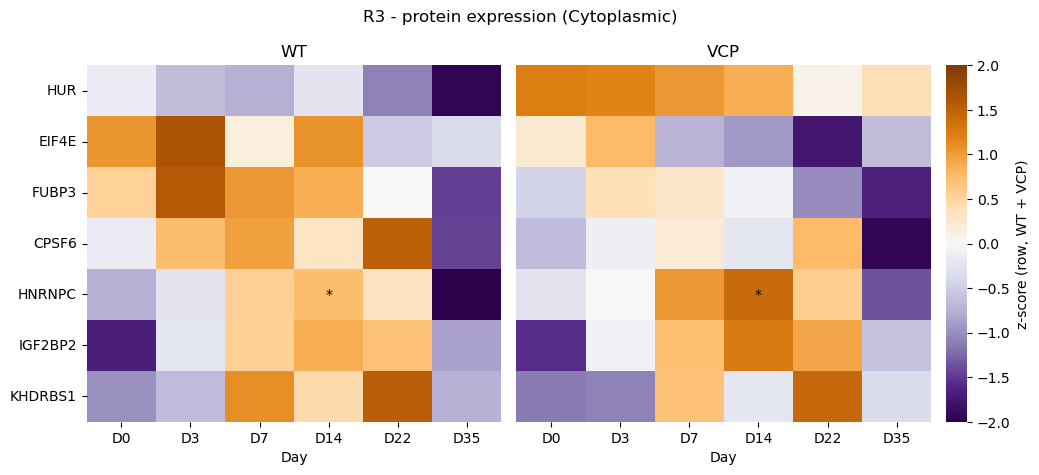

In [15]:
# ---- Gene & protein expression over time for the significant regulators of each region ----
# Same layout as Figure_global_regulators_NuclearWT_D35.ipynb (expression.plot_wt_vs_vcp_heatmap): WT | VCP side by
# side, each row z-scored jointly over WT + VCP (12 columns), '*' = Welch t-test WT vs VCP
# p < 0.05 for that day. Nuclear and cytoplasmic plotted separately.
from utrals.expression import load_expression_metadata
from utrals.expression import plot_wt_vs_vcp_heatmap

expr_path = f"{PROJECT_DIR}/MN_diff/results/genes_preprocessing/df_genes_filtered_normalized.csv"
prot_path = f"{PROTEOMICS_CSV}"
df_genes, meta_genes = load_expression_metadata(expr_path)
df_prot, meta_prot = load_expression_metadata(prot_path)   # already log2 + median-normalised

expression_dir = f"{figures_subfolder}/regulators_expression_CTRL_vs_VCP"
os.makedirs(expression_dir, exist_ok=True)

region_gene_lists = {"R1": genes_sig_region1, "R2": genes_sig_region2, "R3": genes_sig_region3}
datasets = {
    "gene":    (df_genes, meta_genes, "log2_expression"),
    "protein": (df_prot,  meta_prot,  "expression"),        # proteomics is already log2
}

for kind, (df_expr, meta_expr, value_col) in datasets.items():
    for compartment in ["Nuclear", "Cytoplasmic"]:
        for region, genes_list in region_gene_lists.items():
            print(f"{region} - {kind} expression ({compartment})")
            path = f"{expression_dir}/heatmap_{kind}_expression_{compartment}_significant_{region}_regulators_CTRL_vs_VCP.pdf"
            plot_wt_vs_vcp_heatmap(
                genes_list, f"{region} - {kind} expression ({compartment})",
                path,
                df_expr, meta_expr, value_col=value_col, compartment=compartment,
            )
            value_desc = {"gene": "gene expression (log2(normalised counts + 1))",
                          "protein": "protein expression (proteomics GSE152983, log2 median-normalised intensity)"}[kind]
            register_figure(path, legend=f"{compartment} {value_desc} of the {region} regulators of lengthening "
                            "(significant D22 -> D35 change in nuclear CTRL; RNA modifications excluded) over MN "
                            "differentiation, CTRL (left) vs VCP (right). Mean of replicates per day; each row z-scored "
                            "over the 12 columns (6 days x 2 genotypes), so both panels share one scale. Rows clustered "
                            "on the CTRL panel; grey = missing. * = Welch's t-test CTRL vs VCP on replicates, p < 0.05 "
                            "(uncorrected).")


<a id="expression-d35"></a>
## Expression levels of the regulators at D35

Expression **levels** at D35, not row-normalised, so RBPs can be compared with each other: one panel per region, bars = mean, dots = replicates, CTRL and VCP side by side, RBPs sorted by CTRL mean; `*` after a name = Welch's t-test CTRL vs VCP at D35, p < 0.05 (uncorrected). Proteomics intensities are only roughly comparable across proteins.

Saved in `regulators_expression_CTRL_vs_VCP/`: `barplot_{gene,protein}_expression_D35_{Nuclear,Cytoplasmic}_significant_regulators_CTRL_vs_VCP.pdf` (4 files).

gene expression at D35 (Nuclear)


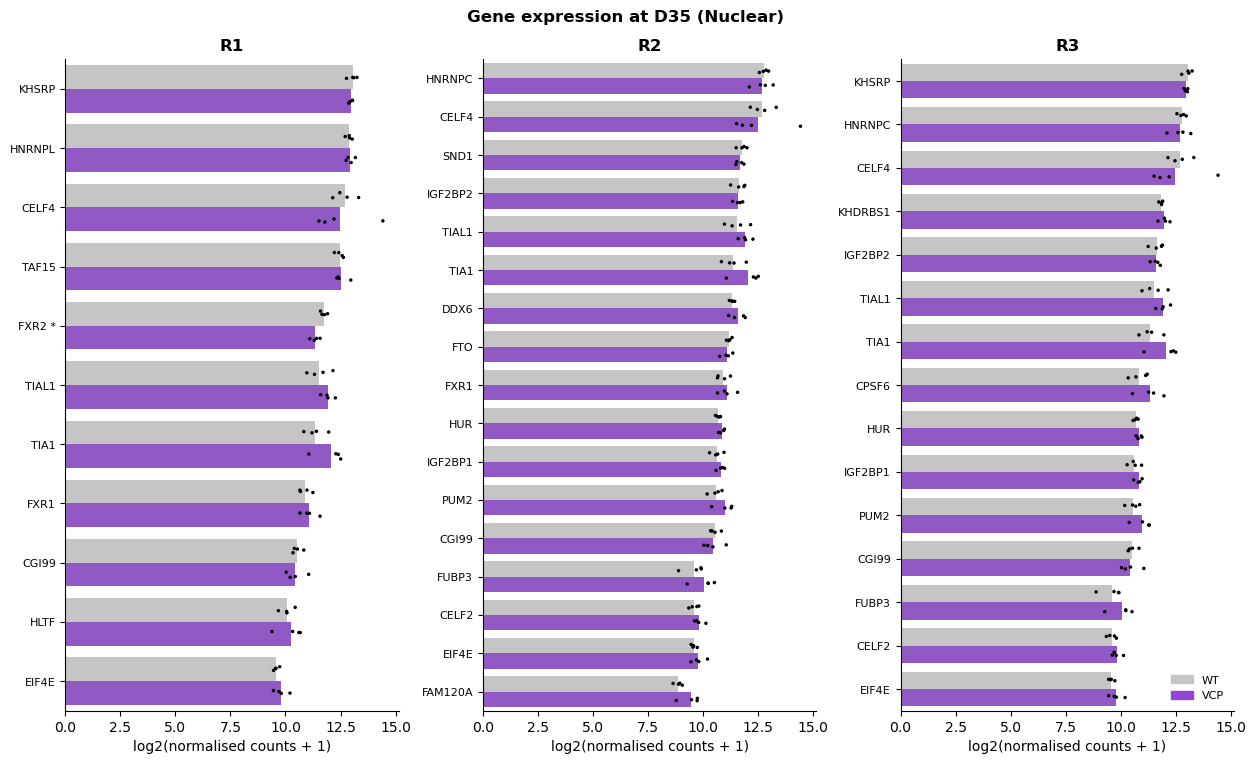

gene expression at D35 (Cytoplasmic)


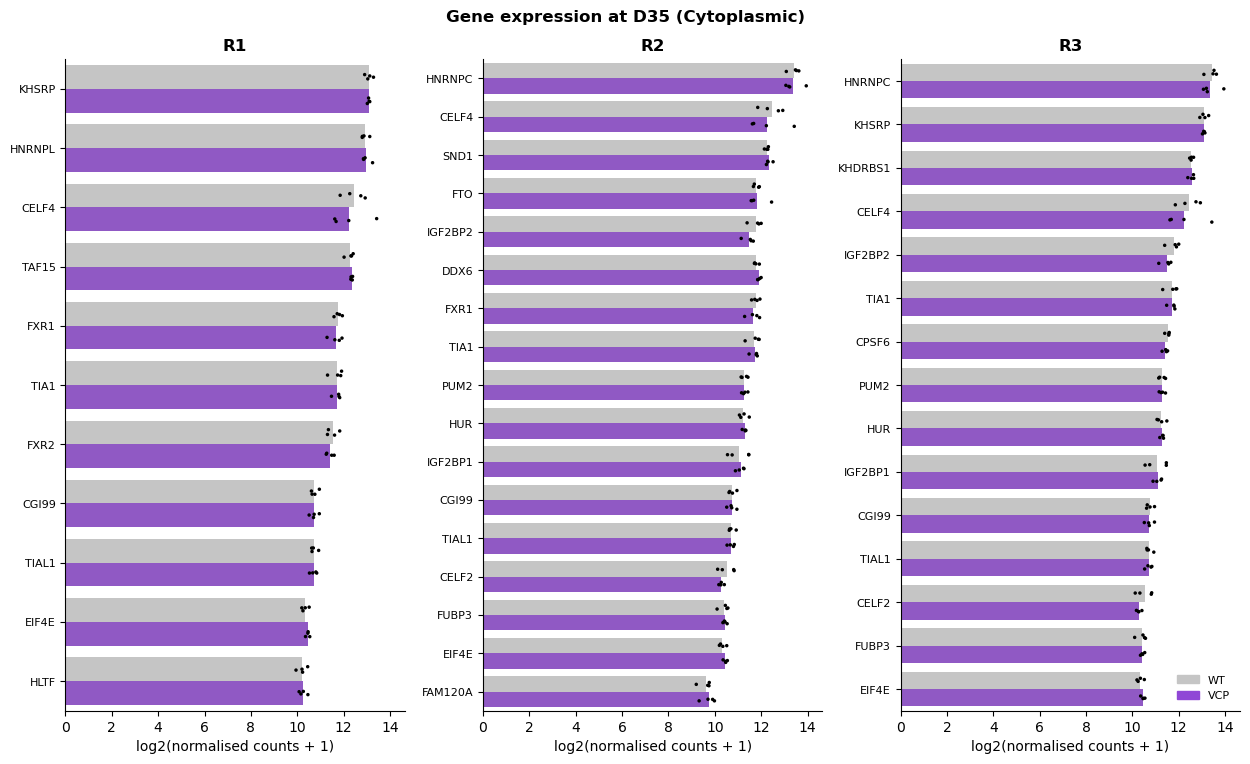

protein expression at D35 (Nuclear)
  not found: ['HLTF', 'CGI99', 'CELF4']
  not found: ['FTO', 'FAM120A', 'PUM2', 'IGF2BP1', 'CELF2', 'CGI99', 'CELF4']
  not found: ['PUM2', 'IGF2BP1', 'CELF2', 'CGI99', 'CELF4']


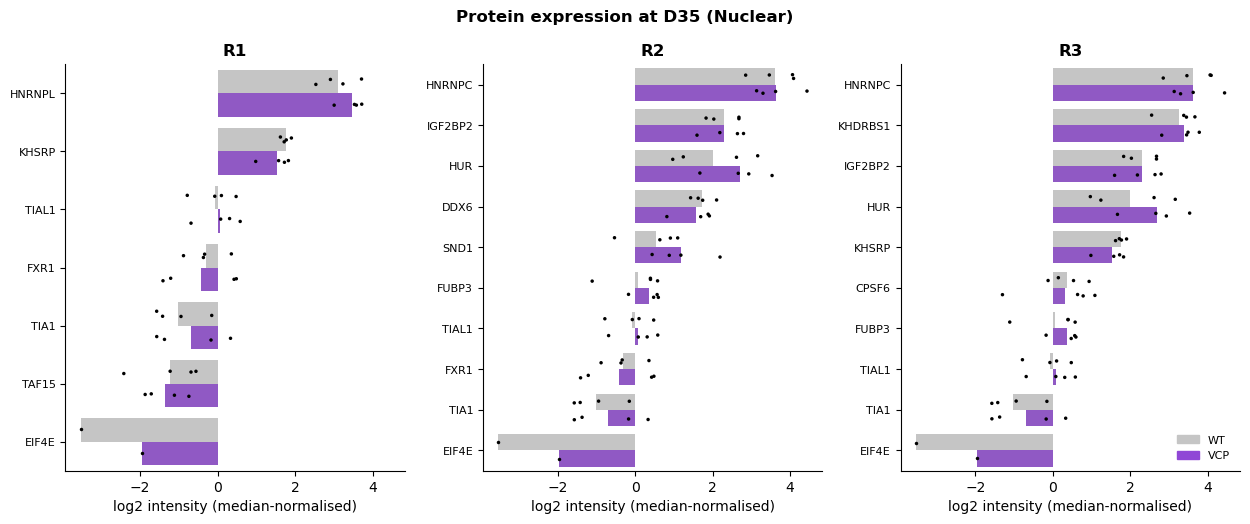

protein expression at D35 (Cytoplasmic)
  not found: ['HLTF', 'CGI99', 'CELF4']
  not found: ['FTO', 'FAM120A', 'PUM2', 'IGF2BP1', 'CELF2', 'CGI99', 'CELF4']
  not found: ['PUM2', 'IGF2BP1', 'CELF2', 'CGI99', 'CELF4']


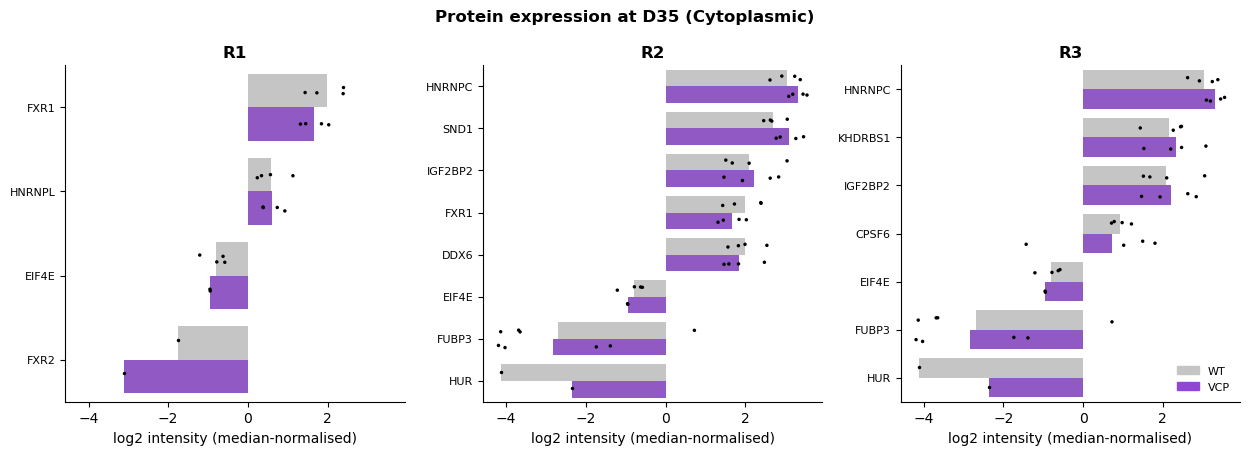

In [16]:
# ---- Expression LEVELS of the significant regulators at D35: which RBPs are most expressed ----
# Not row-normalised (unlike the heatmaps above), so RBPs can be compared with each other.
# Nuclear and cytoplasmic separately; bars = mean, dots = replicates, WT and VCP side by side,
# RBPs sorted by WT mean; '*' after a name = Welch t-test WT vs VCP p < 0.05 at D35.
# Proteomics values are log2 median-normalised intensities: comparable across proteins only
# approximately (label-free intensities also depend on peptide detectability).
from utrals.expression import plot_expression_at_day

value_labels = {"gene": "log2(normalised counts + 1)", "protein": "log2 intensity (median-normalised)"}
expression_d35 = {}
for kind, (df_expr, meta_expr, value_col) in datasets.items():
    for compartment in ["Nuclear", "Cytoplasmic"]:
        print(f"{kind} expression at D35 ({compartment})")
        expression_d35[(kind, compartment)] = plot_expression_at_day(
            region_gene_lists, df_expr, meta_expr, value_col=value_col, compartment=compartment, day=35,
            value_label=value_labels[kind],
            title=f"{kind.capitalize()} expression at D35 ({compartment})",
            save_path=f"{expression_dir}/barplot_{kind}_expression_D35_{compartment}_significant_regulators_CTRL_vs_VCP.pdf",
        )
        register_figure(f"{expression_dir}/barplot_{kind}_expression_D35_{compartment}_significant_regulators_CTRL_vs_VCP.pdf",
                        legend=f"{kind.capitalize()} expression levels at D35 ({compartment} fraction; {value_labels[kind]}) "
                               "of the R1, R2 and R3 regulators of lengthening (one panel per region; RNA modifications "
                               "excluded), not normalised so RBPs can be compared with each other. Bars = mean of "
                               "replicates, dots = replicates, CTRL (grey) and VCP (purple); RBPs sorted by CTRL mean. "
                               "* after a name = Welch's t-test CTRL vs VCP at D35, p < 0.05 (uncorrected).")


<a id="string"></a>
## STRING network and pathway enrichment of the regulators

Uses the STRING helpers of `utrals.string_analysis` (human). The first cell draws plain networks; they are displayed only. The second cell draws one network per region with nodes coloured by the region list(s) each protein belongs to (R1 red, R2 orange, R3 blue; a pie = several lists). Edges: experiments or databases evidence with max(escore, dscore) ≥ 0.4; isolated proteins sit on an outer ring. The same cell then runs KEGG / Reactome / GO BP enrichment of the three lists, shown as one bubble plot (union of the top 10 terms per region; Jaccard ≥ 0.5 duplicates collapsed; size = −log10(FDR), colour = STRING signal). The enrichment background is the whole genome (`background_rbps` is built but not passed).

Saved: `regulators_STRING_networks/STRING_network_significant_R{1,2,3}_regulators.pdf` and `regulators_pathway_enrichment/bubble_enrichment_significant_regulators_genome_background.pdf`.

  R1 (proximal promoter binding) — no qualifying interactions: ['EIF4E', 'HLTF', 'KHSRP', 'TIA1']


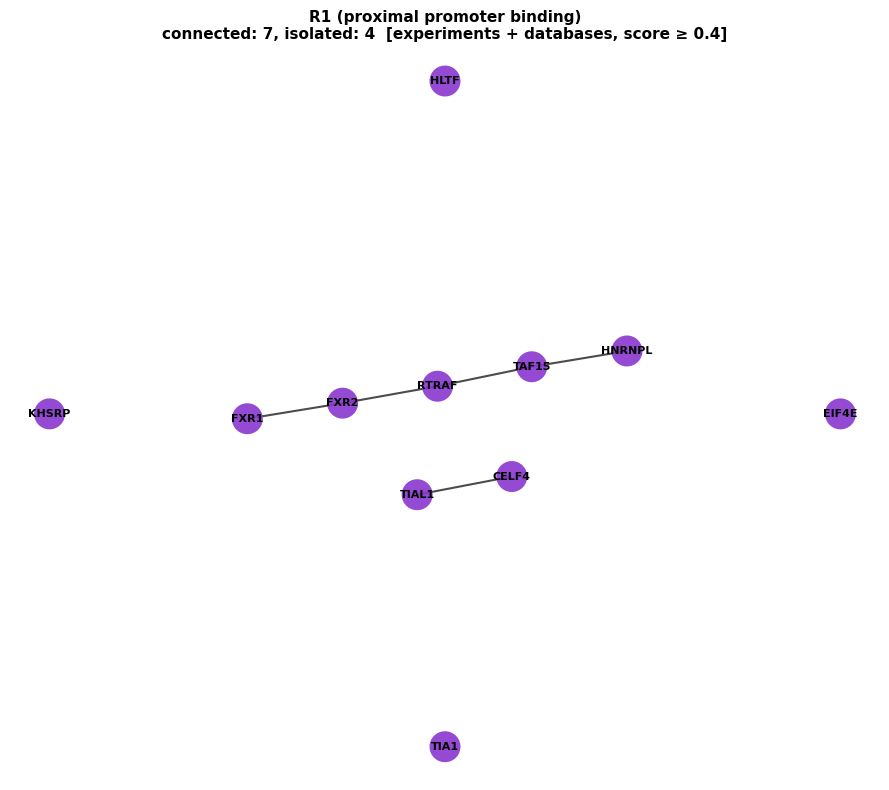

R1 (proximal promoter binding): 5 interactions found

  R2 (proximal depletion) — no qualifying interactions: ['RTRAF', 'FTO', 'FUBP3', 'PUM2', 'TIA1']


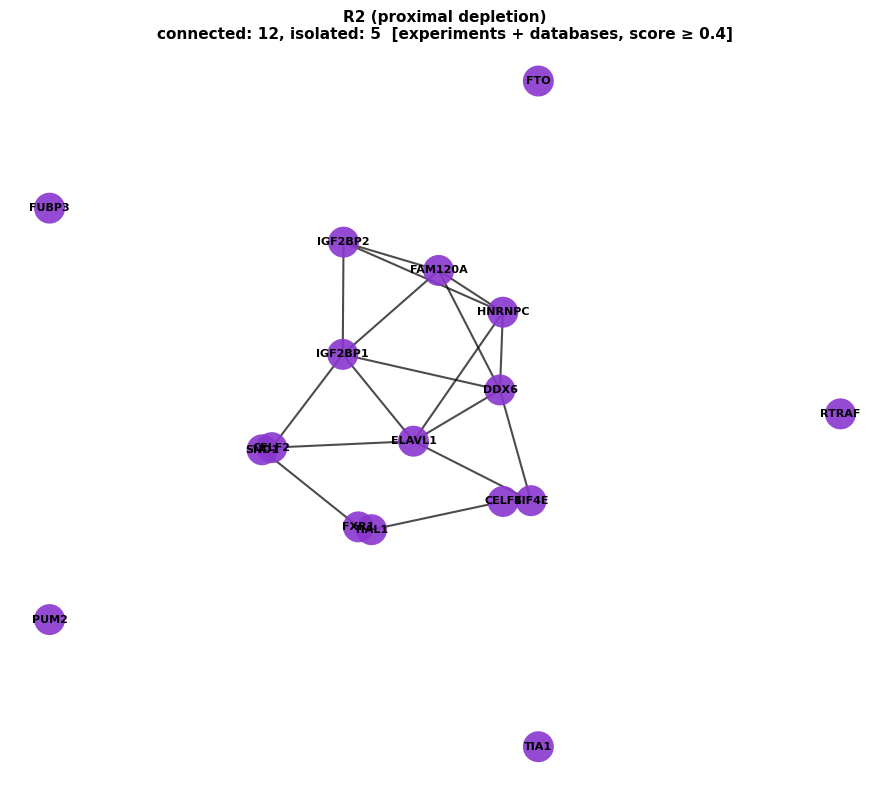

R2 (proximal depletion): 17 interactions found



  R3 (distal binding) — no qualifying interactions: ['RTRAF', 'PUM2', 'TIA1']


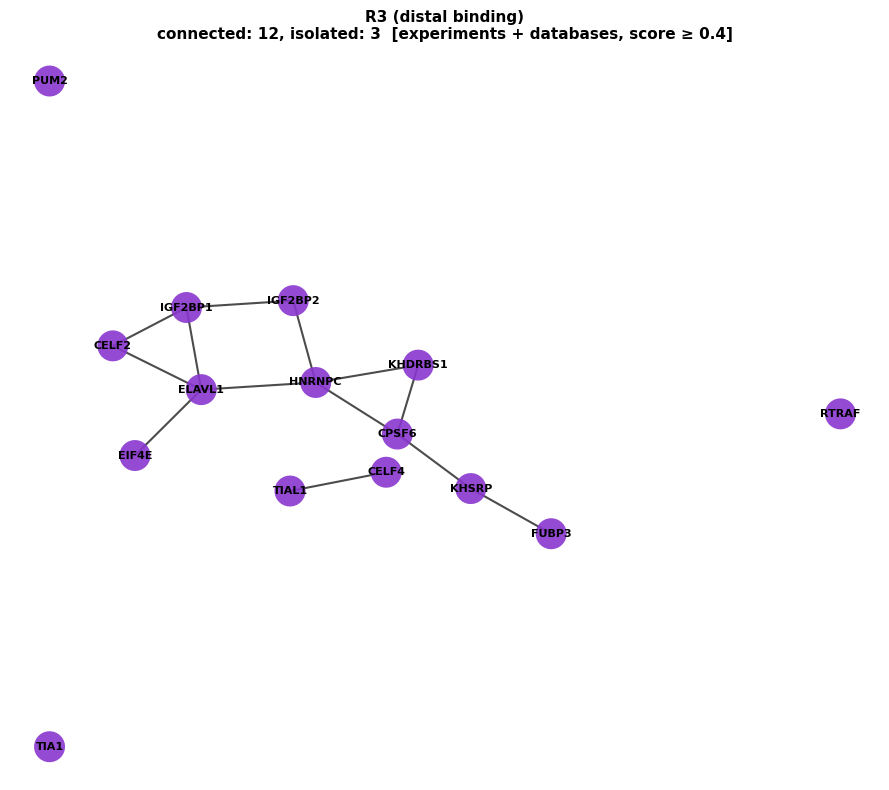

R3 (distal binding): 13 interactions found



In [17]:
from utrals.string_analysis import plot_string_network, plot_enrichment_combined

region_genes = {
    "R1 (proximal promoter binding)": genes_sig_region1,
    "R2 (proximal depletion)": genes_sig_region2,
    "R3 (distal binding)": genes_sig_region3,
}

network_dir = f"{figures_subfolder}/regulators_STRING_networks"
os.makedirs(network_dir, exist_ok=True)

string_networks = {}
for region_name, genes in region_genes.items():
    fig, ax = plt.subplots(figsize=(9, 8))
    G, df_net = plot_string_network(genes, region_name,  ax=ax)
    string_networks[region_name] = (G, df_net)
    plt.tight_layout()
    safe_name = region_name.split(" ")[0]
    # not saved: the next cell saves the same network with nodes coloured by region
    plt.show()
    print(f"{region_name}: {len(df_net)} interactions found\n")

  R1 (proximal promoter binding) — no qualifying interactions: ['EIF4E', 'HLTF', 'KHSRP', 'TIA1']


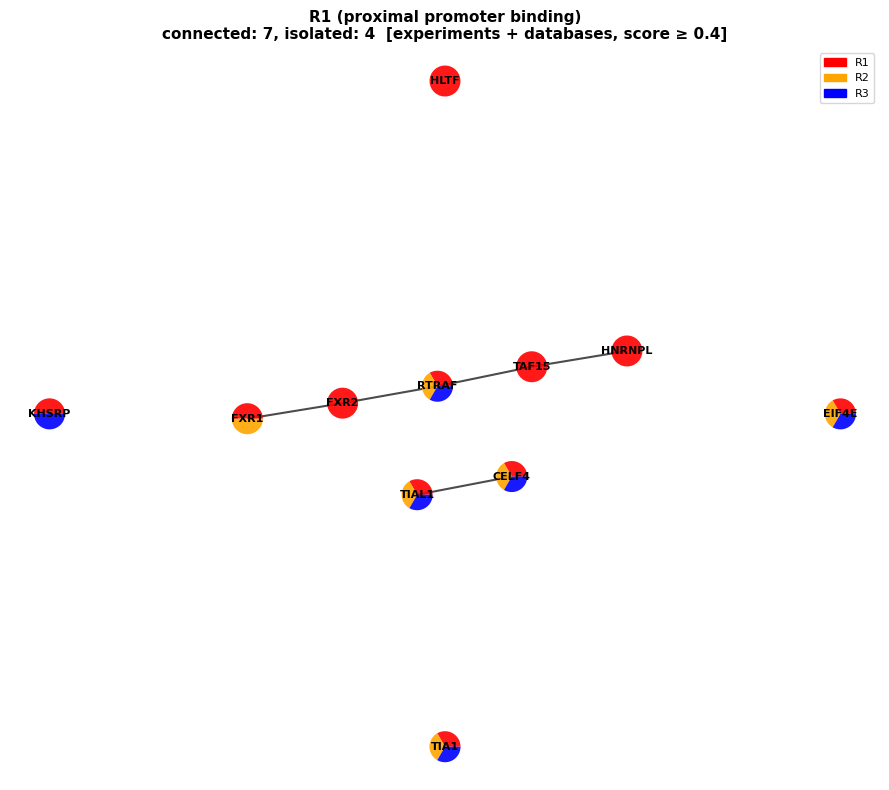

R1 (proximal promoter binding): 5 interactions found

  R2 (proximal depletion) — no qualifying interactions: ['RTRAF', 'FTO', 'FUBP3', 'PUM2', 'TIA1']


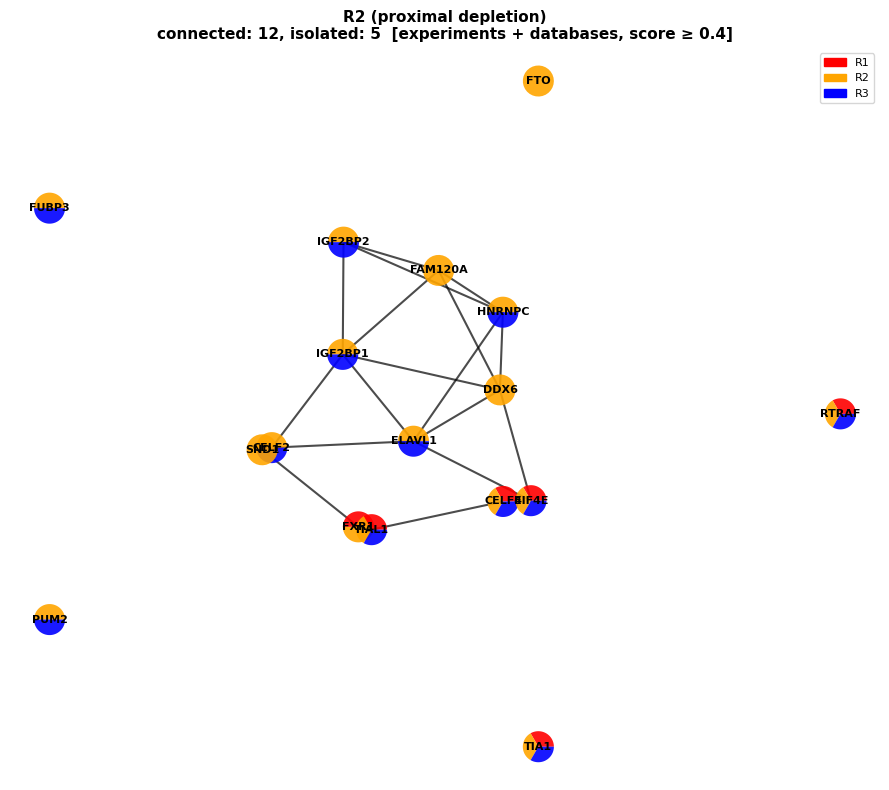

R2 (proximal depletion): 17 interactions found

  R3 (distal binding) — no qualifying interactions: ['RTRAF', 'PUM2', 'TIA1']


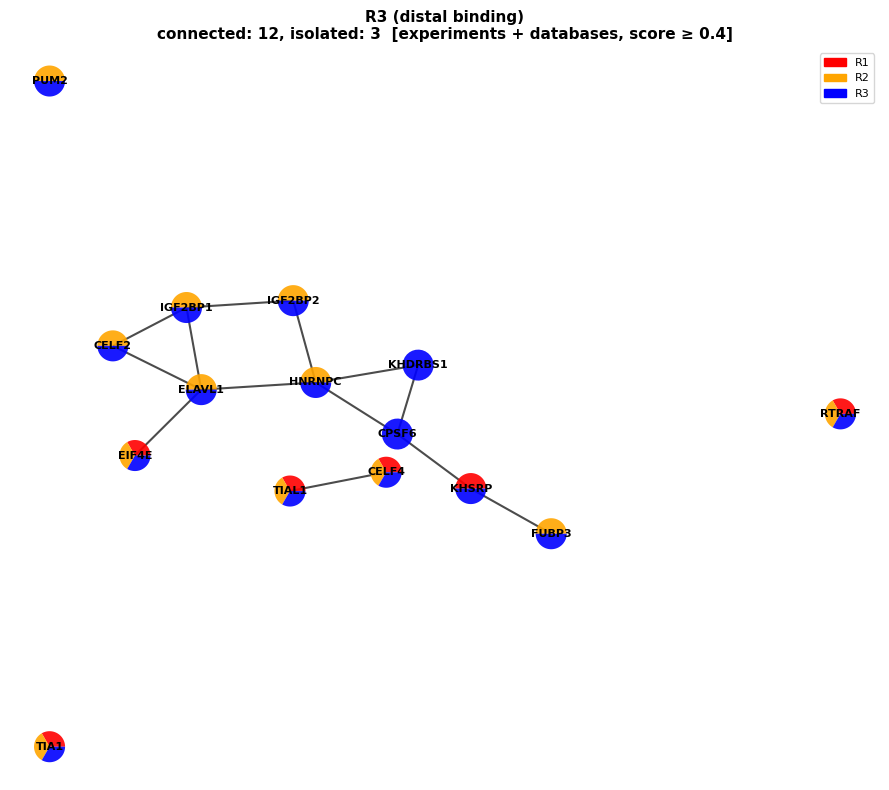

R3 (distal binding): 13 interactions found



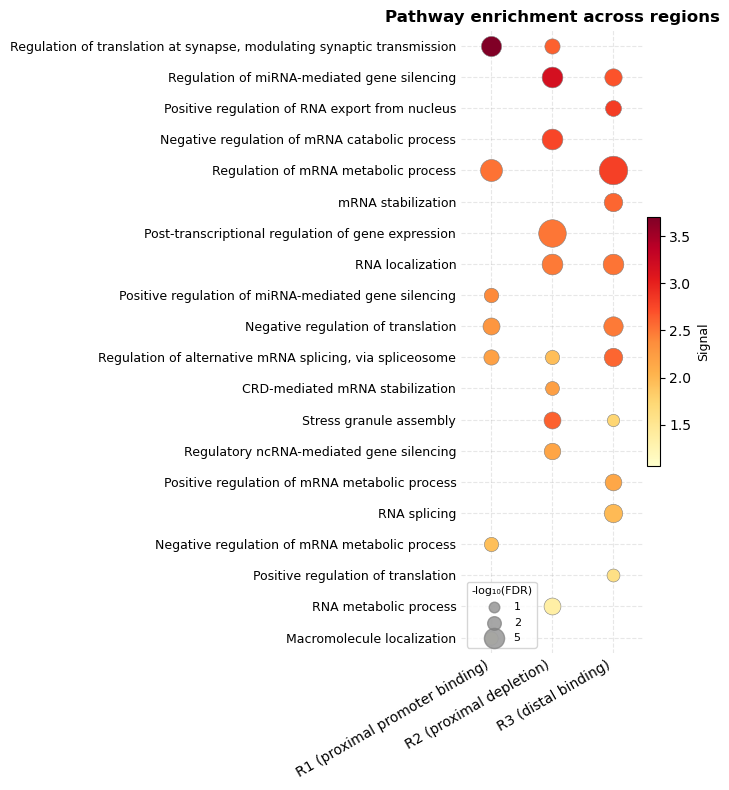

,region,description,log_fdr,signal
0,R1 (proximal promoter binding),Regulation of mRNA metabolic process,6.007005,2.521346
1,R1 (proximal promoter binding),"Regulation of translation at synapse, modulati...",4.974694,3.702975
2,R1 (proximal promoter binding),Negative regulation of translation,3.408935,2.302434
3,R1 (proximal promoter binding),"Regulation of alternative mRNA splicing, via s...",2.638272,2.201213
4,R1 (proximal promoter binding),Positive regulation of miRNA-mediated gene sil...,2.327902,2.397768
5,R1 (proximal promoter binding),Negative regulation of mRNA metabolic process,2.244125,1.938435
6,R1 (proximal promoter binding),Macromolecule localization,1.896196,1.057789
7,R2 (proximal depletion),Post-transcriptional regulation of gene expres...,9.774691,2.494695
8,R2 (proximal depletion),RNA localization,5.324222,2.481279
9,R2 (proximal depletion),Regulation of miRNA-mediated gene silencing,5.322393,3.170879


In [18]:
from utrals.string_analysis import build_node_colors
from utrals.string_analysis import GROUP_COLORS


region_genes = {
    "R1 (proximal promoter binding)": genes_sig_region1,
    "R2 (proximal depletion)": genes_sig_region2,
    "R3 (distal binding)": genes_sig_region3,
}

network_dir = f"{figures_subfolder}/regulators_STRING_networks"
os.makedirs(network_dir, exist_ok=True)

group_lists = {"R1": genes_sig_region1, "R2": genes_sig_region2, "R3": genes_sig_region3}
all_genes = set(genes_sig_region1) | set(genes_sig_region2) | set(genes_sig_region3)
node_colors = build_node_colors(all_genes, group_lists)

legend_handles = [mpatches.Patch(color=color, label=label)
                   for label, color in GROUP_COLORS.items()]

string_networks = {}
for region_name, genes in region_genes.items():
    fig, ax = plt.subplots(figsize=(9, 8))
    G, df_net = plot_string_network(genes, region_name, ax=ax, node_colors=node_colors)
    ax.legend(handles=legend_handles, loc="upper right", fontsize=8, frameon=True)
    string_networks[region_name] = (G, df_net)
    plt.tight_layout()
    safe_name = region_name.split(" ")[0]
    save_figure(f"{network_dir}/STRING_network_significant_{safe_name}_regulators.pdf",
                legend=f"STRING protein-protein interaction network of the {safe_name} regulators of lengthening "
                       "(significant D22 -> D35 change in nuclear CTRL; RNA modifications excluded). Edges: experiments "
                       "or databases evidence with max(escore, dscore) >= 0.4; proteins without such an edge sit on the "
                       "outer ring. Node colour = region list(s) the protein belongs to (R1 red, R2 orange, R3 blue; a "
                       "pie = several lists).")
    plt.show()
    print(f"{region_name}: {len(df_net)} interactions found\n")


enrichment_dir = f"{figures_subfolder}/regulators_pathway_enrichment"
os.makedirs(enrichment_dir, exist_ok=True)

# Background = all other RBPs analyzed here (top-15 vs. the rest of the panel),
# instead of the whole genome/proteome.
background_rbps = [rbp.split('_')[0] for rbp in data_scaled.index.tolist()]
background_rbps = ["TARDBP" if "TDP43" in rbp else rbp for rbp in background_rbps]

fig, ax = plt.subplots(figsize=(7, 8))
df_enrich_combined = plot_enrichment_combined(
    region_genes,
    top_n=10,
    categories=("KEGG", "Reactome", "Process"),
    background_genes=None,
    jaccard_threshold=0.5,
    ax=ax,
)
plt.tight_layout()
save_figure(f"{enrichment_dir}/bubble_enrichment_significant_regulators_genome_background.pdf",
            legend="STRING enrichment (KEGG, Reactome, GO Biological Process) of the R1, R2 and R3 regulators of "
                   "lengthening (columns; significant D22 -> D35 change in nuclear CTRL; RNA modifications "
                   "excluded), against the whole-genome background. Rows = union of the 10 most significant terms (FDR) of each "
                   "region; near-duplicate terms (gene-set Jaccard >= 0.5) collapsed to the most significant "
                   "one. Bubble size = -log10(FDR); colour = STRING signal (harmonic mean of strength = "
                   "log10(observed/expected) and -log10(FDR)).")
plt.show()
df_enrich_combined

<a id="apa-vs-nr"></a>
## APA vs nuclear retention: nuclear vs cytoplasmic activity at D35

For the regulators of each region (`sig_region{1,2,3}`), the next three cells take the maximum region score in CTRL at D35, separately in the nuclear and cytoplasmic fractions. R1: max Welch score in [−350, −50] upstream of the pPAS. R2: max of the sign-flipped score over all bins downstream of the pPAS (0 to +200). R3: max of the sign-flipped score in [−350, −50] upstream of the dPAS. With a threshold of −log10(0.05), each regulator is classified as:
- **APA**: significant in both fractions;
- **Nuclear retention**: significant in the nucleus only;
- **Ambiguous**: anything else (ambiguous modifications are dropped).

This gives `class_df_R{1,2,3}` (RBPs) and `df_cat_modif_R{1,2,3}` (modifications). The scatter plots then show the nuclear vs cytoplasmic maximum (RBPs black, modifications dark blue, APA quadrant pink, nuclear-retention quadrant green), with the Pearson r within each group. The classification is written to `../Tables/Figure_regulators_lengthening/regulators_of_nuclear_3UTR_lengthening_D22_to_D35_CTRL_<region>_APA_vs_nuclear_retention_class.csv` (`<region>` = `region1_upstream_pPAS`, `region2_downstream_pPAS` or `region3_upstream_dPAS`), and the last cell prints the R2 lists.

Saved: `regulators_APA_vs_nuclear_retention/scatter_nuclear_vs_cytoplasmic_welch_D35_CTRL_significant_R{1,2,3}_regulators.pdf`.

In [19]:

# candidates_lengthening = p_mat_all[p_mat_all['Region 2'] < 0.05].index.tolist()


proximal_filtered = proximal[(proximal["Day"] == "D35") & (proximal["VCP"] == "Wildtype")]
records = []
for CLIP in sig_region1+modifs:
    
    clip = proximal_filtered[proximal_filtered['regulator'] == CLIP]
    nuc  = clip[(clip['Compartment'] == 'Nuclear')     & (clip['dist'] >= positive_proximal_region[0]) & (clip['dist'] <= positive_proximal_region[1])]
    cyto = clip[(clip['Compartment'] == 'Cytoplasmic') & (clip['dist'] >= positive_proximal_region[0]) & (clip['dist'] <= positive_proximal_region[1])]

    if nuc.empty or cyto.empty:
        continue
    
    nuc['mean_score_lg10'] = nuc['mean_score_lg10']
    cyto['mean_score_lg10'] = cyto['mean_score_lg10']
    
    
    nuclear_max = nuc['mean_score_lg10'].max()
    cyto_max    = cyto['mean_score_lg10'].max()

    if nuclear_max > -np.log10(0.05) and cyto_max > -np.log10(0.05):
        category = 'APA'
    elif nuclear_max > -np.log10(0.05) and cyto_max < -np.log10(0.05):
        category = 'Nuclear retention'
    else:
        category = 'Ambiguous'

    records.append({
        'regulator': CLIP,
        'RBP': get_RBP_name(CLIP),
        'nuclear_max': nuclear_max,
        'cyto_max': cyto_max,
        'category': category,
        'nuc_cyto_diff': nuclear_max - cyto_max,  # more negative = larger nuc-specific effect
    })

class_df_R1 = pd.DataFrame(records)

df_cat_modif_R1 = class_df_R1[class_df_R1['regulator'].isin(modifs)]
# df_cat_modif_R1 = df_cat_modif_R1[~(df_cat_modif_R1['category'] == 'Ambiguous')]

class_df_R1 = class_df_R1[~class_df_R1['regulator'].isin(modifs)]

In [20]:

proximal_filtered = proximal[(proximal["Day"] == "D35") & (proximal["VCP"] == "Wildtype")]
records = []
for CLIP in sig_region2+modifs:
    clip = proximal_filtered[proximal_filtered['regulator'] == CLIP]
    nuc  = clip[(clip['Compartment'] == 'Nuclear')     & (clip['dist'] >= negative_proximal_region[0])]
    cyto = clip[(clip['Compartment'] == 'Cytoplasmic') & (clip['dist'] >= negative_proximal_region[0])]

    if nuc.empty or cyto.empty:
        continue
    
    nuc['mean_score_lg10'] = -nuc['mean_score_lg10']
    cyto['mean_score_lg10'] = -cyto['mean_score_lg10']
    
    
    nuclear_max = nuc['mean_score_lg10'].max()
    cyto_max    = cyto['mean_score_lg10'].max()

    if nuclear_max > -np.log10(0.05) and cyto_max > -np.log10(0.05):
        category = 'APA'
    elif nuclear_max > -np.log10(0.05) and cyto_max < -np.log10(0.05):
        category = 'Nuclear retention'
    else:
        category = 'Ambiguous'

    records.append({
        'regulator': CLIP,
        'RBP': get_RBP_name(CLIP),
        'nuclear_max': nuclear_max,
        'cyto_max': cyto_max,
        'category': category,
        'nuc_cyto_diff': nuclear_max - cyto_max,  # more negative = larger nuc-specific effect
    })

class_df_R2 = pd.DataFrame(records)

df_cat_modif_R2 = class_df_R2[class_df_R2['regulator'].isin(modifs)]
# df_cat_modif_R2 = df_cat_modif_R2[~(df_cat_modif_R2['category'] == 'Ambiguous')]

class_df_R2 = class_df_R2[~class_df_R2['regulator'].isin(modifs)]



In [21]:

distal_filtered = distal[(distal["Day"] == "D35") & (distal["VCP"] == "Wildtype")]
records = []
for CLIP in sig_region3+modifs:
    clip = distal_filtered[distal_filtered['regulator'] == CLIP]
    nuc  = clip[(clip['Compartment'] == 'Nuclear')     & (clip['dist'] >= positive_distal_region[0]) & (clip['dist'] <= positive_distal_region[1])]
    cyto = clip[(clip['Compartment'] == 'Cytoplasmic') & (clip['dist'] >= positive_distal_region[0]) & (clip['dist'] <= positive_distal_region[1])]

    if nuc.empty or cyto.empty:
        continue
    
    nuc['mean_score_lg10'] = -nuc['mean_score_lg10']
    cyto['mean_score_lg10'] = -cyto['mean_score_lg10']
    
    
    nuclear_max = nuc['mean_score_lg10'].max()
    cyto_max    = cyto['mean_score_lg10'].max()

    if nuclear_max > -np.log10(0.05) and cyto_max > -np.log10(0.05):
        category = 'APA'
    elif nuclear_max > -np.log10(0.05) and cyto_max < -np.log10(0.05):
        category = 'Nuclear retention'
    else:
        category = 'Ambiguous'

    records.append({
        'regulator': CLIP,
        'RBP': get_RBP_name(CLIP),
        'nuclear_max': nuclear_max,
        'cyto_max': cyto_max,
        'category': category,
        'nuc_cyto_diff': nuclear_max - cyto_max,  # more negative = larger nuc-specific effect
    })

class_df_R3 = pd.DataFrame(records)

df_cat_modif_R3 = class_df_R3[class_df_R3['regulator'].isin(modifs)]
# df_cat_modif_R3 = df_cat_modif_R3[~(df_cat_modif_R3['category'] == 'Ambiguous')]

class_df_R3 = class_df_R3[~class_df_R3['regulator'].isin(modifs)]

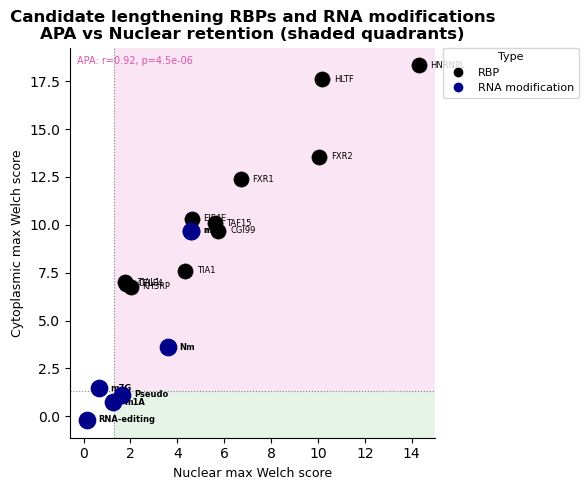

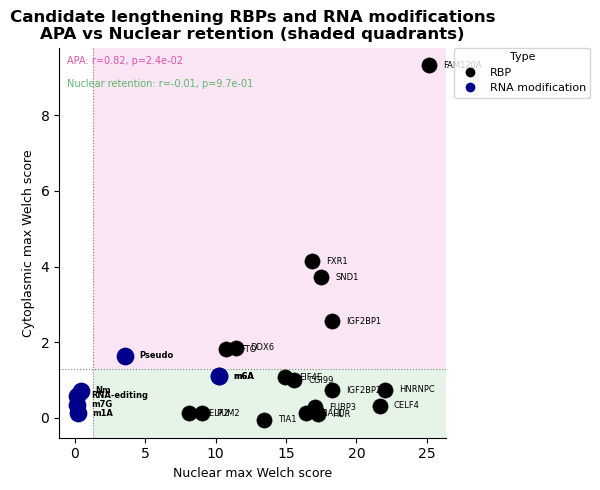

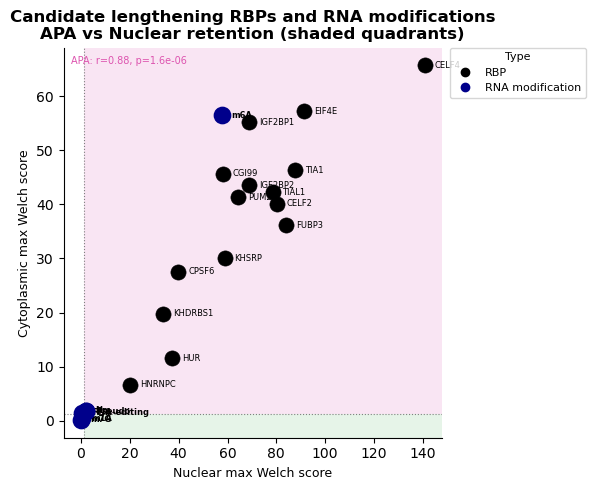

In [22]:
# Black-and-white markers, quadrants shaded by category instead
palette = {'APA': '#dd54af', 'Nuclear retention': '#5cb76b', 'Ambiguous': '#aaaaaa'}
thr = -np.log10(0.05)



for region, class_df, modif_df, x_delay in zip(["R1", "R2", "R3"],
                                      [class_df_R1, class_df_R2, class_df_R3],
                                      [df_cat_modif_R1, df_cat_modif_R2, df_cat_modif_R3],
                                      [0.5, 1, 4]):
        
        corrs = {}
        for cat in ['APA', 'Nuclear retention']:
                sub = pd.concat([
                        class_df[class_df['category'] == cat][['nuclear_max', 'cyto_max']],
                        modif_df[modif_df['category'] == cat][['nuclear_max', 'cyto_max']],
                ])
                if len(sub) > 1:
                        r, p = pearsonr(sub['nuclear_max'], sub['cyto_max'])
                        corrs[cat] = (r, p)
        
        fig, ax = plt.subplots(figsize=(6, 5))

        for _, row in class_df.iterrows():
                ax.scatter(row['nuclear_max'], row['cyto_max'], color='black', s=120, zorder=3,
                        edgecolors='black', linewidths=0.4, marker='o')
                ax.text(row['nuclear_max'] + x_delay, row['cyto_max'], row['RBP'],
                        fontsize=6, va='center', color='black')

        for _, row in modif_df.iterrows():
                ax.scatter(row['nuclear_max'], row['cyto_max'], color='darkblue', s=120, zorder=4,
                        marker='o', linewidths=1.8)
                ax.text(row['nuclear_max'] + x_delay, row['cyto_max'], row['RBP'],
                        fontsize=6, va='center', color='black', fontweight='bold')

        # Quadrant threshold lines
        ax.axvline(thr, color='grey', linestyle=':', linewidth=0.8)
        ax.axhline(thr, color='grey', linestyle=':', linewidth=0.8)

        xlim = ax.get_xlim()
        ylim = ax.get_ylim()

        # Shade APA (top-right) in pink and Nuclear retention (bottom-right) in green
        ax.add_patch(mpatches.Rectangle((thr, thr), xlim[1] - thr, ylim[1] - thr,
                                        facecolor='#dd54af', alpha=0.15, zorder=0, linewidth=0))
        ax.add_patch(mpatches.Rectangle((thr, ylim[0]), xlim[1] - thr, thr - ylim[0],
                                        facecolor='#5cb76b', alpha=0.15, zorder=0, linewidth=0))
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)

        marker_handles = [
        Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markeredgecolor='black',
                markersize=6, label='RBP'),
        Line2D([0], [0], marker='o', color='darkblue', markersize=6, linewidth=0, label='RNA modification'),
        ]
        ax.legend(handles=marker_handles, title='Type', fontsize=8, title_fontsize=8,
                loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)

        for i, (cat, (r, p)) in enumerate(corrs.items()):
                ax.text(0.02, 0.98 - i * 0.06, f'{cat}: r={r:.2f}, p={p:.1e}',
                        transform=ax.transAxes, fontsize=7, color=palette[cat],
                        va='top', ha='left')

        ax.set_xlabel('Nuclear max Welch score', fontsize=9)
        ax.set_ylabel('Cytoplasmic max Welch score', fontsize=9)
        ax.set_title('Candidate lengthening RBPs and RNA modifications\nAPA vs Nuclear retention (shaded quadrants)', weight='bold')
        sns.despine(ax=ax)
        plt.tight_layout()

        region_window = {"R1": "max Welch score in [-350, -50] nt upstream of the pPAS",
                         "R2": "max of the sign-flipped Welch score in all bins from 0 to +200 nt downstream of the pPAS (depletion)",
                         "R3": "max of the sign-flipped Welch score in [-350, -50] nt upstream of the dPAS"}[region]
        save_figure(f"{figures_subfolder}/regulators_APA_vs_nuclear_retention/scatter_nuclear_vs_cytoplasmic_welch_D35_CTRL_significant_{region}_regulators.pdf",
                    legend=f"{region} regulators of lengthening (significant D22 -> D35 change in nuclear CTRL; RBPs in "
                           f"black, RNA modifications in dark blue): {region_window}, in the nuclear (x) vs cytoplasmic (y) "
                           "fraction of CTRL motor neurons at D35. Dotted lines = -log10(0.05). Pink quadrant = APA "
                           "(significant in both fractions), green = nuclear retention (nucleus only); modifications in "
                           "neither are not shown. Pearson r within the APA and nuclear-retention groups at the top left.")
        plt.show()

In [23]:
# Read by the Figure_m6A_* notebooks, scripts/ and the m6a_regions pipeline step (path: figures.lengthening_regulators_csv)
for k, class_df in {1: class_df_R1, 2: class_df_R2, 3: class_df_R3}.items():
    save_table(class_df, figures.lengthening_regulators_csv(k), pattern="regulators_of_nuclear_3UTR_lengthening_D22_to_D35_CTRL_<region>_APA_vs_nuclear_retention_class.csv",
               legend="Regulators of nuclear 3'UTR lengthening of one region (file name: region1_upstream_pPAS = R1, "
                      "region2_downstream_pPAS = R2, region3_upstream_dPAS = R3): CLIP datasets whose Welch score in the "
                      "region changes significantly between D22 and D35 in the nuclear fraction of CTRL motor neurons "
                      "(one-sided z-test, p < 0.05, one CLIP per RBP; RNA modifications excluded), with their APA / "
                      "nuclear-retention class: regulator (CLIP dataset), RBP, nuclear_max and cyto_max = maximum Welch "
                      "score at D35 in CTRL in the nuclear and cytoplasmic fractions (R1: [-350, -50] upstream of the "
                      "pPAS; R2: sign-flipped, every bin downstream of the pPAS, 0 to +200; R3: sign-flipped, [-350, -50] "
                      "upstream of the dPAS), category (APA = both > -log10(0.05), Nuclear retention = nucleus only, "
                      "Ambiguous = otherwise) and nuc_cyto_diff = nuclear_max - cyto_max. Candidate RBP lists of the "
                      "m6A-switch analyses.")

In [24]:
print(f"Nuclear retention candidates R2: {class_df_R2[class_df_R2['category'] == 'Nuclear retention'].RBP.values}")
print(f"APA candidates R2: {class_df_R2[class_df_R2['category'] == 'APA'].RBP.values}")

Nuclear retention candidates R2: ['HNRNPC' 'PUM2' 'HUR' 'CELF2' 'IGF2BP2' 'FUBP3' 'CGI99' 'EIF4E' 'TIA1'
 'TIAL1' 'CELF4']
APA candidates R2: ['FTO' 'DDX6' 'SND1' 'FAM120A' 'FXR1' 'IGF2BP1']


<a id="apa-vs-nr-string"></a>
### STRING enrichment of the R2 APA vs nuclear-retention regulators

The R2 regulators of lengthening (`class_df_R2`, ambiguous ones left out) are split into **APA** and **Nuclear retention** RBPs and each list is run through STRING enrichment (GO Biological Process only; whole-genome background). STRING is pinned to v12.5 and its raw responses are read from `cache/STRING_v12.5_responses/regulators_lengthening_R2_{APA,nuclear_retention}.json.gz` (saved on the first query, 2026-10-21), so the result does not drift. Bubble plot: one column per class; rows = union of the 10 most significant non-redundant terms (Jaccard ≥ 0.5) of each class; size = −log10(FDR), colour = STRING signal.

Saved: `regulators_pathway_enrichment/bubble_enrichment_R2_regulators_APA_vs_nuclear_retention_genome_background.pdf`; table `STRING_enrichment_R2_regulators_of_lengthening_APA_vs_nuclear_retention.csv`.

APA (6 RBPs): DDX6, FAM120A, FTO, FXR1, IGF2BP1, SND1
Nuclear retention (11 RBPs): CELF2, CELF4, EIF4E, ELAVL1, FUBP3, HNRNPC, IGF2BP2, PUM2, RTRAF, TIA1, TIAL1


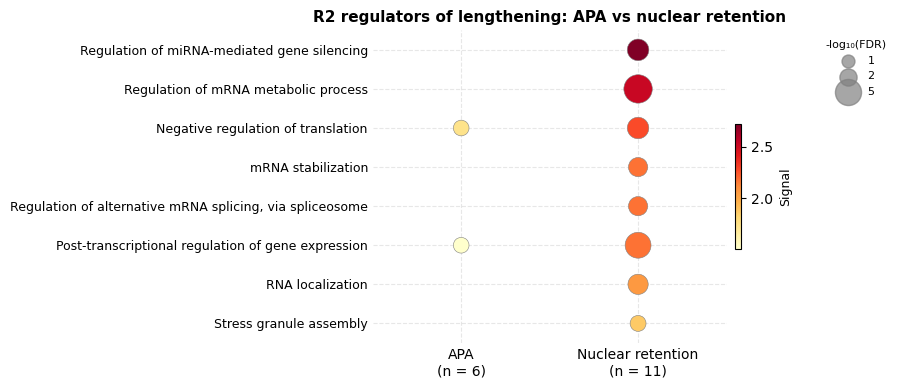

,class,description,number_of_genes,fdr,inputGenes
0,APA,Post-transcriptional regulation of gene expres...,4,2.420000e-02,"[IGF2BP1, FXR1, FTO, DDX6]"
1,APA,Negative regulation of translation,3,2.420000e-02,"[IGF2BP1, FXR1, DDX6]"
2,Nuclear retention,Regulation of mRNA metabolic process,7,9.840000e-07,"[PUM2, ELAVL1, TIA1, IGF2BP2, CELF4, HNRNPC, C..."
3,Nuclear retention,Post-transcriptional regulation of gene expres...,7,1.210000e-05,"[PUM2, ELAVL1, TIA1, IGF2BP2, CELF4, EIF4E, HN..."
4,Nuclear retention,Regulation of miRNA-mediated gene silencing,3,4.700000e-04,"[PUM2, TIAL1, ELAVL1]"
5,Nuclear retention,Negative regulation of translation,4,5.100000e-04,"[TIA1, IGF2BP2, CELF4, EIF4E]"
6,Nuclear retention,RNA localization,4,1.300000e-03,"[RTRAF, FUBP3, IGF2BP2, EIF4E]"
7,Nuclear retention,"Regulation of alternative mRNA splicing, via s...",3,2.700000e-03,"[TIA1, CELF4, CELF2]"
8,Nuclear retention,mRNA stabilization,3,2.700000e-03,"[ELAVL1, IGF2BP2, HNRNPC]"
9,Nuclear retention,Stress granule assembly,2,2.130000e-02,"[PUM2, TIA1]"


In [25]:
from utrals import string_api
from utrals.string_api import get_string_enrichment_cached, add_strength_and_signal
from utrals.rbp_names import RBP_TO_SYMBOL
from utrals.string_analysis import dedupe_redundant_terms

# Pinned STRING release; raw responses saved in the repository on the first query and read back afterwards
string_api.STRING_API = "https://version-12-5.string-db.org/api/json"
string_responses_dir = "../cache/STRING_v12.5_responses"

class_genes_R2 = {
    category: sorted({RBP_TO_SYMBOL.get(rbp, rbp) for rbp in class_df_R2.loc[class_df_R2["category"] == category, "RBP"]})
    for category in ["APA", "Nuclear retention"]
}
cache_tags = {"APA": "APA", "Nuclear retention": "nuclear_retention"}
enrich_categories = ["Process"]  # GO Biological Process only

enrich_R2_class = {}
for category, genes in class_genes_R2.items():
    cache = f"{string_responses_dir}/regulators_lengthening_R2_{cache_tags[category]}.json.gz"
    df_e = add_strength_and_signal(get_string_enrichment_cached(genes, cache, query_if_missing=False))
    df_e = df_e[df_e["category"].isin(enrich_categories)].copy()
    df_e["log_fdr"] = -np.log10(df_e["fdr"])
    df_e["term_label"] = df_e["description"]
    enrich_R2_class[category] = df_e
    print(f"{category} ({len(genes)} RBPs): {', '.join(genes)}")

# Rows: union of the 10 most significant non-redundant terms of each class
top_n = 10
rows_terms = set()
for df_e in enrich_R2_class.values():
    rows_terms |= set(dedupe_redundant_terms(df_e, jaccard_threshold=0.5).sort_values("fdr").head(top_n)["term_label"])

df_plot_R2_class = pd.concat([df_e[df_e["term_label"].isin(rows_terms)].assign(**{"class": category})
                              for category, df_e in enrich_R2_class.items()], ignore_index=True)
order = df_plot_R2_class.groupby("term_label")["signal"].max().sort_values().index.tolist()
class_names = list(enrich_R2_class)

fig, ax = plt.subplots(figsize=(5.5, 0.32 * len(order) + 1.5))
norm_color = plt.Normalize(df_plot_R2_class["signal"].min(), df_plot_R2_class["signal"].max())
norm_size = plt.Normalize(0, df_plot_R2_class["log_fdr"].max())
cmap = plt.cm.YlOrRd
ax.scatter(df_plot_R2_class["class"].map(class_names.index), df_plot_R2_class["term_label"].map(order.index),
           s=norm_size(df_plot_R2_class["log_fdr"]) * 400 + 20, c=cmap(norm_color(df_plot_R2_class["signal"])),
           edgecolors="grey", linewidths=0.4, zorder=3)
ax.set_xticks(range(len(class_names)))
ax.set_xticklabels([f"{c}\n(n = {len(class_genes_R2[c])})" for c in class_names], fontsize=10)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order, fontsize=9)
ax.set_xlim(-0.5, len(class_names) - 0.5)
ax.set_ylim(-0.5, len(order) - 0.5)
ax.grid(linestyle="--", alpha=0.3)
sns.despine(ax=ax, left=True, bottom=True)
ax.tick_params(length=0)
ax.set_title("R2 regulators of lengthening: APA vs nuclear retention", fontsize=11, weight="bold")
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm_color)
cbar = plt.colorbar(sm, ax=ax, pad=0.02, shrink=0.4)
cbar.set_label("Signal", fontsize=9)
size_handles = [plt.scatter([], [], s=norm_size(v) * 400 + 20, c="grey", edgecolors="grey", alpha=0.7, label=str(v))
                for v in [1, 2, 5, 8] if v <= df_plot_R2_class["log_fdr"].max()]
ax.legend(handles=size_handles, title="-log₁₀(FDR)", loc="upper left", bbox_to_anchor=(1.25, 1),
          fontsize=8, title_fontsize=8, frameon=False)
save_figure(f"{enrichment_dir}/bubble_enrichment_R2_regulators_APA_vs_nuclear_retention_genome_background.pdf",
            legend="STRING v12.5 enrichment (GO Biological Process) of the R2 regulators of lengthening (significant D22 -> D35 change in nuclear CTRL; RNA modifications "
                   "and ambiguous regulators excluded), split into APA (significant in nucleus and cytoplasm at D35) "
                   "and nuclear retention (nucleus only) RBPs (columns), against the whole-genome background. Rows = "
                   "union of the 10 most significant terms (FDR) of each class, near-duplicate terms (gene-set Jaccard "
                   ">= 0.5) collapsed to the most significant one; no bubble "
                   "= term not enriched (FDR >= 0.05). Bubble size = -log10(FDR); colour = STRING signal (harmonic "
                   "mean of strength = log10(observed/expected) and -log10(FDR)).")
plt.show()

save_table(df_plot_R2_class[["class", "category", "term", "description", "number_of_genes",
                             "number_of_genes_in_background", "strength", "signal", "fdr", "inputGenes"]]
           .sort_values(["class", "fdr"]),
           f"{tables_subfolder}/STRING_enrichment_R2_regulators_of_lengthening_APA_vs_nuclear_retention.csv",
           index=False,
           legend="STRING v12.5 enrichment (whole-genome background) of the R2 regulators of lengthening split into "
                  "APA and nuclear-retention RBPs, for the terms of the bubble plot "
                  "bubble_enrichment_R2_regulators_APA_vs_nuclear_retention_genome_background.pdf: one row per class "
                  "and enriched GO Biological Process term (FDR < 0.05): class, category (Process = GO BP), term ID, description, number of input / background genes, strength = "
                  "log10(observed/expected), signal (harmonic mean of strength and -log10(FDR)), FDR and the input "
                  "genes annotated to the term.")
df_plot_R2_class[["class", "description", "number_of_genes", "fdr", "inputGenes"]].sort_values(["class", "fdr"])


<a id="ctrl-vs-vcp-activity"></a>
## Regulator activity in CTRL vs VCP at D35, per region and fraction

For every regulator (CLIP dataset or RNA modification), condition (CTRL = `Wildtype`, VCP) and fraction, the next cells take the region score at D35 (`df_max`):
- **R1**: max Welch score in [−350, −50] upstream of the pPAS;
- **R2**: max of the sign-flipped Welch score in [0, +150] downstream of the pPAS (positive = depletion near the pPAS);
- **R3**: max of the sign-flipped Welch score in [−350, −50] upstream of the dPAS.

`barplot_CTRL_VCP_activity` draws, for one regulator, these scores in CTRL (`Wildtype`, blue) and VCP (yellow) for R1–R3 (columns) in the nuclear (top) and cytoplasmic (bottom) fractions. Each bar is a single value (one Welch score per condition, no replicates), each panel has its own y axis. It is drawn for m6A and for every regulator of lengthening of R1, R2 or R3 (RBPs only, the modifications are left out of `class_df_R{1,2,3}`). The last cell summarises them: one boxplot panel per region (own y axis) of the nuclear D35 activity, in that region, of its own regulators (`class_df_R{1,2,3}`), CTRL vs VCP, with a paired Wilcoxon signed-rank test. The next one does the same for R2 only, split into APA and nuclear-retention regulators (`category` in `class_df_R2`; ambiguous ones left out).

Saved: `regulators_CTRL_vs_VCP_activity_D35/barplot_welch_R1_R2_R3_CTRL_vs_VCP_D35_m6A.pdf` , `regulators_CTRL_vs_VCP_activity_D35/boxplot_max_welch_R1_R2_R3_regulators_CTRL_vs_VCP_D35_nuclear.pdf`, `regulators_CTRL_vs_VCP_activity_D35/boxplot_max_welch_R2_regulators_APA_vs_NR_CTRL_vs_VCP_D35_nuclear.pdf` and `regulators_CTRL_vs_VCP_activity_D35/lengthening_regulators/barplot_welch_R1_R2_R3_CTRL_vs_VCP_D35_<regulator>.pdf`.

In [26]:
R1  = proximal[(proximal['dist'] >= positive_proximal_region[0]) & (proximal['dist'] <= positive_proximal_region[1])]
R1_max = R1.groupby(["Compartment", "VCP", "regulator", "Day"]).max().reset_index()

R2  = proximal[(proximal['dist'] >= negative_proximal_region[0]) & (proximal['dist'] <= negative_proximal_region[1])]
R2['mean_score_lg10'] = -R2['mean_score_lg10']
R2_max = R2.groupby(["Compartment", "VCP", "regulator", "Day"]).max().reset_index()

R3  = distal[(distal['dist'] >= positive_distal_region[0]) & (distal['dist'] <= positive_distal_region[1])]
R3['mean_score_lg10'] = -R3['mean_score_lg10']
R3_max = R3.groupby(["Compartment", "VCP", "regulator", "Day"]).max().reset_index()

In [27]:
df_max = R1_max.merge(R2_max[["Compartment", "VCP", "regulator", "Day", "mean_score_lg10"]], 
             left_on=["Compartment", "VCP", "regulator", "Day"], 
             right_on=["Compartment", "VCP", "regulator", "Day"],
             suffixes=('_R1', '_R2'))

df_max = df_max.merge(R3_max[["Compartment", "VCP", "regulator", "Day", "mean_score_lg10"]], 
             left_on=["Compartment", "VCP", "regulator", "Day"], 
             right_on=["Compartment", "VCP", "regulator", "Day"])

df_max['mean_score_lg10_R3'] = df_max['mean_score_lg10']
df_max.drop(['mean_score_lg10'], axis=1, inplace=True)


In [28]:
df_max

,Compartment,VCP,regulator,Day,dist,mean_score_lg10_R1,Isoform,mean_score_lg10_R2,mean_score_lg10_R3
0,Cytoplasmic,VCP,AARS_1_K652,D0,-50,7.991412,Proximal 3'UTR Isoform,0.642560,16.475840
1,Cytoplasmic,VCP,AARS_1_K652,D14,-50,7.935531,Proximal 3'UTR Isoform,1.118788,15.598111
2,Cytoplasmic,VCP,AARS_1_K652,D22,-50,5.601863,Proximal 3'UTR Isoform,0.511228,8.926306
3,Cytoplasmic,VCP,AARS_1_K652,D3,-50,6.537581,Proximal 3'UTR Isoform,1.370177,19.855115
4,Cytoplasmic,VCP,AARS_1_K652,D35,-50,5.527530,Proximal 3'UTR Isoform,0.681227,9.688205
...,...,...,...,...,...,...,...,...,...
8179,Nuclear,Wildtype,m7G,D14,-50,1.242990,Proximal 3'UTR Isoform,0.233266,0.235376
8180,Nuclear,Wildtype,m7G,D22,-50,1.156935,Proximal 3'UTR Isoform,0.061971,0.022001
8181,Nuclear,Wildtype,m7G,D3,-50,3.148497,Proximal 3'UTR Isoform,0.289577,0.294914
8182,Nuclear,Wildtype,m7G,D35,-50,0.652261,Proximal 3'UTR Isoform,0.143075,-0.085711


In [29]:
def barplot_CTRL_VCP_activity(df_max, reg, day="D35", palette={'Wildtype': '#2f619b',
                                                               'VCP': '#b9aa32'}):

    sub_df = df_max[df_max['regulator'] == reg]
    sub_df = sub_df[sub_df['Day'] == day]
    sub_df_nuc = sub_df[sub_df['Compartment'] == 'Nuclear']
    sub_df_cyto = sub_df[sub_df['Compartment'] == 'Cytoplasmic']
    
    plt.figure()
    plt.subplot(2, 3, 1)
    sns.barplot(data=sub_df_nuc,
                x="VCP",
                y='mean_score_lg10_R1', 
                order=["Wildtype", "VCP"], 
                palette=palette)
    sns.despine()
    plt.xlabel('')
    plt.ylabel('Predicted activity')
    plt.title("Nuc - R1")

    plt.subplot(2, 3, 2)
    sns.barplot(data=sub_df_nuc,
                x="VCP",
                y='mean_score_lg10_R2',
                                order=["Wildtype", "VCP"], 
                palette=palette)
    sns.despine()
    plt.xlabel('')
    plt.ylabel('Predicted activity')
    plt.title("Nuc - R2")

    plt.subplot(2, 3, 3)
    sns.barplot(data=sub_df_nuc,
                x="VCP",
                y='mean_score_lg10_R3',
                                order=["Wildtype", "VCP"], 
                palette=palette)
    sns.despine()
    plt.xlabel('')
    plt.ylabel('Predicted activity')
    plt.title("Nuc - R3")

    plt.subplot(2, 3, 4)
    sns.barplot(data=sub_df_cyto,
                x="VCP",
                y='mean_score_lg10_R1', 
                order=["Wildtype", "VCP"], 
                palette=palette)
    sns.despine()
    plt.xlabel('')
    plt.ylabel('Predicted activity')
    plt.title("Cyto - R1")

    plt.subplot(2, 3, 5)
    sns.barplot(data=sub_df_cyto,
                x="VCP",
                y='mean_score_lg10_R2',
                                order=["Wildtype", "VCP"], 
                palette=palette)
    sns.despine()
    plt.xlabel('')
    plt.ylabel('Predicted activity')
    plt.title("Cyto - R2")


    plt.subplot(2, 3, 6)
    sns.barplot(data=sub_df_cyto,
                x="VCP",
                y='mean_score_lg10_R3',
                                order=["Wildtype", "VCP"], 
                palette=palette)
    sns.despine()
    plt.xlabel('')
    plt.ylabel('Predicted activity')
    plt.title("Cyto - R3")

    plt.suptitle(f"{reg} - {day}")

    plt.tight_layout()



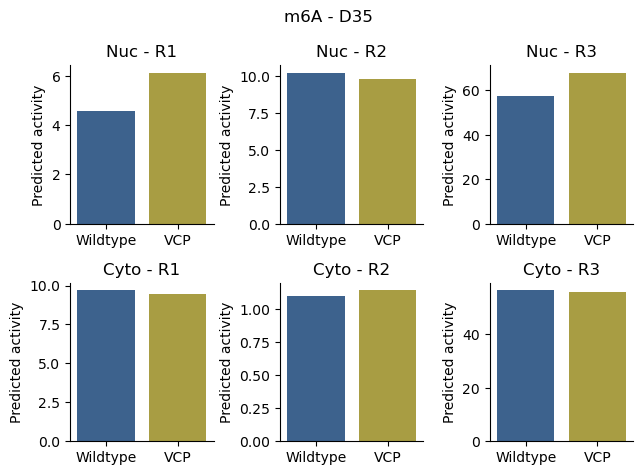

In [30]:
# m6A regulation
barplot_CTRL_VCP_activity(df_max, "m6A", day="D35")
save_figure(f"{figures_subfolder}/regulators_CTRL_vs_VCP_activity_D35/barplot_welch_R1_R2_R3_CTRL_vs_VCP_D35_m6A.pdf",
            legend="Predicted activity of m6A sites at the 3'UTR, D35, CTRL ('Wildtype', blue) vs VCP (yellow; VCP-R155C and "
                   "VCP-R191Q pooled): region scores in the nuclear (top row) and cytoplasmic (bottom row) fractions. "
                   "R1: max Welch score (-log10(p) x dPUD) in [-350, -50] nt upstream of the pPAS; R2: max of the "
                   "sign-flipped Welch score in [0, +150] nt downstream of the pPAS (positive = depletion); R3: max of "
                   "the sign-flipped Welch score in [-350, -50] nt upstream of the dPAS. One value per bar (no "
                   "replicates, no error bars); each panel has its own y axis.")
plt.show()

In [31]:
all_lengthening_regs = list(class_df_R1['regulator'].values) + list(class_df_R2['regulator'].values) + list(class_df_R3['regulator'].values) 

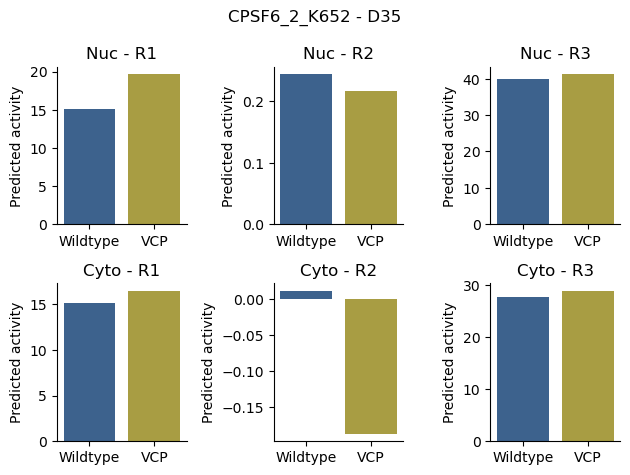

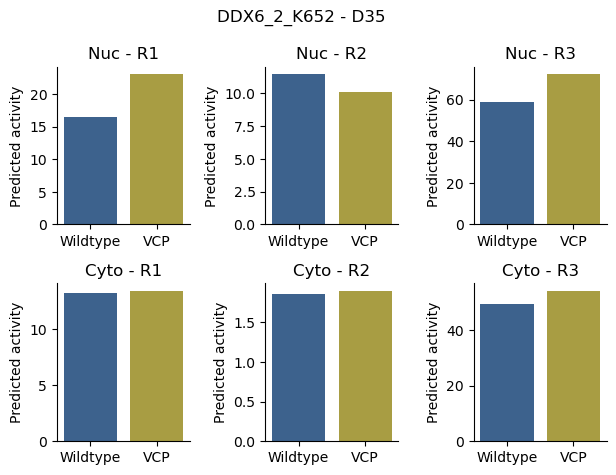

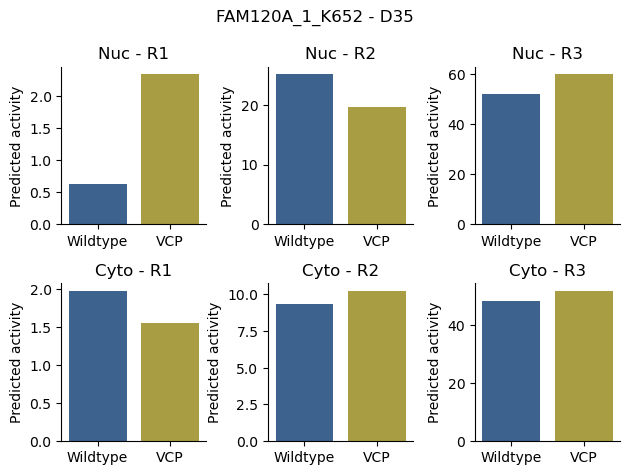

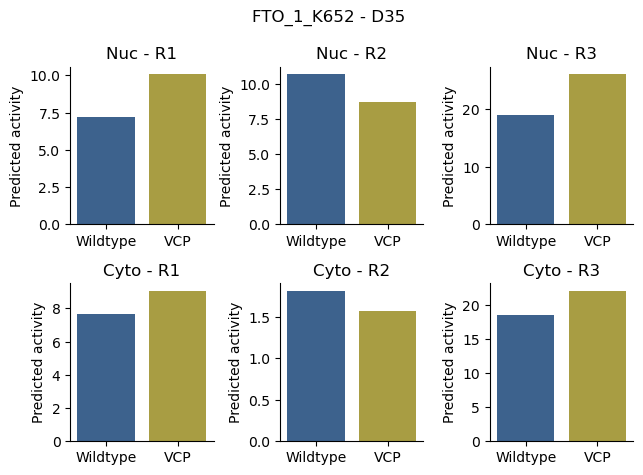

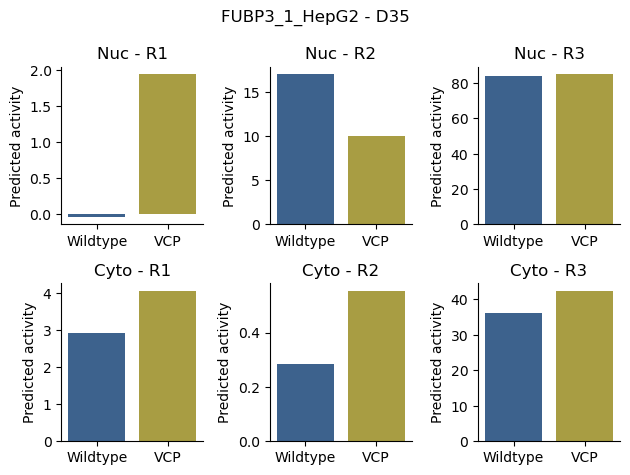

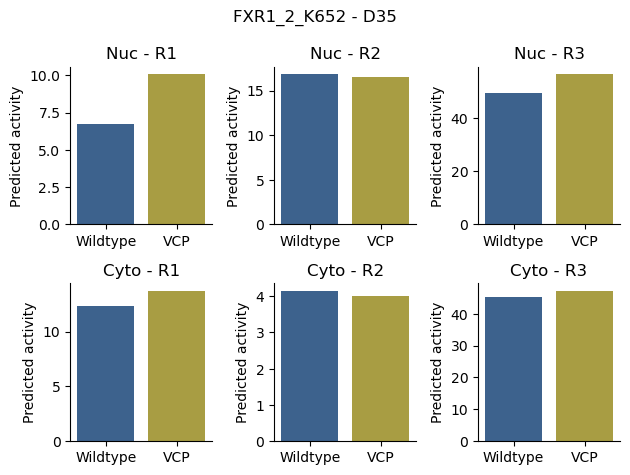

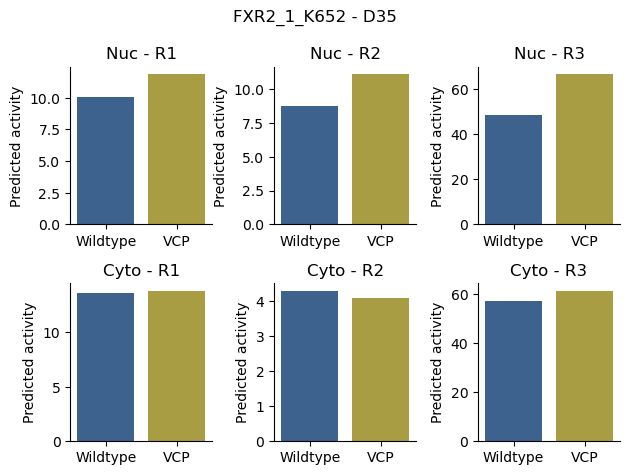

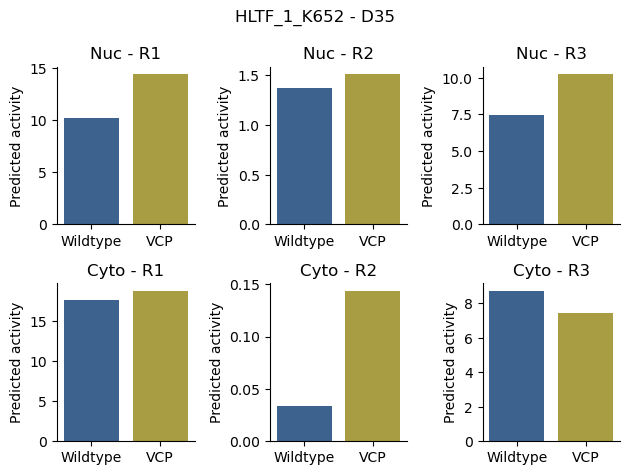

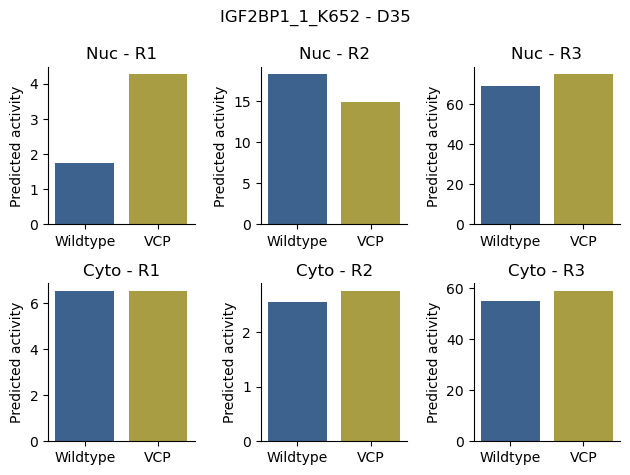

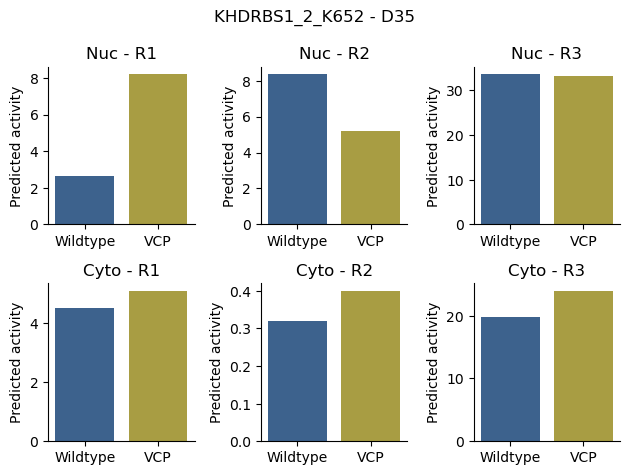

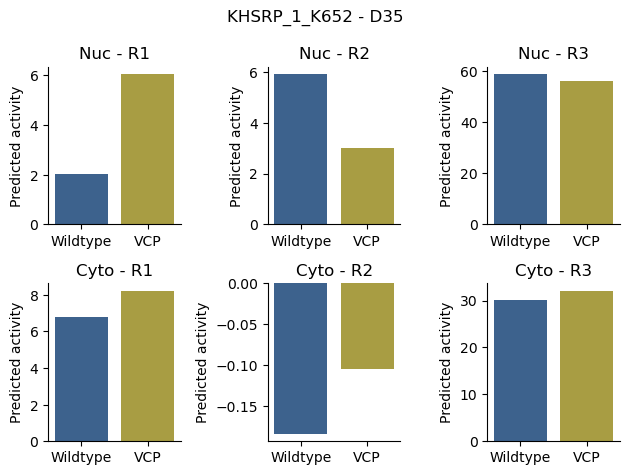

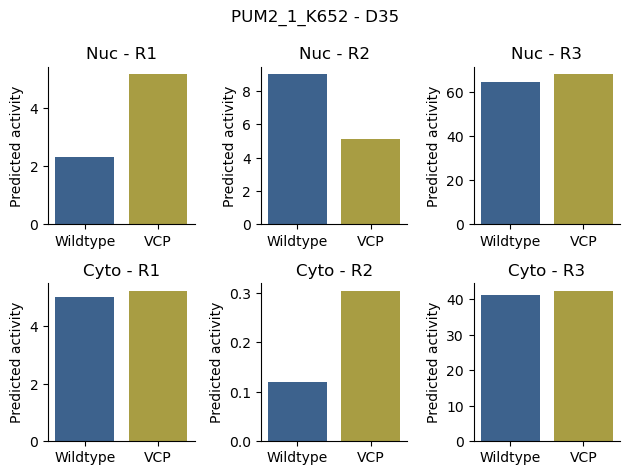

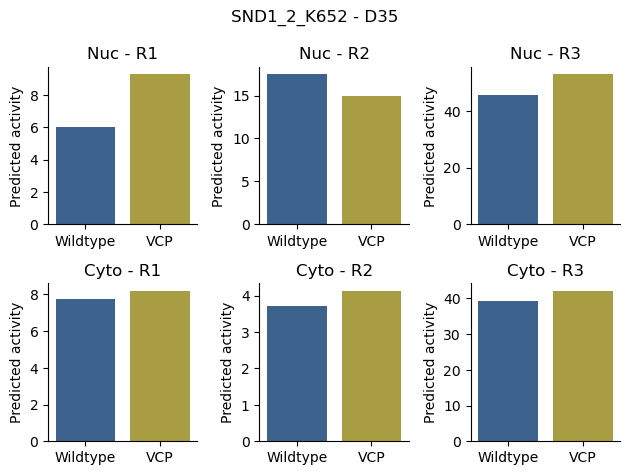

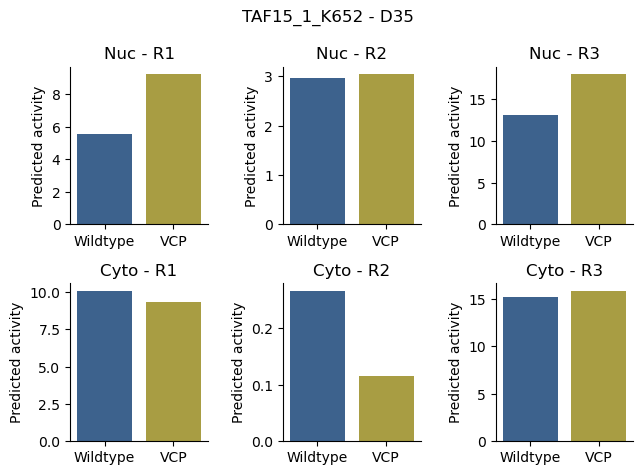

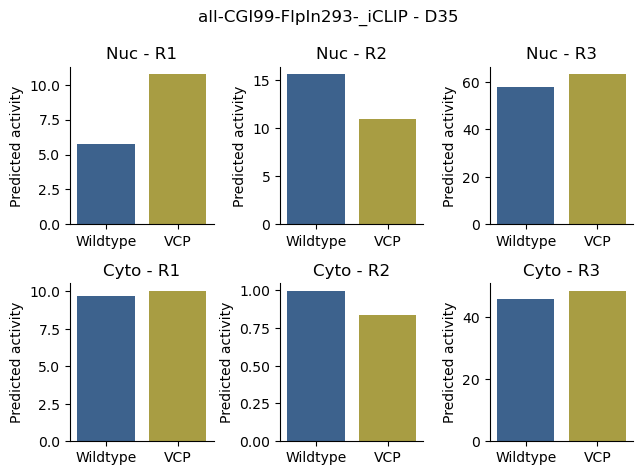

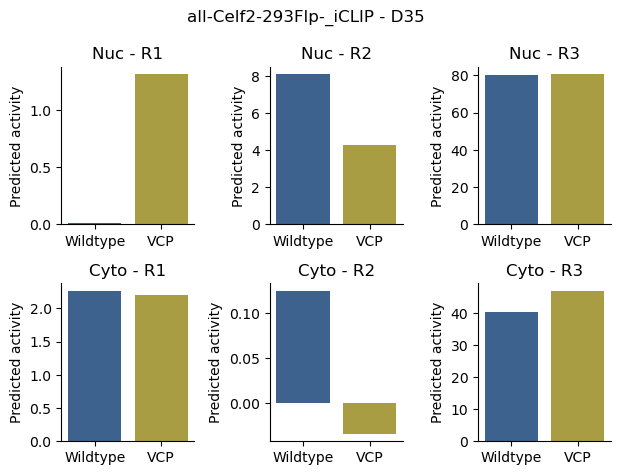

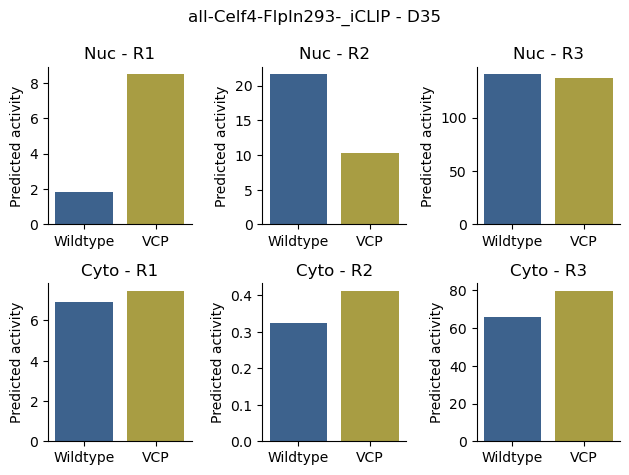

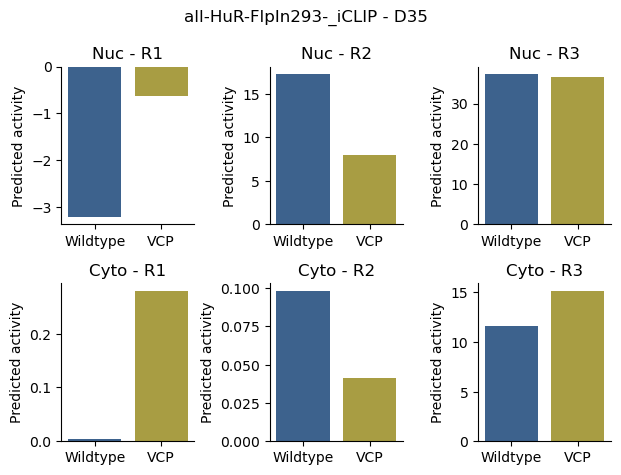

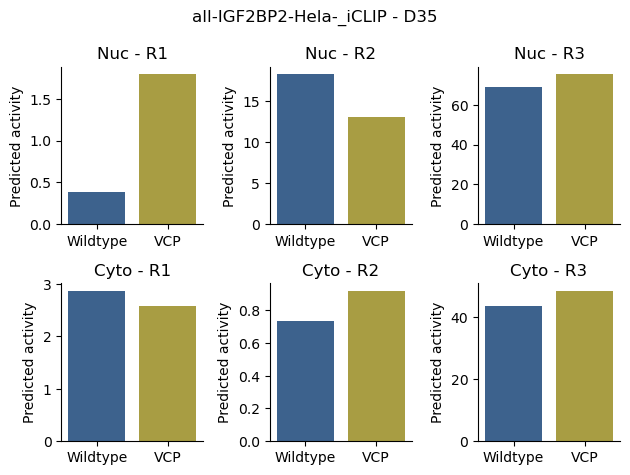

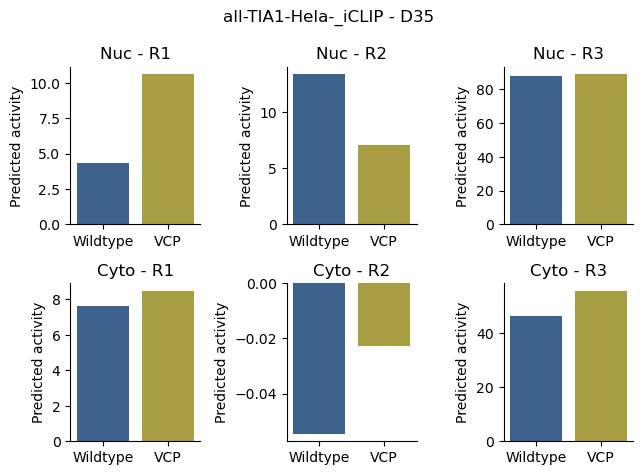

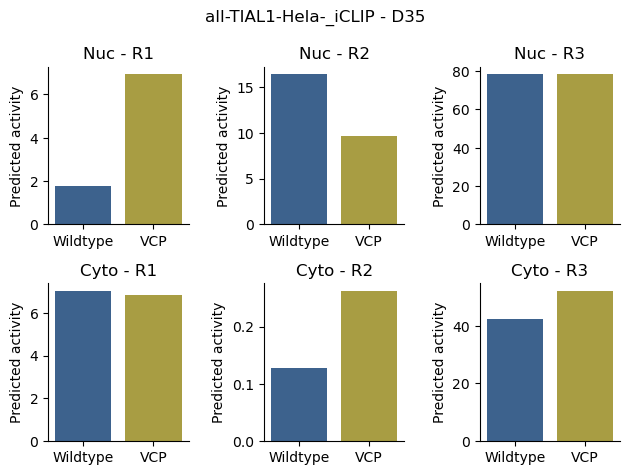

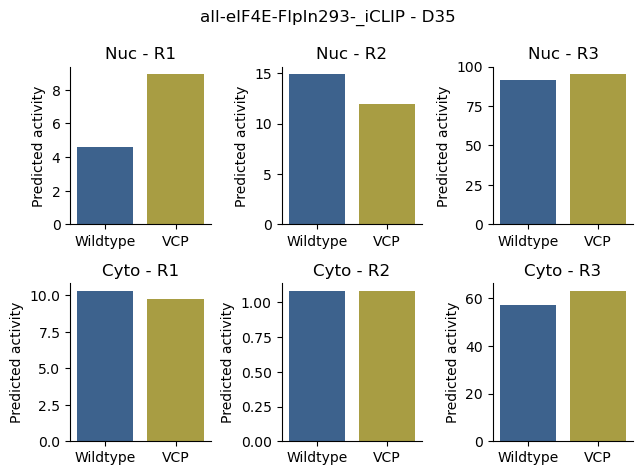

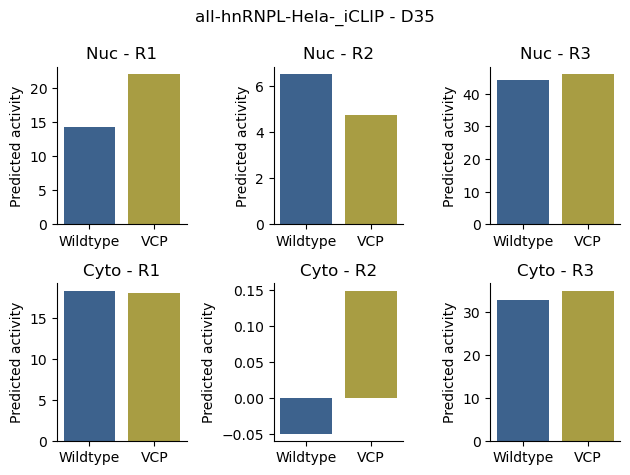

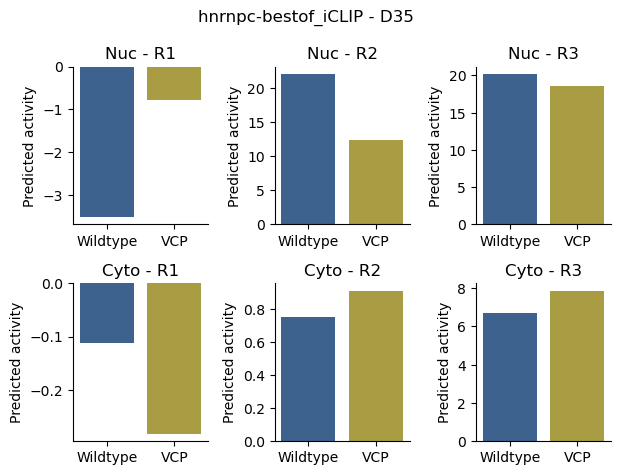

In [32]:
for reg in sorted(set(all_lengthening_regs)):
    barplot_CTRL_VCP_activity(df_max, reg, day="D35")
    save_figure(f"{figures_subfolder}/regulators_CTRL_vs_VCP_activity_D35/lengthening_regulators/barplot_welch_R1_R2_R3_CTRL_vs_VCP_D35_{reg}.pdf",
                legend="Predicted activity of one regulator of lengthening per file (CLIP dataset with a significant "
                       "D22 -> D35 change in nuclear CTRL in R1, R2 or R3; name in the title and file name). "
                       "D35, CTRL ('Wildtype', blue) vs VCP (yellow; VCP-R155C and VCP-R191Q pooled): region scores in the nuclear (top row) and cytoplasmic (bottom row) fractions. R1: max Welch score (-log10(p) x dPUD) in [-350, -50] nt upstream of the pPAS; R2: max of the sign-flipped Welch score in [0, +150] nt downstream of the pPAS (positive = depletion); R3: max of the sign-flipped Welch score in [-350, -50] nt upstream of the dPAS. One value per bar (no replicates, no error bars); each panel has its own y axis.",
                pattern="barplot_welch_R1_R2_R3_CTRL_vs_VCP_D35_<regulator>.pdf")
    plt.show()

R1: n = 11, median CTRL = 5.59, median VCP = 10.08, Wilcoxon p = 0.000977
R2: n = 17, median CTRL = 16.85, median VCP = 10.30, Wilcoxon p = 1.53e-05
R3: n = 15, median CTRL = 68.82, median VCP = 74.99, Wilcoxon p = 0.169


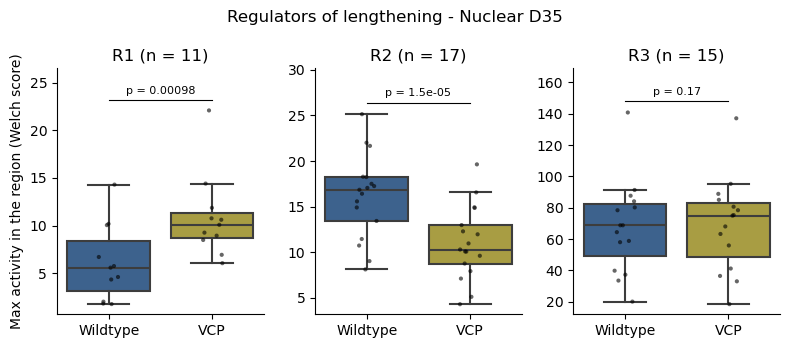

In [33]:
from scipy.stats import wilcoxon

# Max activity of each region's regulators (class_df_R{1,2,3}, RBPs) in its own region, nuclear D35, CTRL vs VCP
palette = {'Wildtype': '#2f619b', 'VCP': '#b9aa32'}
day, compartment = "D35", "Nuclear"

sub = df_max[(df_max['Day'] == day) & (df_max['Compartment'] == compartment)]
region_regs = []
for region, class_df in zip(["R1", "R2", "R3"], [class_df_R1, class_df_R2, class_df_R3]):
    reg_df = sub[sub['regulator'].isin(class_df['regulator'])][['regulator', 'VCP', f'mean_score_lg10_{region}']]
    region_regs.append(reg_df.rename(columns={f'mean_score_lg10_{region}': 'max_activity'}).assign(Region=region))
df_box = pd.concat(region_regs, ignore_index=True)

fig, axes = plt.subplots(1, 3, figsize=(8, 3.5))
for ax, region in zip(axes, ["R1", "R2", "R3"]):
    reg_box = df_box[df_box['Region'] == region]
    sns.boxplot(data=reg_box, x='VCP', y='max_activity', order=['Wildtype', 'VCP'],
                palette=palette, showfliers=False, ax=ax)
    sns.stripplot(data=reg_box, x='VCP', y='max_activity', order=['Wildtype', 'VCP'],
                  color='black', size=3, alpha=0.6, ax=ax)

    # Paired Wilcoxon signed-rank test (same regulators in both conditions)
    paired = reg_box.pivot(index='regulator', columns='VCP', values='max_activity').dropna()
    pval = wilcoxon(paired['Wildtype'], paired['VCP']).pvalue
    print(f"{region}: n = {len(paired)}, median CTRL = {paired['Wildtype'].median():.2f}, "
          f"median VCP = {paired['VCP'].median():.2f}, Wilcoxon p = {pval:.3g}")

    ymax = reg_box['max_activity'].max()
    ax.plot([0, 1], [ymax * 1.05] * 2, color='black', linewidth=0.8)
    ax.text(0.5, ymax * 1.07, f"p = {pval:.2g}", ha='center', va='bottom', fontsize=8)
    ax.set_ylim(top=ymax * 1.2)
    ax.set_xlabel('')
    ax.set_ylabel('Max activity in the region (Welch score)' if region == "R1" else '')
    ax.set_title(f"{region} (n = {len(paired)})")
    sns.despine(ax=ax)

plt.suptitle(f"Regulators of lengthening - {compartment} {day}")
plt.tight_layout()

save_figure(f"{figures_subfolder}/regulators_CTRL_vs_VCP_activity_D35/boxplot_max_welch_R1_R2_R3_regulators_CTRL_vs_VCP_D35_nuclear.pdf",
            legend="Activity of the regulators of lengthening of each region (CLIP datasets with a significant D22 -> D35 "
                   "change in nuclear CTRL in that region; RNA modifications excluded) in their own region, nuclear "
                   "fraction, D35, in CTRL ('Wildtype', blue) vs VCP (yellow; VCP-R155C and VCP-R191Q pooled). One point "
                   "per CLIP dataset. R1: max Welch score (-log10(p) x dPUD) in [-350, -50] nt upstream of the pPAS; R2: "
                   "max of the sign-flipped Welch score in [0, +150] nt downstream of the pPAS (positive = depletion); R3: "
                   "max of the sign-flipped Welch score in [-350, -50] nt upstream of the dPAS. Boxes: median and "
                   "interquartile range, whiskers 1.5 x IQR. p: two-sided paired Wilcoxon signed-rank test, CTRL vs VCP; "
                   "n = number of regulators. One panel per region, each with its own y axis.")
plt.show()

R2 APA: n = 6, median CTRL = 17.17, median VCP = 14.89, Wilcoxon p = 0.0312
R2 Nuclear retention: n = 11, median CTRL = 16.42, median VCP = 10.07, Wilcoxon p = 0.000977


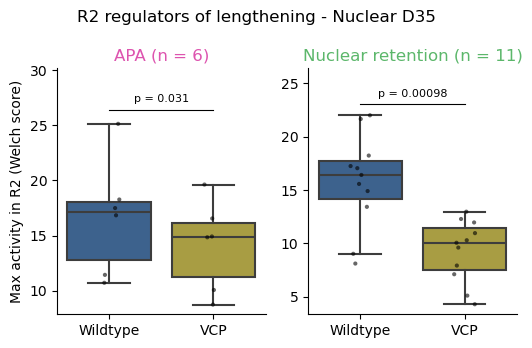

In [34]:
# Same as above for R2, split by class (APA vs nuclear retention, class_df_R2; ambiguous ones left out)
category_palette = {'APA': '#dd54af', 'Nuclear retention': '#5cb76b'}

df_box_R2 = df_box[df_box['Region'] == "R2"].merge(class_df_R2[['regulator', 'category']], on='regulator')

fig, axes = plt.subplots(1, 2, figsize=(5.5, 3.5))
for ax, category in zip(axes, ['APA', 'Nuclear retention']):
    cat_box = df_box_R2[df_box_R2['category'] == category]
    sns.boxplot(data=cat_box, x='VCP', y='max_activity', order=['Wildtype', 'VCP'],
                palette=palette, showfliers=False, ax=ax)
    sns.stripplot(data=cat_box, x='VCP', y='max_activity', order=['Wildtype', 'VCP'],
                  color='black', size=3, alpha=0.6, ax=ax)

    # Paired Wilcoxon signed-rank test (same regulators in both conditions)
    paired = cat_box.pivot(index='regulator', columns='VCP', values='max_activity').dropna()
    pval = wilcoxon(paired['Wildtype'], paired['VCP']).pvalue
    print(f"R2 {category}: n = {len(paired)}, median CTRL = {paired['Wildtype'].median():.2f}, "
          f"median VCP = {paired['VCP'].median():.2f}, Wilcoxon p = {pval:.3g}")

    ymax = cat_box['max_activity'].max()
    ax.plot([0, 1], [ymax * 1.05] * 2, color='black', linewidth=0.8)
    ax.text(0.5, ymax * 1.07, f"p = {pval:.2g}", ha='center', va='bottom', fontsize=8)
    ax.set_ylim(top=ymax * 1.2)
    ax.set_xlabel('')
    ax.set_ylabel('Max activity in R2 (Welch score)' if category == 'APA' else '')
    ax.set_title(f"{category} (n = {len(paired)})", color=category_palette[category])
    sns.despine(ax=ax)

plt.suptitle(f"R2 regulators of lengthening - {compartment} {day}")
plt.tight_layout()

save_figure(f"{figures_subfolder}/regulators_CTRL_vs_VCP_activity_D35/boxplot_max_welch_R2_regulators_APA_vs_NR_CTRL_vs_VCP_D35_nuclear.pdf",
            legend="Activity in R2 of the R2 regulators of lengthening (CLIP datasets with a significant D22 -> D35 "
                   "change in nuclear CTRL in R2; RNA modifications excluded), nuclear fraction, D35, in CTRL "
                   "('Wildtype', blue) vs VCP (yellow; VCP-R155C and VCP-R191Q pooled), split by class: APA (left, "
                   "significant R2 score in both the nuclear and cytoplasmic fractions of CTRL at D35) and nuclear "
                   "retention (right, significant in the nucleus only); ambiguous regulators are left out. One point per "
                   "CLIP dataset. Activity: max of the sign-flipped Welch score (-log10(p) x dPUD) in [0, +150] nt "
                   "downstream of the pPAS (positive = depletion). Boxes: median and interquartile range, whiskers "
                   "1.5 x IQR. p: two-sided paired Wilcoxon signed-rank test, CTRL vs VCP; n = number of regulators. "
                   "Each panel has its own y axis.")
plt.show()

<a id="vcp-effect"></a>
## Regulators of the VCP effect at D35 (VCP vs CTRL, nuclear)

Same z-score approach on the difference VCP − CTRL at D35 in the nuclear fraction (in `region_configs`, the `col_d22` / `col_d35` names hold the CTRL and VCP columns). The one-sided test looks for a score that is higher in VCP for R1 and lower in VCP for R2 and R3, i.e. less lengthening activity. Bubble plot as above.

The next cells keep the R2-significant CLIPs (`candidates_vcp`, one per RBP) and classify them as APA / nuclear retention from their nuclear vs cytoplasmic Welch scores in CTRL at D35 (as above, R2 window). They keep one CLIP per RBP (`pick_best`: APA first, then the largest nuclear − cytoplasmic gap), which gives `class_df_vcp`.

Saved: `regulators_VCP_vs_CTRL_D35/bubble_zscore_VCP_minus_CTRL_D35_nuclear.pdf`.

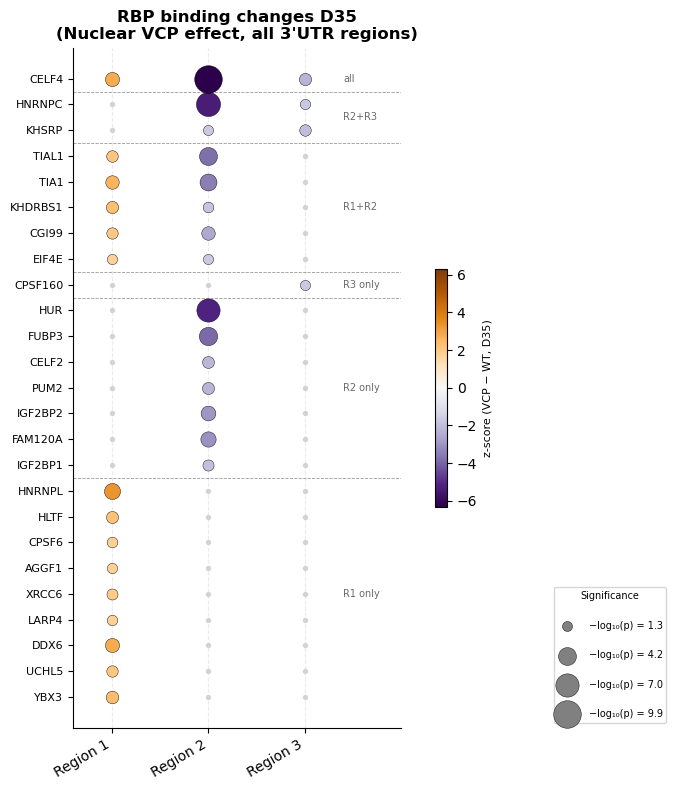

In [35]:
region_configs = {
    'Region 1': ('Nuclear_WT_D35_region1', 'Nuclear_VCP_D35_region1', +1),
    'Region 2': ('Nuclear_WT_D35_region2', 'Nuclear_VCP_D35_region2', -1),
    'Region 3': ('Nuclear_WT_D35_region3', 'Nuclear_VCP_D35_region3', -1),
}

summaries = {}
for label, (col_d22, col_d35, sign) in region_configs.items():
    diff = matrix_merged_unscaled[col_d35] - matrix_merged_unscaled[col_d22]
    z = (diff - diff.mean()) / diff.std(ddof=0)
    signal_z = sign * z
    raw_z    = z
    p = stats.norm.sf(signal_z)
    summaries[label] = pd.DataFrame({'signal_z': signal_z, 'raw_z': raw_z, 'pvalue': p})

sig_rbps = set()
for df in summaries.values():
    sig_rbps.update(df[df['pvalue'] < 0.05].index)
sig_rbps = sorted(sig_rbps)

z_mat    = pd.DataFrame({r: summaries[r]['raw_z']    for r in summaries}).loc[sig_rbps]
sig_z_mat= pd.DataFrame({r: summaries[r]['signal_z'] for r in summaries}).loc[sig_rbps]
p_mat    = pd.DataFrame({r: summaries[r]['pvalue']   for r in summaries}).loc[sig_rbps]
nlp_mat  = -np.log10(p_mat)

# ── Sort by significance pattern ─────────────────────────────────────────────
sig_flag = (p_mat < 0.05)
regions  = list(sig_flag.columns)   # ['Region 1', 'Region 2', 'Region 3']

_pattern_order = [
    ((True,  False, False), 'R1 only'),
    ((False, True,  False), 'R2 only'),
    ((False, False, True),  'R3 only'),
    ((True,  True,  False), 'R1+R2'),
    ((True,  False, True),  'R1+R3'),
    ((False, True,  True),  'R2+R3'),
    ((True,  True,  True),  'all'),
]

ordered_rbps = []
group_info   = []   # (start_i, end_i, label)

for pattern, glabel in _pattern_order:
    group = [
        rbp for rbp in sig_flag.index
        if tuple(sig_flag.loc[rbp, r] for r in regions) == pattern
    ]
    if not group:
        continue
    # within-group sort by mean signal_z ascending
    group.sort(key=lambda rbp: sig_z_mat.loc[rbp].mean())
    start = len(ordered_rbps)
    ordered_rbps.extend(group)
    group_info.append((start, len(ordered_rbps) - 1, glabel))

# One row per RBP (get_RBP_name): several CLIPs of the same RBP collapse to the first
# one met reading the plot from TOP to bottom. Row 0 is drawn at the bottom, so walk
# ordered_rbps from the end.
keep, seen = set(), set()
for entity in reversed(ordered_rbps):
    rbp_name = get_RBP_name(entity)
    if rbp_name not in seen:
        seen.add(rbp_name)
        keep.add(entity)

ordered_dedup, group_info_dedup = [], []
for start, end, glabel in group_info:
    members = [e for e in ordered_rbps[start:end + 1] if e in keep]
    if not members:
        continue
    s0 = len(ordered_dedup)
    ordered_dedup.extend(members)
    group_info_dedup.append((s0, len(ordered_dedup) - 1, glabel))
ordered_rbps, group_info = ordered_dedup, group_info_dedup
rbp_labels = [get_RBP_name(e) for e in ordered_rbps]

sort_order = pd.Index(ordered_rbps)
z_mat   = z_mat.loc[sort_order]
p_mat   = p_mat.loc[sort_order]
nlp_mat = nlp_mat.loc[sort_order]

n_rbps        = len(ordered_rbps)
col_positions = [i * 2 for i in range(len(regions))]

# ── Bubble plot ───────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, max(4, n_rbps * 0.32)))

cmap   = cm.RdBu_r
cmap = sns.diverging_palette(250, 30, s=80, l=55, as_cmap=True)
cmap = cm.PuOr_r


absmax = max(abs(z_mat.values.max()), abs(z_mat.values.min()), 2)
norm_c = mcolors.TwoSlopeNorm(vmin=-absmax, vcenter=0, vmax=absmax)

for j, region in enumerate(regions):
    xpos = col_positions[j]
    for i, rbp in enumerate(z_mat.index):
        z_val   = z_mat.loc[rbp, region]
        p_val   = p_mat.loc[rbp, region]
        nlp_val = nlp_mat.loc[rbp, region]
        if p_val < 0.05:
            ax.scatter(xpos, i, s=nlp_val * 40, c=[cmap(norm_c(z_val))],
                       zorder=3, edgecolors='black', linewidths=0.3)
        else:
            ax.scatter(xpos, i, s=8, c='lightgrey', zorder=2)

# Group separators and labels
for idx, (start, end, glabel) in enumerate(group_info):
    if idx > 0:
        ax.axhline(start - 0.5, color='black', linewidth=0.6, linestyle='--', alpha=0.4)
    ymid = (start + end) / 2
    ax.text(col_positions[-1] + 0.8, ymid, glabel, fontsize=7, va='center', color='dimgrey')

ax.set_xticks(col_positions)
ax.set_xticklabels(regions, fontsize=10, rotation=30, ha='right')
ax.set_yticks(range(n_rbps))
ax.set_yticklabels(rbp_labels, fontsize=8)
ax.set_xlim(-0.8, col_positions[-1] + 2.0)
ax.grid(axis='x', alpha=0.25, linestyle='--')
ax.set_title("RBP binding changes D35\n(Nuclear VCP effect, all 3'UTR regions)", weight='bold')

sm = cm.ScalarMappable(cmap=cmap, norm=norm_c)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, shrink=0.35, pad=0.08)
cbar.set_label('z-score (VCP − WT, D35)', fontsize=8)

nlp_max = nlp_mat[p_mat < 0.05].max().max()
legend_values = np.linspace(-np.log10(0.05), nlp_max, 4)
legend_handles = [
    plt.scatter([], [], s=nlp_ex * 40, c='grey', edgecolors='black', linewidths=0.3,
                label=f'−log₁₀(p) = {nlp_ex:.1f}')
    for nlp_ex in legend_values
]
ax.legend(handles=legend_handles, title='Significance', fontsize=7, title_fontsize=7,
          loc='lower left', bbox_to_anchor=(1.45, 0),
          labelspacing=2, handletextpad=1.2)

sns.despine(ax=ax)
plt.tight_layout()
save_figure(f"{figures_subfolder}/regulators_VCP_vs_CTRL_D35/bubble_zscore_VCP_minus_CTRL_D35_nuclear.pdf",
            legend="Regulators (CLIP datasets and RNA modifications) whose Welch score differs significantly between VCP "
                   "and CTRL in the nuclear fraction at D35 in at least one region. For each region (columns; R2 score = "
                   "depletion strength, positive), the difference VCP - CTRL is z-scored against the differences of all "
                   "regulators. Colour = z-score; bubble size = -log10(p), one-sided normal p in the direction tested "
                   "(higher in VCP for R1, lower in VCP for R2 and R3); grey dot = p >= 0.05. Rows grouped by "
                   "significance pattern; one row per RBP (the first CLIP from the top is kept).")
plt.show()

In [36]:
rbp_labels = [get_RBP_name(r) for r in ordered_rbps]

kept = pd.DataFrame({
    "regulator": ordered_rbps,
    "RBP": rbp_labels,
    "group": [g for s, e, g in group_info for _ in range(s, e + 1)],
}).iloc[::-1].reset_index(drop=True)
kept.drop_duplicates(['RBP'], keep='first', inplace=True)

In [37]:
candidates_vcp = p_mat[p_mat['Region 2'] < 0.05].index.tolist()

candidates_vcp = [c for c in candidates_vcp if c in kept["regulator"].values]

candidates_vcp_R1 = p_mat[p_mat['Region 1'] < 0.05].index.tolist()
candidates_vcp_R2 = p_mat[p_mat['Region 2'] < 0.05].index.tolist()
candidates_vcp_R3 = p_mat[p_mat['Region 3'] < 0.05].index.tolist()


In [38]:
records = []
for CLIP in candidates_vcp:
    clip = proximal_filtered[proximal_filtered['regulator'] == CLIP]
    nuc  = clip[(clip['Compartment'] == 'Nuclear')     & (clip['dist'] >= 0)]
    cyto = clip[(clip['Compartment'] == 'Cytoplasmic') & (clip['dist'] >= 0)]

    if nuc.empty or cyto.empty:
        continue
    
    nuc['mean_score_lg10'] = -nuc['mean_score_lg10']
    cyto['mean_score_lg10'] = -cyto['mean_score_lg10']
    
    
    nuclear_max = nuc['mean_score_lg10'].max()
    cyto_max    = cyto['mean_score_lg10'].max()

    if nuclear_max > -np.log10(0.05) and cyto_max > -np.log10(0.05):
        category = 'APA'
    elif nuclear_max > -np.log10(0.05) and cyto_max < -np.log10(0.05):
        category = 'Nuclear retention'
    else:
        category = 'Ambiguous'

    records.append({
        'regulator': CLIP,
        'RBP': get_RBP_name(CLIP),
        'nuclear_max': nuclear_max,
        'cyto_max': cyto_max,
        'category': category,
        'nuc_cyto_diff': nuclear_max - cyto_max,  # more negative = larger nuc-specific effect
    })

class_df = pd.DataFrame(records)

# Deduplicate: per RBP, prefer APA over others; break ties by largest |nuc - cyto| difference
def pick_best(group):
    apa = group[group['category'] == 'APA']
    pool = apa if not apa.empty else group
    return pool.loc[pool['nuc_cyto_diff'].idxmin()]  # most negative diff = biggest nuc vs cyto gap

class_df = (class_df
            .groupby('RBP', group_keys=False)
            .apply(pick_best)
            .reset_index(drop=True)
            .sort_values('category'))

print(class_df[['RBP', 'nuclear_max', 'cyto_max', 'category']].to_string(index=False))

class_df_vcp = class_df.copy()

    RBP  nuclear_max  cyto_max          category
FAM120A    25.132218  9.318817               APA
IGF2BP1    18.276666  2.551236               APA
  CELF2     8.116626  0.125182 Nuclear retention
  CELF4    21.659038  0.324368 Nuclear retention
  CGI99    15.575261  0.993665 Nuclear retention
  EIF4E    14.906863  1.077266 Nuclear retention
  FUBP3    17.051022  0.284214 Nuclear retention
 HNRNPC    22.003866  0.748370 Nuclear retention
    HUR    17.249051  0.098118 Nuclear retention
IGF2BP2    18.232445  0.732661 Nuclear retention
KHDRBS1     8.366242  0.320527 Nuclear retention
  KHSRP     5.917903 -0.183449 Nuclear retention
   PUM2     9.029683  0.119680 Nuclear retention
   TIA1    13.429141 -0.054604 Nuclear retention
  TIAL1    16.416359  0.127657 Nuclear retention


<a id="lengthening-vs-vcp"></a>
## Overlap between the regulators of lengthening and of the VCP effect (Region 2)

Venn diagrams, per RBP, of the R2 regulators of lengthening (`class_df_R2`) vs the R2 regulators of the VCP effect (`class_df_vcp`), separately for the APA and nuclear-retention classes, with RBP names in each area. The first (commented) cell is an older version that works on CLIP names. The cells after the Venn diagram collect every CLIP dataset of the RBPs in the common areas (`common_apa_clip_list`, `common_nr_clip_list`, `common_clip_list`), used in the VCP knock-in section.

Saved: `regulators_lengthening_vs_VCP_overlap/venn_R2_regulators_lengthening_vs_VCP_effect_APA_and_NR.pdf`.

In [39]:
# from matplotlib_venn import venn2

# palette = {'APA': '#dd54af', 'Nuclear retention': '#5cb76b'}

# fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# df_summary_venn_clip = {}
# for ax, category, color in zip(
#     axes,
#     ['APA', 'Nuclear retention'],
#     ['#e07b54', '#5b8db8'],
# ):
#     set_len = set(class_df_R2.loc[class_df_R2['category'] == category, 'regulator'])
#     set_vcp = set(class_df_vcp.loc[class_df_vcp['category'] == category, 'regulator'])

#     v = venn2(
#         [set_len, set_vcp],
#         set_labels=('Lengthening', 'VCP effect'),
#         set_colors=(color, color),
#         alpha=0.5,
#         ax=ax,
#     )

#     # Annotate each region with gene names
#     common   = set_len & set_vcp
#     only_len = set_len - set_vcp
#     only_vcp = set_vcp - set_len
    
#     df_summary_venn_clip[category] = {'common': common, 
#                                  'only_len': only_len, 
#                                  'only_vcp': only_vcp}


#     for subset_id, genes in [('10', only_len), ('01', only_vcp), ('11', common)]:
#         lbl = v.get_label_by_id(subset_id)
#         if lbl and genes:
#             lbl.set_text(f"{len(genes)}\n" + "\n".join(sorted(genes)))
#             lbl.set_fontsize(7)

#     ax.set_title(category, fontsize=12, weight='bold', color=color)

# plt.suptitle('RBP overlap: Lengthening vs VCP effect', fontsize=13, weight='bold')
# plt.tight_layout()

# venn_dir = f"{figures_subfolder}/regulators_lengthening_vs_VCP_overlap"
# os.makedirs(venn_dir, exist_ok=True)
# plt.savefig(f"{venn_dir}/venn_lengthening_vs_vcp.pdf", bbox_inches='tight')
# plt.show()

# # Summary
# for category in ['APA', 'Nuclear retention']:
#     s_l = set(class_df_R2.loc[class_df_R2['category'] == category, 'regulator'])
#     s_v = set(class_df_vcp.loc[class_df_vcp['category'] == category, 'regulator'])
#     print(f"\n{category}")
#     print(f"  Lengthening only : {sorted(s_l - s_v)}")
#     print(f"  VCP only         : {sorted(s_v - s_l)}")
#     print(f"  Common           : {sorted(s_l & s_v)}")

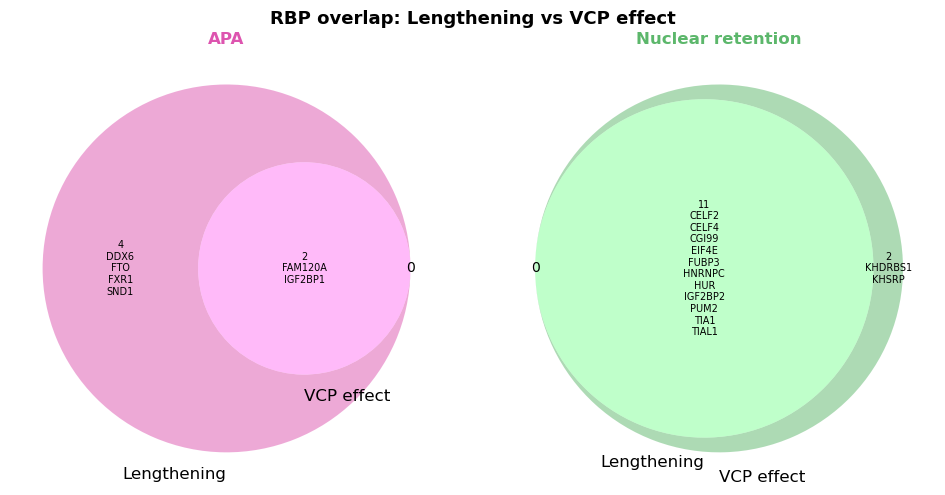


APA
  Lengthening only : ['DDX6', 'FTO', 'FXR1', 'SND1']
  VCP only         : []
  Common           : ['FAM120A', 'IGF2BP1']

Nuclear retention
  Lengthening only : []
  VCP only         : ['KHDRBS1', 'KHSRP']
  Common           : ['CELF2', 'CELF4', 'CGI99', 'EIF4E', 'FUBP3', 'HNRNPC', 'HUR', 'IGF2BP2', 'PUM2', 'TIA1', 'TIAL1']


In [40]:
from matplotlib_venn import venn2

palette = {'APA': '#dd54af', 'Nuclear retention': '#5cb76b'}

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

df_summary_venn = {}
for ax, category, color in zip(
    axes,
    ['APA', 'Nuclear retention'],
    [palette['APA'], palette['Nuclear retention']],
):
    set_len = set(class_df_R2.loc[class_df_R2['category'] == category, 'RBP'])
    set_vcp = set(class_df_vcp.loc[class_df_vcp['category'] == category, 'RBP'])

    v = venn2(
        [set_len, set_vcp],
        set_labels=('Lengthening', 'VCP effect'),
        set_colors=(color, color),
        alpha=0.5,
        ax=ax,
    )

    # Annotate each region with gene names
    common   = set_len & set_vcp
    only_len = set_len - set_vcp
    only_vcp = set_vcp - set_len
    
    df_summary_venn[category] = {'common': common, 
                                 'only_len': only_len, 
                                 'only_vcp': only_vcp}


    for subset_id, genes in [('10', only_len), ('01', only_vcp), ('11', common)]:
        lbl = v.get_label_by_id(subset_id)
        if lbl and genes:
            lbl.set_text(f"{len(genes)}\n" + "\n".join(sorted(genes)))
            lbl.set_fontsize(7)

    ax.set_title(category, fontsize=12, weight='bold', color=color)

plt.suptitle('RBP overlap: Lengthening vs VCP effect', fontsize=13, weight='bold')
plt.tight_layout()

save_figure(f"{figures_subfolder}/regulators_lengthening_vs_VCP_overlap/venn_R2_regulators_lengthening_vs_VCP_effect_APA_and_NR.pdf",
            legend="Overlap, per RBP, between the R2 regulators of lengthening (significant D22 -> D35 change in nuclear "
                   "CTRL) and the R2 regulators of the VCP effect (significant VCP vs CTRL difference at D35, nuclear), "
                   "for the RBPs classified APA (left, pink) and nuclear retention (right, green) from their nuclear vs "
                   "cytoplasmic Welch scores in CTRL at D35. RBP names are written in each area.")
plt.show()

# Summary
for category in ['APA', 'Nuclear retention']:
    s_l = set(class_df_R2.loc[class_df_R2['category'] == category, 'RBP'])
    s_v = set(class_df_vcp.loc[class_df_vcp['category'] == category, 'RBP'])
    print(f"\n{category}")
    print(f"  Lengthening only : {sorted(s_l - s_v)}")
    print(f"  VCP only         : {sorted(s_v - s_l)}")
    print(f"  Common           : {sorted(s_l & s_v)}")

In [41]:
common_nr_clip_list = list(set(class_df_R2[class_df_R2['RBP'].isin(df_summary_venn['Nuclear retention']['common'])].regulator.values) | set(class_df_vcp[class_df_vcp['RBP'].isin(df_summary_venn['Nuclear retention']['common'])].regulator.values))

In [42]:
common_apa_clip_list = list(set(class_df_R2[class_df_R2['RBP'].isin(df_summary_venn['APA']['common'])].regulator.values) | set(class_df_vcp[class_df_vcp['RBP'].isin(df_summary_venn['APA']['common'])].regulator.values))

In [43]:
common_clip_list = common_apa_clip_list + common_nr_clip_list

<a id="condensates"></a>
## Condensate propensity of APA vs nuclear-retention regulators (Region 2)

Loads the condensate propensity z-score (`Condensate_Zscore`) of each CLIP from the 6th sheet of the AxonLoc supplementary tables. Excel turned some values into dates: `normalize_condensate_zscore` converts them back, and a few remaining entries are set by hand. The table is then reduced to one row per RBP (this overwrites `df`). The R2 regulators of lengthening are split into **APA** and **Nuclear retention**, and **All** holds every other RBP of the table. Pairwise tests: Welch's t-test if every group passes a Shapiro test, Mann–Whitney U otherwise (p uncorrected).

Saved: `regulators_condensate_propensity/boxplot_condensate_zscore_R2_lengthening_regulators_APA_vs_NR.pdf`.

In [44]:
from pathlib import Path


workbook_path = Path(f'{AXONLOC_CSV}')
xl = pd.ExcelFile(workbook_path)

from datetime import date, datetime
import numpy as np


def normalize_condensate_zscore(value):
    if pd.isna(value):
        return value

    if isinstance(value, (pd.Timestamp, datetime, date, np.datetime64)):
        timestamp = pd.Timestamp(value)
        return float(f'{timestamp.day}.{timestamp.month}')

    if isinstance(value, str):
        stripped = value.strip()
        parsed = pd.to_datetime(stripped, errors='coerce')
        if pd.notna(parsed):
            return float(f'{parsed.day}.{parsed.month}')

    return pd.to_numeric(value, errors='coerce')


# Load the first sheet as a starting point for exploration.
first_sheet = xl.sheet_names[5]
df = xl.parse(first_sheet)

if 'Condensate_Zscore' in df.columns:
    df['Condensate_Zscore'] = df['Condensate_Zscore'].map(normalize_condensate_zscore)
    df = df.dropna(subset=['Condensate_Zscore']).copy()
    
    
df.set_index('Clips', inplace=True)

df.loc['AARS1_1_K652', 'Condensate_Zscore'] = 2.08
df.loc['AARS1_2_K652', 'Condensate_Zscore'] = 2.08
df.loc['DGCR8_1_K652', 'Condensate_Zscore'] = 2.05
df.loc['DGCR8_2_K652', 'Condensate_Zscore'] = 2.05
df.loc['EFTUD2_1_HepG2', 'Condensate_Zscore'] = 2.09
df.loc['EFTUD2_2_HepG2', 'Condensate_Zscore'] = 2.09
df.loc['EFTUD2_1_K652', 'Condensate_Zscore'] = 2.09
df.loc['EFTUD2_2_K652', 'Condensate_Zscore'] = 2.09
df.loc['GEMIN5_1_K652', 'Condensate_Zscore'] = 2.02
df.loc['GEMIN5_2_K652', 'Condensate_Zscore'] = 2.02
df.loc['LARP7_1_HepG2', 'Condensate_Zscore'] = 2.09
df.loc['LARP7_2_HepG2', 'Condensate_Zscore'] = 2.09
df.loc['LARP7_1_K652', 'Condensate_Zscore'] = 2.09
df.loc['LARP7_2_K652', 'Condensate_Zscore'] = 2.09
df.loc['PPIL4_1_K652', 'Condensate_Zscore'] = 2.08
df.loc['PPIL4_2_K652', 'Condensate_Zscore'] = 2.08
df.loc['PPIL4_1_HepG2', 'Condensate_Zscore'] = 2.08
df.loc['PPIL4_2_HepG2', 'Condensate_Zscore'] = 2.08
df.loc['PUS1_1_K652', 'Condensate_Zscore'] = 2.01
df.loc['PUS1_2_K652', 'Condensate_Zscore'] = 2.01
df.loc['SERBP1_1_K652', 'Condensate_Zscore'] = 3.03
df.loc['SERBP1_2_K652', 'Condensate_Zscore'] = 3.03
df.loc['SFPQ_1_HepG2', 'Condensate_Zscore'] = 3.06
df.loc['SFPQ_2_HepG2', 'Condensate_Zscore'] = 3.06
df.loc['TRA2A_1_HepG2', 'Condensate_Zscore'] = 3.05
df.loc['TRA2A_2_HepG2', 'Condensate_Zscore'] = 3.05
df.loc['TRA2A_1_K652', 'Condensate_Zscore'] = 3.05
df.loc['TRA2A_2_K652', 'Condensate_Zscore'] = 3.05

# Keep only the first row for each RBP.
df['RBPs'] = df["RBPs"].str.upper()
df.set_index('RBPs', inplace=True)
df = df[~df.index.duplicated(keep='first')].copy()

In [45]:
candidates_nuc_ret = class_df_R2[class_df_R2['category'] == 'Nuclear retention']['RBP'].tolist()
candidates_apa = class_df_R2[class_df_R2['category'] == 'APA']['RBP'].tolist()

In [46]:
candidates_apa = [candidate for candidate in candidates_apa if candidate in df.index]
candidates_nuc_ret = [candidate for candidate in candidates_nuc_ret if candidate in df.index]


In [47]:
df["Category"] = "All"

df.loc[candidates_nuc_ret, "Category"] = "Nuclear retention"

df.loc[candidates_apa, "Category"] = "APA"

All is not normal (p=3.89e-06)


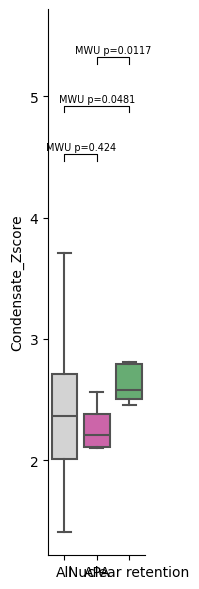

In [48]:

import matplotlib.pyplot as plt
from scipy import stats
from itertools import combinations

category_order = ['All', 'APA', 'Nuclear retention']

# Decide test once based on normality of all groups
all_normal = True
for group in category_order:
    g = df.loc[df['Category'] == group, 'Condensate_Zscore'].dropna()
    if len(g) >= 3:
        if stats.shapiro(g).pvalue <= 0.05:
            print(f"{group} is not normal (p={stats.shapiro(g).pvalue:.3g})")
            all_normal = False
            break
    else:
        all_normal = False
        break

test_name = 'Welch' if all_normal else 'MWU'

pairwise = {}
for g1, g2 in combinations(category_order, 2):
    a = df.loc[df['Category'] == g1, 'Condensate_Zscore'].dropna()
    b = df.loc[df['Category'] == g2, 'Condensate_Zscore'].dropna()
    if all_normal:
        _, p = stats.ttest_ind(a, b, equal_var=False, nan_policy='omit')
    else:
        _, p = stats.mannwhitneyu(a, b, alternative='two-sided')
        # _, p = stats.ttest_ind(a, b, equal_var=False, nan_policy='omit')
    pairwise[(g1, g2)] = p


fig, ax = plt.subplots(figsize=(2, 6))
sns.boxplot(data=df[df['Category'].isin(category_order)],
            y='Condensate_Zscore', x='Category', order=category_order,
            palette={'All': 'lightgray', 'APA': '#dd54af', 'Nuclear retention': '#5cb76b'},
            showfliers=False, ax=ax)
sns.despine(ax=ax)

# Draw significance brackets
y_top = df['Condensate_Zscore'].max()
bracket_levels = [y_top + 0.3, y_top + 0.7, y_top + 1.1]
x_positions = {cat: i for i, cat in enumerate(category_order)}

for level, (g1, g2) in zip(bracket_levels, combinations(category_order, 2)):
    x1, x2 = x_positions[g1], x_positions[g2]
    p = pairwise[(g1, g2)]
    ax.plot([x1, x1, x2, x2], [level - 0.05, level, level, level - 0.05],
            color='black', linewidth=0.8)
    ax.text((x1 + x2) / 2, level + 0.02,
            f'{test_name} p={p:.3g}', ha='center', va='bottom', fontsize=7)

ax.set_ylim(bottom=None, top=bracket_levels[-1] + 0.4)
ax.set_xlabel('')
plt.tight_layout()
save_figure(f"{figures_subfolder}/regulators_condensate_propensity/boxplot_condensate_zscore_R2_lengthening_regulators_APA_vs_NR.pdf",
            legend="Condensate propensity z-score (AxonLoc supplementary tables, one value per RBP) of the R2 regulators "
                   "of lengthening classified as APA (pink) or nuclear retention (green), vs all other RBPs of the table "
                   "(grey). Pairwise two-sided tests: Welch's t-test if every group passes a Shapiro test, Mann-Whitney U "
                   "otherwise (test name on the brackets; p uncorrected). Outliers not drawn.")
plt.show()



<a id="vcp-ki"></a>
## Regulators and m6A in VCP knock-in cells ± ML240

Loads the Welch profiles (same score, 50-nt bins from −1000 to +200 nt) of every CLIP dataset in the VCP knock-in experiment, then redefines `get_RBP_name` locally. All figures use the nuclear fraction of untreated WT (grey), untreated VCP-KI (light purple) and ML240-treated VCP-KI (dark blue) cells. The score of each region is computed as in the MN differentiation data:
- **R1**: maximum Welch score in [−350, −50] upstream of the pPAS (proximal profiles);
- **R2**: −(minimum Welch score) in [0, 150] downstream of the pPAS (proximal profiles), so positive = depletion;
- **R3**: −(minimum Welch score) in [−350, −50] upstream of the dPAS (distal profiles).

Figures:
- **Regulators of lengthening** (`class_df_R{1,2,3}`, APA then nuclear-retention regulators): one barplot per region with one panel per CLIP, then boxplots of the change in score, VCP-KI − WT (disease effect) and ML240 − untreated VCP-KI (treatment effect), one value per CLIP, one panel per region. Then the region scores themselves in the three conditions, one panel per region (own y axis), with paired Wilcoxon signed-rank tests VCP-KI vs WT and ML240 vs untreated VCP-KI. The same boxplot for R2 only, split into APA and nuclear-retention regulators (`class_df_R2`).
- **Regulators of shortening in VCP** (`candidates_vcp_R{1,2,3}`, VCP vs CTRL at D35): the same barplots and boxplots, including the region-score boxplots with their tests (the R2 APA / nuclear-retention split uses `class_df_vcp`, one CLIP per RBP).
- **m6A**: the m6A Welch profiles of the VCP knock-in experiment (`RNA_modifs/m6A/welch`) are loaded, and the score of m6A is shown in each of the three regions (one panel per region).

The only statistical tests are those of the region-score boxplots. The last three (commented) cells are an older version restricted to the *common* R2 regulators (common areas of the Venn diagrams above) and no longer save figures.

Saved in `regulators_VCP-KI_ML240/`:
- `barplot_R{1,2,3}_welch_nuclear_VCP-KI_ML240_lengthening_regulators.pdf`
- `boxplot_welch_change_VCP-KI_ML240_lengthening_regulators.pdf`
- `boxplot_welch_WT_VCP-KI_ML240_lengthening_regulators.pdf`
- `boxplot_R2_welch_WT_VCP-KI_ML240_lengthening_regulators_APA_vs_NR.pdf`
- `barplot_R{1,2,3}_welch_nuclear_VCP-KI_ML240_regulators_of_shortening_in_VCP.pdf`
- `boxplot_welch_change_VCP-KI_ML240_shortening_in_VCP_regulators.pdf`
- `boxplot_welch_WT_VCP-KI_ML240_shortening_in_VCP_regulators.pdf`
- `boxplot_R2_welch_WT_VCP-KI_ML240_shortening_in_VCP_regulators_APA_vs_NR.pdf`
- `barplot_R1_R2_R3_welch_nuclear_VCP-KI_ML240_m6A.pdf`

In [49]:
from cliptools.analysis import load_and_combine_integrated_CLIP


path_to_processed_RBPs = f"{PROJECT_DIR}/VCP-KI-Ml240/results/3UTR_analysis/CLIP"

nb_nucleotides_upstream = -1000
nb_nucleotides_downstream = 200
length_region = 50

treatments = [
    "Untreated_TDP43_Cyto",
    "Ml240_TDP43_Cyto",
    "Untreated_TDP43_Nuc",
    "Ml240_TDP43_Nuc",
    "Untreated_VCP_Cyto",
    "Ml240_VCP_Cyto",
    "Untreated_VCP_KI_Cyto",
    "Ml240_VCP_KI_Cyto",
    "Untreated_VCP_KI_Nuc",
    "Ml240_VCP_KI_Nuc",
    "Untreated_VCP_Nuc",
    "Ml240_VCP_Nuc",
    "Untreated_WT_Cyto",
    "Ml240_WT_Cyto",
    "Untreated_WT_Nuc",
    "Ml240_WT_Nuc",
]

df_results_proximals = load_and_combine_integrated_CLIP(path_to_processed_RBPs, prefix='proximal')
df_results_distals = load_and_combine_integrated_CLIP(path_to_processed_RBPs, prefix='distal')



In [50]:
def get_RBP_name(clip_name):
    if "bestof" in clip_name:
        return clip_name.split('-')[0].upper()
    elif "2016" in clip_name:
        return clip_name.split('-')[0].upper()
    elif "all" not in clip_name:
        return clip_name.split('_')[0]        
    else:
        return clip_name.split('-')[1].upper()

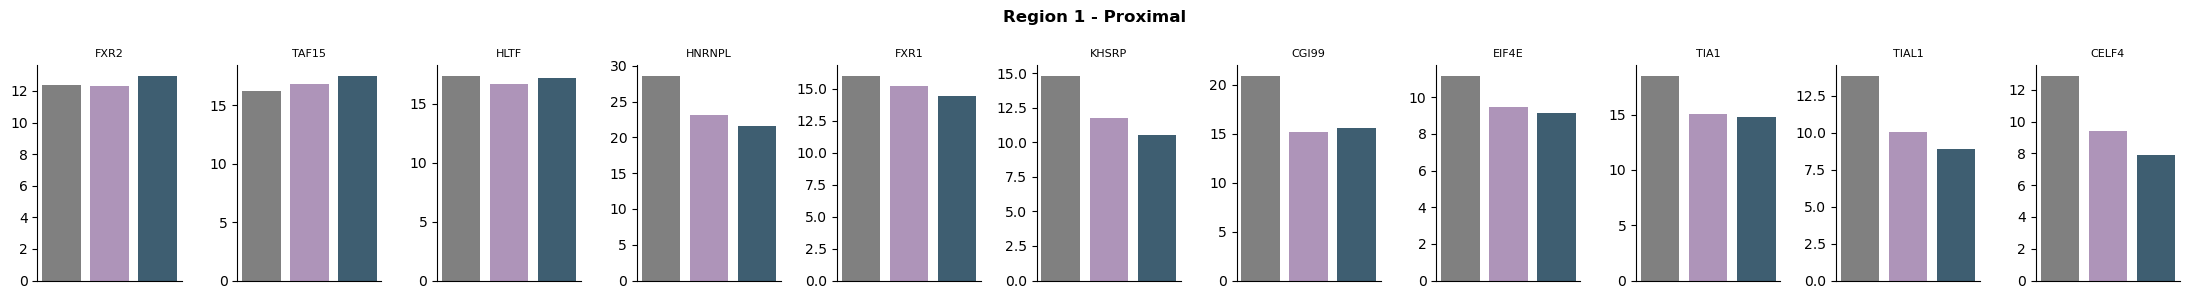

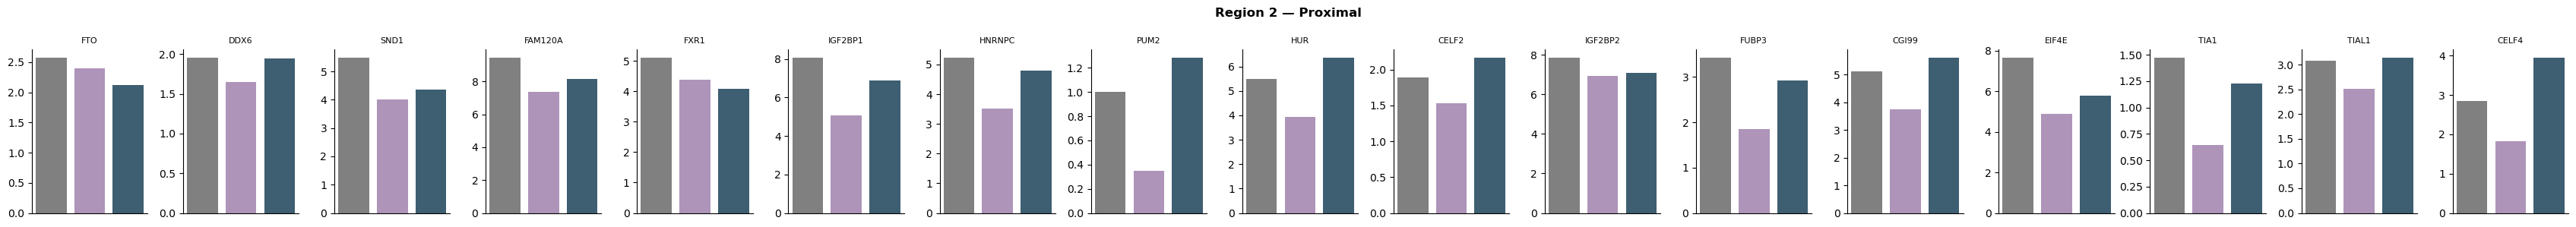

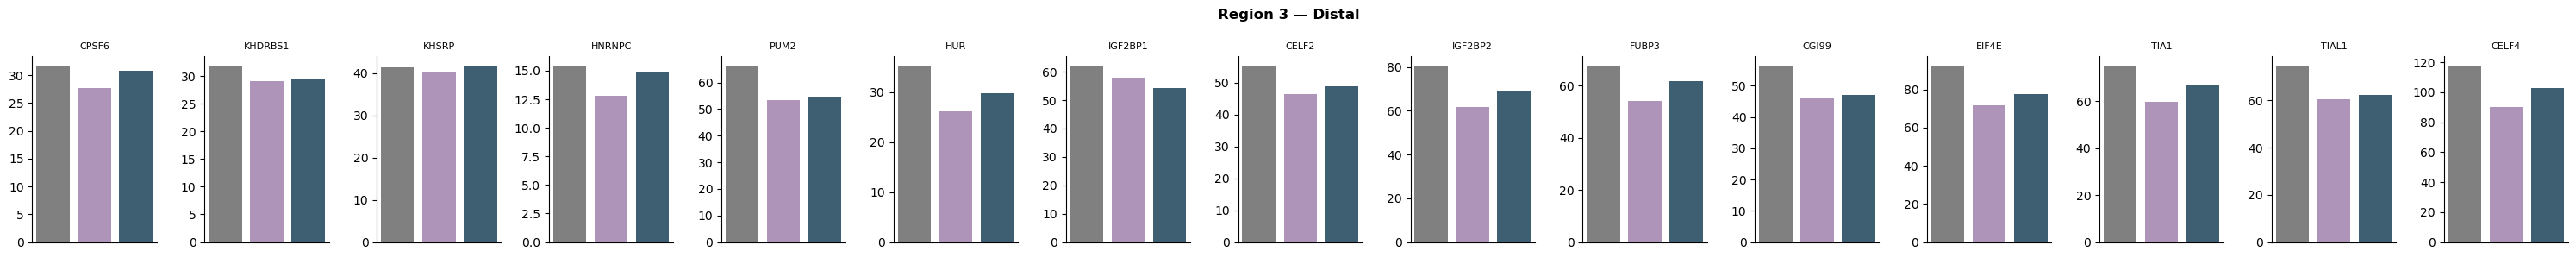

In [51]:

# Barplots for significant RBPs per region
# sig_region1 → region_1 of proximals (max enrichment near pPAS)
# sig_region2 → region_2 of proximals (-min, i.e. depletion downstream)
# sig_region3 → region_1 of distals (negated, so max = enrichment of proximal shift)

treatments_bar = ["Untreated_WT_Nuc", "Untreated_VCP_KI_Nuc", "Ml240_VCP_KI_Nuc"]
palette_bar = ["gray", "#b18ebf", "#35607a"]
region_1 = (-350, 100)
region_2 = (-100, 200)

regions_config = [
    ("Region 1 - Proximal", class_df_R1, df_results_proximals, positive_proximal_region, 'max'),
    ("Region 2 — Proximal", class_df_R2, df_results_proximals, negative_proximal_region, 'negmin'),
    ("Region 3 — Distal", class_df_R3, df_results_distals, positive_distal_region, 'negmin'),
]

for region_title, class_df, df_res, region, mode in regions_config:
    
    
    candidates_nuc_ret = class_df[class_df['category'] == 'Nuclear retention']['regulator'].tolist()
    candidates_apa = class_df[class_df['category'] == 'APA']['regulator'].tolist()
    
    rbp_list = candidates_apa + candidates_nuc_ret
    n = len(rbp_list)
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 3))
    if n == 1:
        axes = [axes]
    for i, rbp in enumerate(rbp_list):
        sub_df = df_res[rbp][[f"-log10(pval)*dPUD_{t}" for t in treatments_bar]].copy()
        sub_df.index = [nb_nucleotides_upstream + j * length_region for j in range(sub_df.shape[0])]
        sub_r = sub_df[(sub_df.index >= region[0]) & (sub_df.index <= region[1])]
        y_vals = sub_r.max().values if mode == 'max' else -sub_r.min().values
        sns.barplot(ax=axes[i], x=treatments_bar, y=y_vals, palette=palette_bar)
        axes[i].set_title(get_RBP_name(rbp), fontsize=8)
        axes[i].set_xticks([])
        axes[i].axhline(0, color='gray', linewidth=0.5)
        sns.despine(ax=axes[i])
    # axes[0].set_ylabel("max -log10(p)·dPUD")
    fig.suptitle(region_title, weight='bold')
    plt.tight_layout()
    save_figure(f"{figures_subfolder}/regulators_VCP-KI_ML240/barplot_R{region_title[7]}_welch_nuclear_VCP-KI_ML240_lengthening_regulators.pdf",
                legend=f"VCP knock-in experiment: R{region_title[7]} score of each of the R{region_title[7]} regulators of "
                    f"lengthening (APA, then nuclear retention), one panel per CLIP dataset, in the nuclear fraction of untreated "
                    f"WT (grey), untreated VCP-KI (light purple) and ML240-treated VCP-KI (dark blue) cells. One value per bar. "
                    f"R1: max Welch score (-log10(p) x dPUD) in [-350, -50] nt upstream of the pPAS; R2: -(min Welch score) in [0, +150] nt downstream of the pPAS (positive = depletion); R3: -(min Welch score) in [-350, -50] nt upstream of the dPAS.")
    plt.show()

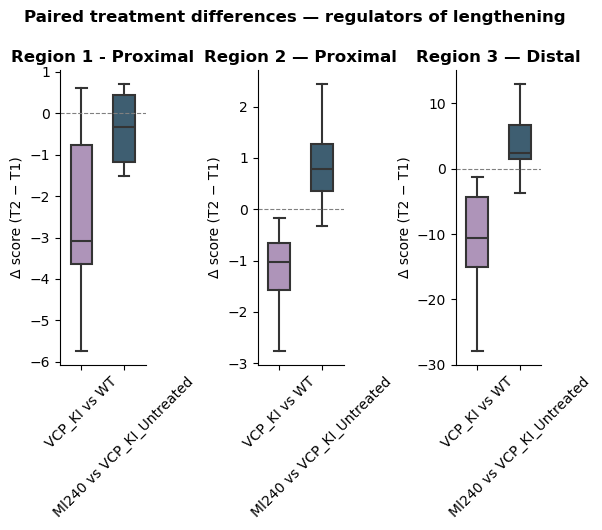

In [52]:

# Boxplots summarising paired differences between treatments, per region
# Each dot/box = one significant RBP; y = score(T2) − score(T1)

treatment_pairs_box = [
    ("Untreated_WT_Nuc",      "Untreated_VCP_KI_Nuc"),   # disease effect
    ("Untreated_VCP_KI_Nuc",  "Ml240_VCP_KI_Nuc"),        # treatment effect
]
pair_labels = ["VCP_KI vs WT", "Ml240 vs VCP_KI_Untreated"]
pair_colors  = ["#b18ebf", "#35607a"]

regions_config = [
    ("Region 1 - Proximal", class_df_R1, df_results_proximals, positive_proximal_region, 'max'),
    ("Region 2 — Proximal", class_df_R2, df_results_proximals, negative_proximal_region, 'negmin'),
    ("Region 3 — Distal", class_df_R3, df_results_distals, positive_distal_region, 'negmin'),
]
i=1
plt.figure(figsize=(6,5))
for region_title, class_df, df_res, region, mode in regions_config:
    
    candidates_nuc_ret = class_df[class_df['category'] == 'Nuclear retention']['regulator'].tolist()
    candidates_apa = class_df[class_df['category'] == 'APA']['regulator'].tolist()
    
    rbp_list = candidates_apa + candidates_nuc_ret
    records = []
    for rbp in rbp_list:
        sub_df = df_res[rbp][[f"-log10(pval)*dPUD_{t}" for t in treatments_bar]].copy()
        sub_df.index = [nb_nucleotides_upstream + j * length_region for j in range(sub_df.shape[0])]
        sub_r = sub_df[(sub_df.index >= region[0]) & (sub_df.index <= region[1])]
        scores = sub_r.max() if mode == 'max' else -sub_r.min()
        for (t1, t2), label in zip(treatment_pairs_box, pair_labels):
            diff = scores[f"-log10(pval)*dPUD_{t2}"] - scores[f"-log10(pval)*dPUD_{t1}"]
            records.append({'RBP': get_RBP_name(rbp), 'comparison': label, 'diff': diff})

    df_box = pd.DataFrame(records)
    
    plt.subplot(1, 3, i)
    sns.boxplot(data=df_box, x='comparison', y='diff', palette=pair_colors, width=0.5, showfliers=False)
    # sns.stripplot(data=df_box, x='comparison', y='diff', color='black',
    #               size=5, ax=ax, jitter=True, alpha=0.7)
    plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    plt.title(region_title, weight='bold')
    plt.xlabel("")
    plt.ylabel("Δ score (T2 − T1)")
    sns.despine()
    plt.xticks(rotation=45)
    i=i+1
plt.tight_layout()

plt.suptitle("Paired treatment differences — regulators of lengthening", weight='bold', y=1.05)
save_figure(f"{figures_subfolder}/regulators_VCP-KI_ML240/boxplot_welch_change_VCP-KI_ML240_lengthening_regulators.pdf",
            legend="VCP knock-in experiment, nuclear fraction: change in region score between untreated VCP-KI and "
                   "untreated WT (purple) and between ML240-treated and untreated VCP-KI (dark blue), for "
                   "the regulators of lengthening of each region (APA and nuclear retention). One panel per region; one value per CLIP dataset; "
                   "boxes without outliers; no statistical test. "
                   "R1: max Welch score (-log10(p) x dPUD) in [-350, -50] nt upstream of the pPAS; R2: -(min Welch score) in [0, +150] nt downstream of the pPAS (positive = depletion); R3: -(min Welch score) in [-350, -50] nt upstream of the dPAS.")



Region 1 - Proximal: 'VCP-KI' vs 'WT', n = 11, median 16.02 -> 15.08, Wilcoxon p = 0.00293
Region 1 - Proximal: 'VCP-KI\n+ ML240' vs 'VCP-KI', n = 11, median 15.08 -> 14.43, Wilcoxon p = 0.206
Region 2 — Proximal: 'VCP-KI' vs 'WT', n = 17, median 5.12 -> 3.52, Wilcoxon p = 1.53e-05
Region 2 — Proximal: 'VCP-KI\n+ ML240' vs 'VCP-KI', n = 17, median 3.52 -> 4.07, Wilcoxon p = 0.000214
Region 3 — Distal: 'VCP-KI' vs 'WT', n = 15, median 62.29 -> 53.35, Wilcoxon p = 6.1e-05
Region 3 — Distal: 'VCP-KI\n+ ML240' vs 'VCP-KI', n = 15, median 53.35 -> 54.16, Wilcoxon p = 0.00262


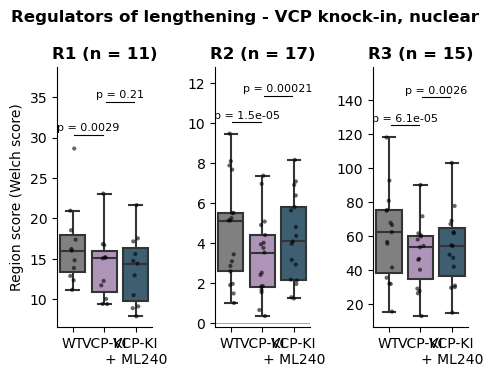

In [53]:
from scipy.stats import wilcoxon

# Region score of the regulators of lengthening in WT, VCP-KI and ML240-treated VCP-KI (nuclear), one panel per region
# Paired Wilcoxon signed-rank tests (same CLIP datasets in every condition): VCP-KI vs WT, ML240 vs untreated VCP-KI
condition_labels = {"Untreated_WT_Nuc": "WT", "Untreated_VCP_KI_Nuc": "VCP-KI", "Ml240_VCP_KI_Nuc": "VCP-KI\n+ ML240"}
test_pairs = [("Untreated_WT_Nuc", "Untreated_VCP_KI_Nuc"), ("Untreated_VCP_KI_Nuc", "Ml240_VCP_KI_Nuc")]

fig, axes = plt.subplots(1, 3, figsize=(5, 3.8))
for ax, (region_title, class_df, df_res, region, mode) in zip(axes, regions_config):
    rbp_list = (class_df[class_df['category'] == 'APA']['regulator'].tolist()
                + class_df[class_df['category'] == 'Nuclear retention']['regulator'].tolist())
    records = []
    for rbp in rbp_list:
        sub_df = df_res[rbp][[f"-log10(pval)*dPUD_{t}" for t in treatments_bar]].copy()
        sub_df.index = [nb_nucleotides_upstream + j * length_region for j in range(sub_df.shape[0])]
        sub_r = sub_df[(sub_df.index >= region[0]) & (sub_df.index <= region[1])]
        scores = sub_r.max() if mode == 'max' else -sub_r.min()
        for t in treatments_bar:
            records.append({'regulator': rbp, 'condition': t, 'score': scores[f"-log10(pval)*dPUD_{t}"]})
    df_ki = pd.DataFrame(records)

    sns.boxplot(data=df_ki, x='condition', y='score', order=treatments_bar, palette=palette_bar,
                showfliers=False, ax=ax)
    sns.stripplot(data=df_ki, x='condition', y='score', order=treatments_bar, color='black',
                  size=3, alpha=0.6, ax=ax)

    paired = df_ki.pivot(index='regulator', columns='condition', values='score')
    ymax, yrange = df_ki['score'].max(), df_ki['score'].max() - min(df_ki['score'].min(), 0)
    for k, (t1, t2) in enumerate(test_pairs):
        pval = wilcoxon(paired[t1], paired[t2]).pvalue
        x1, x2 = treatments_bar.index(t1), treatments_bar.index(t2)
        y = ymax + yrange * (0.06 + 0.14 * k)
        ax.plot([x1 + 0.05, x2 - 0.05], [y, y], color='black', linewidth=0.8)
        ax.text((x1 + x2) / 2, y + yrange * 0.01, f"p = {pval:.2g}", ha='center', va='bottom', fontsize=8)
        print(f"{region_title}: {condition_labels[t2]!r} vs {condition_labels[t1]!r}, n = {len(paired)}, "
              f"median {paired[t1].median():.2f} -> {paired[t2].median():.2f}, Wilcoxon p = {pval:.3g}")
    ax.set_ylim(top=ymax + yrange * 0.35)
    ax.axhline(0, color='gray', linewidth=0.5)
    ax.set_xticks(range(len(treatments_bar)))
    ax.set_xticklabels([condition_labels[t] for t in treatments_bar])
    ax.set_xlabel('')
    ax.set_ylabel('Region score (Welch score)' if ax is axes[0] else '')
    ax.set_title(f"R{region_title[7]} (n = {len(paired)})", weight='bold')
    sns.despine(ax=ax)

plt.suptitle("Regulators of lengthening - VCP knock-in, nuclear", weight='bold')
plt.tight_layout()
save_figure(f"{figures_subfolder}/regulators_VCP-KI_ML240/boxplot_welch_WT_VCP-KI_ML240_lengthening_regulators.pdf",
            legend="VCP knock-in experiment, nuclear fraction: region score of the regulators of lengthening of each "
                   "region (APA and nuclear retention; one point per CLIP dataset) in untreated WT (grey), untreated "
                   "VCP-KI (light purple) and ML240-treated VCP-KI (dark blue) cells. One panel per region, each with "
                   "its own y axis. R1: max Welch score (-log10(p) x dPUD) in [-350, -50] nt upstream of the pPAS; R2: -(min Welch score) in [0, +150] nt downstream of the pPAS (positive = depletion); R3: -(min Welch score) in [-350, -50] nt upstream of the dPAS. Boxes: median and interquartile range, whiskers 1.5 x IQR. p: two-sided "
                   "paired Wilcoxon signed-rank tests, VCP-KI vs WT and ML240-treated vs untreated VCP-KI; n = number "
                   "of CLIP datasets.")
plt.show()

R2 APA: 'VCP-KI' vs 'WT', n = 6, median 5.31 -> 4.20, Wilcoxon p = 0.0312
R2 APA: 'VCP-KI\n+ ML240' vs 'VCP-KI', n = 6, median 4.20 -> 4.21, Wilcoxon p = 0.219
R2 Nuclear retention: 'VCP-KI' vs 'WT', n = 11, median 3.43 -> 2.51, Wilcoxon p = 0.000977
R2 Nuclear retention: 'VCP-KI\n+ ML240' vs 'VCP-KI', n = 11, median 2.51 -> 3.96, Wilcoxon p = 0.000977


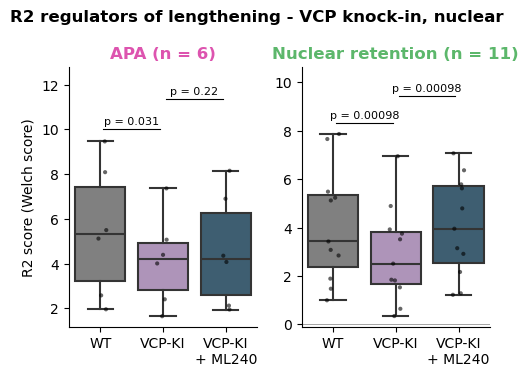

In [54]:
# R2 only, split into APA and nuclear-retention regulators (class from `category`; ambiguous ones left out)
category_palette = {'APA': '#dd54af', 'Nuclear retention': '#5cb76b'}

def boxplot_R2_KI_by_category(class_df, title):
    fig, axes = plt.subplots(1, 2, figsize=(5, 3.8))
    for ax, category in zip(axes, ['APA', 'Nuclear retention']):
        records = []
        for rbp in class_df[class_df['category'] == category]['regulator']:
            sub_df = df_results_proximals[rbp][[f"-log10(pval)*dPUD_{t}" for t in treatments_bar]].copy()
            sub_df.index = [nb_nucleotides_upstream + j * length_region for j in range(sub_df.shape[0])]
            sub_r = sub_df[(sub_df.index >= negative_proximal_region[0]) & (sub_df.index <= negative_proximal_region[1])]
            scores = -sub_r.min()
            for t in treatments_bar:
                records.append({'regulator': rbp, 'condition': t, 'score': scores[f"-log10(pval)*dPUD_{t}"]})
        df_ki = pd.DataFrame(records)

        sns.boxplot(data=df_ki, x='condition', y='score', order=treatments_bar, palette=palette_bar,
                    showfliers=False, ax=ax)
        sns.stripplot(data=df_ki, x='condition', y='score', order=treatments_bar, color='black',
                      size=3, alpha=0.6, ax=ax)

        # Paired Wilcoxon signed-rank tests (same CLIP datasets in every condition)
        paired = df_ki.pivot(index='regulator', columns='condition', values='score')
        ymax, yrange = df_ki['score'].max(), df_ki['score'].max() - min(df_ki['score'].min(), 0)
        for k, (t1, t2) in enumerate(test_pairs):
            pval = wilcoxon(paired[t1], paired[t2]).pvalue
            x1, x2 = treatments_bar.index(t1), treatments_bar.index(t2)
            y = ymax + yrange * (0.06 + 0.14 * k)
            ax.plot([x1 + 0.05, x2 - 0.05], [y, y], color='black', linewidth=0.8)
            ax.text((x1 + x2) / 2, y + yrange * 0.01, f"p = {pval:.2g}", ha='center', va='bottom', fontsize=8)
            print(f"R2 {category}: {condition_labels[t2]!r} vs {condition_labels[t1]!r}, n = {len(paired)}, "
                  f"median {paired[t1].median():.2f} -> {paired[t2].median():.2f}, Wilcoxon p = {pval:.3g}")
        ax.set_ylim(top=ymax + yrange * 0.35)
        ax.axhline(0, color='gray', linewidth=0.5)
        ax.set_xticks(range(len(treatments_bar)))
        ax.set_xticklabels([condition_labels[t] for t in treatments_bar])
        ax.set_xlabel('')
        ax.set_ylabel('R2 score (Welch score)' if category == 'APA' else '')
        ax.set_title(f"{category} (n = {len(paired)})", color=category_palette[category], weight='bold')
        sns.despine(ax=ax)
    plt.suptitle(title, weight='bold')
    plt.tight_layout()


boxplot_R2_KI_by_category(class_df_R2, "R2 regulators of lengthening - VCP knock-in, nuclear")
save_figure(f"{figures_subfolder}/regulators_VCP-KI_ML240/boxplot_R2_welch_WT_VCP-KI_ML240_lengthening_regulators_APA_vs_NR.pdf",
            legend="VCP knock-in experiment, nuclear fraction: R2 score of the R2 regulators of lengthening, split "
                   "into APA (left) and nuclear-retention (right) regulators (class_df_R2: significant R2 score in both "
                   "fractions, or in the nucleus only, of CTRL at D35 in the MN differentiation data), in untreated WT "
                   "(grey), untreated VCP-KI (light purple) and ML240-treated VCP-KI (dark blue) cells. One point per "
                   "CLIP dataset; each panel has its own y axis. R2 score: -(min Welch score (-log10(p) x dPUD)) in [0, +150] nt downstream of the pPAS (positive = depletion). Boxes: median and interquartile range, whiskers 1.5 x IQR. p: two-sided paired Wilcoxon signed-rank tests, VCP-KI vs WT and ML240-treated vs untreated VCP-KI; n = number of CLIP datasets.")
plt.show()

,regulator,RBP,nuclear_max,cyto_max,category,nuc_cyto_diff
4,m6A,m6A,4.584721,9.68773,APA,-5.103009


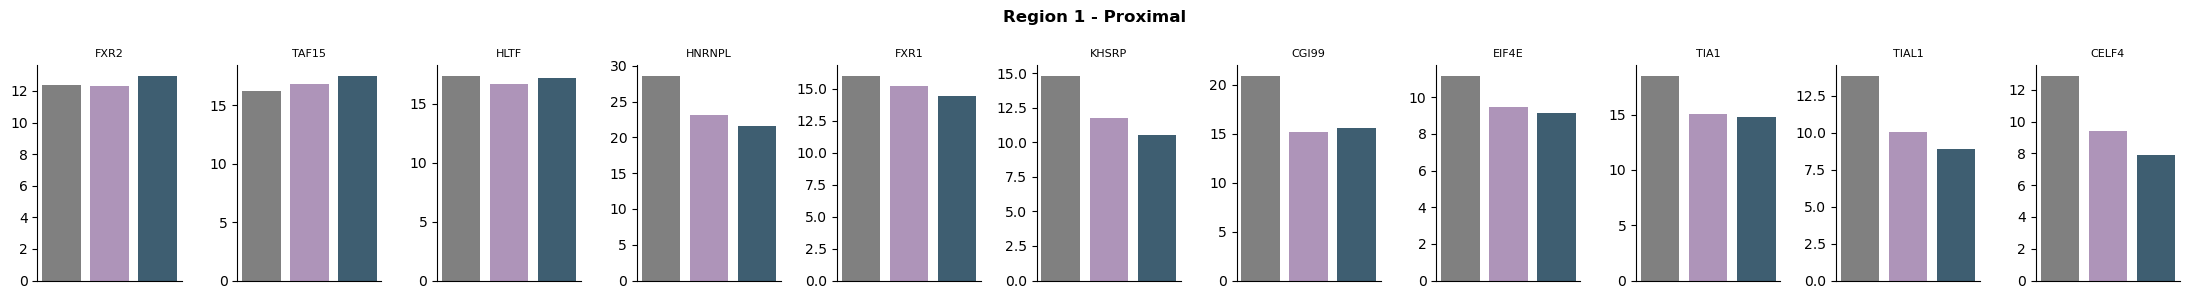

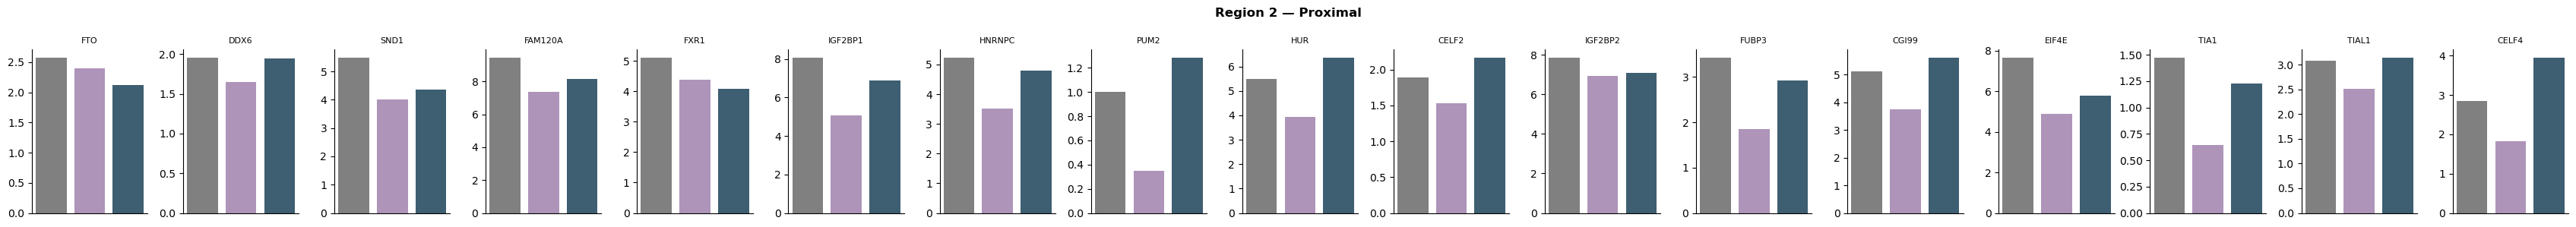

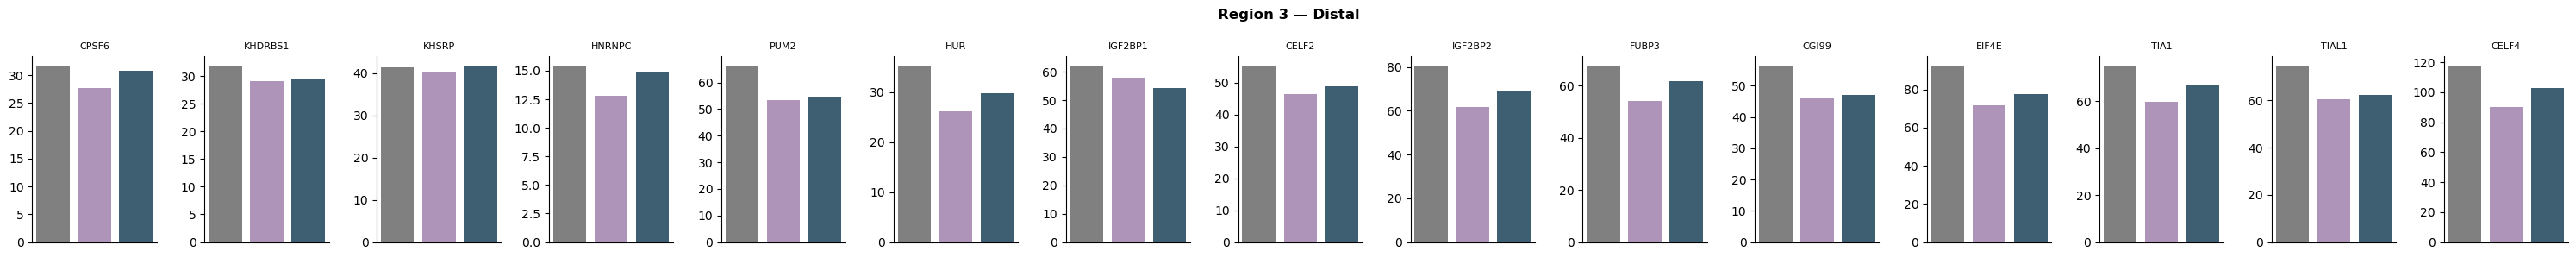

In [55]:

# Barplots for significant RBPs per region
# sig_region1 → region_1 of proximals (max enrichment near pPAS)
# sig_region2 → region_2 of proximals (-min, i.e. depletion downstream)
# sig_region3 → region_1 of distals (negated, so max = enrichment of proximal shift)

treatments_bar = ["Untreated_WT_Nuc", "Untreated_VCP_KI_Nuc", "Ml240_VCP_KI_Nuc"]
palette_bar = ["gray", "#b18ebf", "#35607a"]
region_1 = (-350, 100)
region_2 = (-100, 200)

regions_config = [
    ("Region 1 - Proximal", class_df_R1, df_results_proximals, positive_proximal_region, 'max'),
    ("Region 2 — Proximal", class_df_R2, df_results_proximals, negative_proximal_region, 'negmin'),
    ("Region 3 — Distal", class_df_R3, df_results_distals, positive_distal_region, 'negmin'),
]

for region_title, class_df, df_res, region, mode in regions_config:
    
    
    candidates_nuc_ret = class_df[class_df['category'] == 'Nuclear retention']['regulator'].tolist()
    candidates_apa = class_df[class_df['category'] == 'APA']['regulator'].tolist()
    
    rbp_list = candidates_apa + candidates_nuc_ret
    n = len(rbp_list)
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 3))
    if n == 1:
        axes = [axes]
    for i, rbp in enumerate(rbp_list):
        sub_df = df_res[rbp][[f"-log10(pval)*dPUD_{t}" for t in treatments_bar]].copy()
        sub_df.index = [nb_nucleotides_upstream + j * length_region for j in range(sub_df.shape[0])]
        sub_r = sub_df[(sub_df.index >= region[0]) & (sub_df.index <= region[1])]
        y_vals = sub_r.max().values if mode == 'max' else -sub_r.min().values
        sns.barplot(ax=axes[i], x=treatments_bar, y=y_vals, palette=palette_bar)
        axes[i].set_title(get_RBP_name(rbp), fontsize=8)
        axes[i].set_xticks([])
        axes[i].axhline(0, color='gray', linewidth=0.5)
        sns.despine(ax=axes[i])
    # axes[0].set_ylabel("max -log10(p)·dPUD")
    fig.suptitle(region_title, weight='bold')
    plt.tight_layout()
    save_figure(f"{figures_subfolder}/regulators_VCP-KI_ML240/barplot_R{region_title[7]}_welch_nuclear_VCP-KI_ML240_regulators_of_shortening_in_VCP.pdf",
                legend=f"VCP knock-in experiment: R{region_title[7]} score of each of the R{region_title[7]} regulators of "
                    f"shortening in VCP (VCP vs CTRL at D35), one panel per CLIP dataset, in the nuclear fraction of untreated "
                    f"WT (grey), untreated VCP-KI (light purple) and ML240-treated VCP-KI (dark blue) cells. One value per bar. "
                    f"R1: max Welch score (-log10(p) x dPUD) in [-350, -50] nt upstream of the pPAS; R2: -(min Welch score) in [0, +150] nt downstream of the pPAS (positive = depletion); R3: -(min Welch score) in [-350, -50] nt upstream of the dPAS.")
    plt.show()

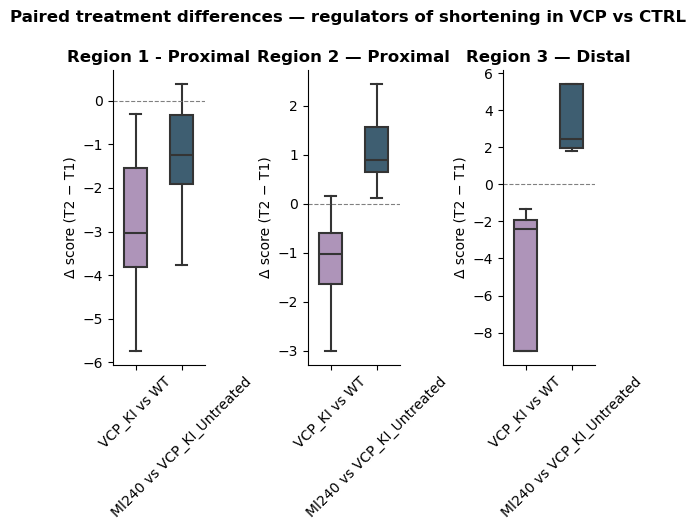

In [56]:

# Boxplots summarising paired differences between treatments, per region
# Each dot/box = one significant RBP; y = score(T2) − score(T1)

treatment_pairs_box = [
    ("Untreated_WT_Nuc",      "Untreated_VCP_KI_Nuc"),   # disease effect
    ("Untreated_VCP_KI_Nuc",  "Ml240_VCP_KI_Nuc"),        # treatment effect
]
pair_labels = ["VCP_KI vs WT", "Ml240 vs VCP_KI_Untreated"]
pair_colors  = ["#b18ebf", "#35607a"]

regions_config = [
    ("Region 1 - Proximal", candidates_vcp_R1, df_results_proximals, positive_proximal_region, 'max'),
    ("Region 2 — Proximal", candidates_vcp_R2, df_results_proximals, negative_proximal_region, 'negmin'),
    ("Region 3 — Distal", candidates_vcp_R3, df_results_distals, positive_distal_region, 'negmin'),
]
i=1
plt.figure(figsize=(6,5))
for region_title, rbp_list, df_res, region, mode in regions_config:
    
    records = []
    for rbp in rbp_list:
        sub_df = df_res[rbp][[f"-log10(pval)*dPUD_{t}" for t in treatments_bar]].copy()
        sub_df.index = [nb_nucleotides_upstream + j * length_region for j in range(sub_df.shape[0])]
        sub_r = sub_df[(sub_df.index >= region[0]) & (sub_df.index <= region[1])]
        scores = sub_r.max() if mode == 'max' else -sub_r.min()
        for (t1, t2), label in zip(treatment_pairs_box, pair_labels):
            diff = scores[f"-log10(pval)*dPUD_{t2}"] - scores[f"-log10(pval)*dPUD_{t1}"]
            records.append({'RBP': get_RBP_name(rbp), 'comparison': label, 'diff': diff})

    df_box = pd.DataFrame(records)
    
    plt.subplot(1, 3, i)
    sns.boxplot(data=df_box, x='comparison', y='diff', palette=pair_colors, width=0.5, showfliers=False)
    # sns.stripplot(data=df_box, x='comparison', y='diff', color='black',
    #               size=5, ax=ax, jitter=True, alpha=0.7)
    plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    plt.title(region_title, weight='bold')
    plt.xlabel("")
    plt.ylabel("Δ score (T2 − T1)")
    sns.despine()
    plt.xticks(rotation=45)
    i=i+1
plt.tight_layout()

plt.suptitle("Paired treatment differences — regulators of shortening in VCP vs CTRL", weight='bold', y=1.05)
save_figure(f"{figures_subfolder}/regulators_VCP-KI_ML240/boxplot_welch_change_VCP-KI_ML240_shortening_in_VCP_regulators.pdf",
            legend="VCP knock-in experiment, nuclear fraction: change in region score between untreated VCP-KI and "
                   "untreated WT (purple) and between ML240-treated and untreated VCP-KI (dark blue), for "
                   "the regulators of shortening in VCP of each region. One panel per region; one value per CLIP dataset; "
                   "boxes without outliers; no statistical test. "
                   "R1: max Welch score (-log10(p) x dPUD) in [-350, -50] nt upstream of the pPAS; R2: -(min Welch score) in [0, +150] nt downstream of the pPAS (positive = depletion); R3: -(min Welch score) in [-350, -50] nt upstream of the dPAS.")


Region 1 - Proximal: 'VCP-KI' vs 'WT', n = 15, median 20.96 -> 19.44, Wilcoxon p = 6.1e-05
Region 1 - Proximal: 'VCP-KI\n+ ML240' vs 'VCP-KI', n = 15, median 19.44 -> 17.10, Wilcoxon p = 0.0946
Region 2 — Proximal: 'VCP-KI' vs 'WT', n = 15, median 3.43 -> 2.51, Wilcoxon p = 0.000122
Region 2 — Proximal: 'VCP-KI\n+ ML240' vs 'VCP-KI', n = 15, median 2.51 -> 3.96, Wilcoxon p = 6.1e-05
Region 3 — Distal: 'VCP-KI' vs 'WT', n = 4, median 28.45 -> 26.45, Wilcoxon p = 0.125
Region 3 — Distal: 'VCP-KI\n+ ML240' vs 'VCP-KI', n = 4, median 26.45 -> 28.36, Wilcoxon p = 0.125


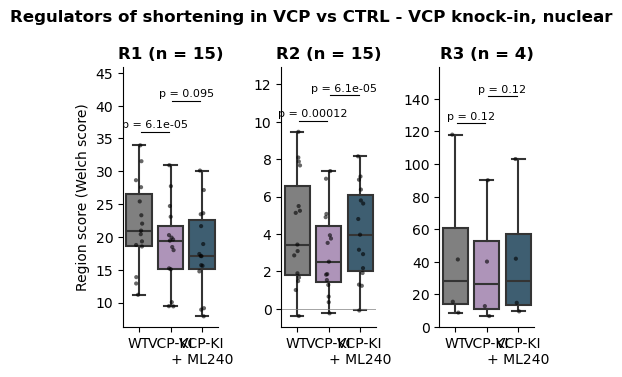

In [57]:
# Region score of the regulators of shortening in VCP in WT, VCP-KI and ML240-treated VCP-KI (nuclear), one panel per region
# Paired Wilcoxon signed-rank tests (same CLIP datasets in every condition): VCP-KI vs WT, ML240 vs untreated VCP-KI
condition_labels = {"Untreated_WT_Nuc": "WT", "Untreated_VCP_KI_Nuc": "VCP-KI", "Ml240_VCP_KI_Nuc": "VCP-KI\n+ ML240"}
test_pairs = [("Untreated_WT_Nuc", "Untreated_VCP_KI_Nuc"), ("Untreated_VCP_KI_Nuc", "Ml240_VCP_KI_Nuc")]

fig, axes = plt.subplots(1, 3, figsize=(5, 3.8))
for ax, (region_title, rbp_list, df_res, region, mode) in zip(axes, regions_config):
    records = []
    for rbp in rbp_list:
        sub_df = df_res[rbp][[f"-log10(pval)*dPUD_{t}" for t in treatments_bar]].copy()
        sub_df.index = [nb_nucleotides_upstream + j * length_region for j in range(sub_df.shape[0])]
        sub_r = sub_df[(sub_df.index >= region[0]) & (sub_df.index <= region[1])]
        scores = sub_r.max() if mode == 'max' else -sub_r.min()
        for t in treatments_bar:
            records.append({'regulator': rbp, 'condition': t, 'score': scores[f"-log10(pval)*dPUD_{t}"]})
    df_ki = pd.DataFrame(records)

    sns.boxplot(data=df_ki, x='condition', y='score', order=treatments_bar, palette=palette_bar,
                showfliers=False, ax=ax)
    sns.stripplot(data=df_ki, x='condition', y='score', order=treatments_bar, color='black',
                  size=3, alpha=0.6, ax=ax)

    paired = df_ki.pivot(index='regulator', columns='condition', values='score')
    ymax, yrange = df_ki['score'].max(), df_ki['score'].max() - min(df_ki['score'].min(), 0)
    for k, (t1, t2) in enumerate(test_pairs):
        pval = wilcoxon(paired[t1], paired[t2]).pvalue
        x1, x2 = treatments_bar.index(t1), treatments_bar.index(t2)
        y = ymax + yrange * (0.06 + 0.14 * k)
        ax.plot([x1 + 0.05, x2 - 0.05], [y, y], color='black', linewidth=0.8)
        ax.text((x1 + x2) / 2, y + yrange * 0.01, f"p = {pval:.2g}", ha='center', va='bottom', fontsize=8)
        print(f"{region_title}: {condition_labels[t2]!r} vs {condition_labels[t1]!r}, n = {len(paired)}, "
              f"median {paired[t1].median():.2f} -> {paired[t2].median():.2f}, Wilcoxon p = {pval:.3g}")
    ax.set_ylim(top=ymax + yrange * 0.35)
    ax.axhline(0, color='gray', linewidth=0.5)
    ax.set_xticks(range(len(treatments_bar)))
    ax.set_xticklabels([condition_labels[t] for t in treatments_bar])
    ax.set_xlabel('')
    ax.set_ylabel('Region score (Welch score)' if ax is axes[0] else '')
    ax.set_title(f"R{region_title[7]} (n = {len(paired)})", weight='bold')
    sns.despine(ax=ax)

plt.suptitle("Regulators of shortening in VCP vs CTRL - VCP knock-in, nuclear", weight='bold')
plt.tight_layout()
save_figure(f"{figures_subfolder}/regulators_VCP-KI_ML240/boxplot_welch_WT_VCP-KI_ML240_shortening_in_VCP_regulators.pdf",
            legend="VCP knock-in experiment, nuclear fraction: region score of the regulators of shortening in VCP "
                   "of each region (VCP vs CTRL at D35; one point per CLIP dataset) in untreated WT (grey), untreated "
                   "VCP-KI (light purple) and ML240-treated VCP-KI (dark blue) cells. One panel per region, each with "
                   "its own y axis. R1: max Welch score (-log10(p) x dPUD) in [-350, -50] nt upstream of the pPAS; R2: -(min Welch score) in [0, +150] nt downstream of the pPAS (positive = depletion); R3: -(min Welch score) in [-350, -50] nt upstream of the dPAS. Boxes: median and interquartile range, whiskers 1.5 x IQR. p: two-sided "
                   "paired Wilcoxon signed-rank tests, VCP-KI vs WT and ML240-treated vs untreated VCP-KI; n = number "
                   "of CLIP datasets.")
plt.show()

R2 APA: 'VCP-KI' vs 'WT', n = 2, median 8.77 -> 6.21, Wilcoxon p = 0.5
R2 APA: 'VCP-KI\n+ ML240' vs 'VCP-KI', n = 2, median 6.21 -> 7.52, Wilcoxon p = 0.5
R2 Nuclear retention: 'VCP-KI' vs 'WT', n = 13, median 3.08 -> 1.85, Wilcoxon p = 0.000488
R2 Nuclear retention: 'VCP-KI\n+ ML240' vs 'VCP-KI', n = 13, median 1.85 -> 3.15, Wilcoxon p = 0.000244


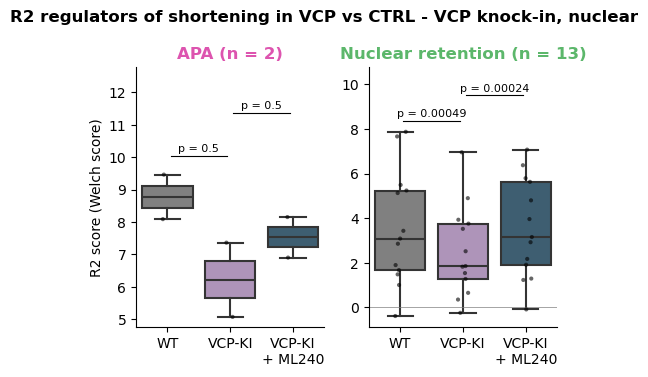

In [58]:
# Same for the R2 regulators of shortening in VCP, classified in class_df_vcp (one CLIP per RBP, as in the Venn diagram)
boxplot_R2_KI_by_category(class_df_vcp, "R2 regulators of shortening in VCP vs CTRL - VCP knock-in, nuclear")
save_figure(f"{figures_subfolder}/regulators_VCP-KI_ML240/boxplot_R2_welch_WT_VCP-KI_ML240_shortening_in_VCP_regulators_APA_vs_NR.pdf",
            legend="VCP knock-in experiment, nuclear fraction: R2 score of the R2 regulators of shortening in VCP (VCP vs "
                   "CTRL at D35 in the MN differentiation data), split into APA (left) and nuclear-retention (right) "
                   "regulators (class_df_vcp: significant R2 score in both fractions, or in the nucleus only, of CTRL at "
                   "D35; one CLIP dataset per RBP; ambiguous ones left out), in untreated WT (grey), untreated VCP-KI "
                   "(light purple) and ML240-treated VCP-KI (dark blue) cells. One point per CLIP dataset; each panel "
                   "has its own y axis. R2 score: -(min Welch score (-log10(p) x dPUD)) in [0, +150] nt downstream of the pPAS (positive = depletion). Boxes: median and interquartile range, whiskers 1.5 x IQR. p: two-sided paired Wilcoxon signed-rank tests, VCP-KI vs WT and ML240-treated vs untreated VCP-KI; n = number of CLIP datasets.")
plt.show()

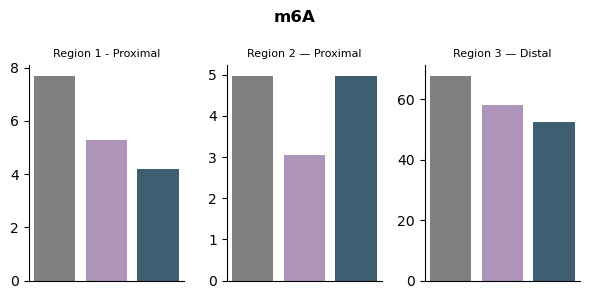

In [59]:
# m6A in VCP knock-in cells ± ML240: score of m6A in each region (same definition as the regulator barplots)
path_to_m6A_welch = f"{PROJECT_DIR}/VCP-KI-Ml240/results/RNA_modifs/m6A/welch"
m6A_proximal = load_and_combine_integrated_CLIP(path_to_m6A_welch, prefix='proximal')["hg38.m6A.gff_RMBase"]
m6A_distal = load_and_combine_integrated_CLIP(path_to_m6A_welch, prefix='distal')["hg38.m6A.gff_RMBase"]

regions_config_m6A = [
    ("Region 1 - Proximal", m6A_proximal, positive_proximal_region, 'max'),
    ("Region 2 — Proximal", m6A_proximal, negative_proximal_region, 'negmin'),
    ("Region 3 — Distal", m6A_distal, positive_distal_region, 'negmin'),
]

fig, axes = plt.subplots(1, 3, figsize=(6, 3))
for ax, (region_title, df_m6A, region, mode) in zip(axes, regions_config_m6A):
    sub_df = df_m6A[[f"-log10(pval)*dPUD_{t}" for t in treatments_bar]].copy()
    sub_df.index = [nb_nucleotides_upstream + j * length_region for j in range(sub_df.shape[0])]
    sub_r = sub_df[(sub_df.index >= region[0]) & (sub_df.index <= region[1])]
    y_vals = sub_r.max().values if mode == 'max' else -sub_r.min().values
    sns.barplot(ax=ax, x=treatments_bar, y=y_vals, palette=palette_bar)
    ax.set_title(region_title, fontsize=8)
    ax.set_xticks([])
    ax.axhline(0, color='gray', linewidth=0.5)
    sns.despine(ax=ax)
fig.suptitle("m6A", weight='bold')
plt.tight_layout()
save_figure(f"{figures_subfolder}/regulators_VCP-KI_ML240/barplot_R1_R2_R3_welch_nuclear_VCP-KI_ML240_m6A.pdf",
            legend="VCP knock-in experiment, nuclear fraction: Welch score of m6A sites in each region, in untreated WT (grey), untreated "
                   "VCP-KI (light purple) and ML240-treated VCP-KI (dark blue) cells. R1 = max Welch score in [-350, -50] nt upstream of the pPAS; "
                   "R2 = -min Welch score in [0, +150] nt downstream of the pPAS; R3 = -min Welch score in [-350, -50] nt upstream of the dPAS.")
plt.show()

In [60]:

# # Boxplots summarising paired differences between treatments, per region
# # Each dot/box = one significant RBP; y = score(T2) − score(T1)

# treatment_pairs_box = [
#     ("Untreated_WT_Nuc",      "Untreated_VCP_KI_Nuc"),   # disease effect
#     ("Untreated_VCP_KI_Nuc",  "Ml240_VCP_KI_Nuc"),        # treatment effect
# ]
# pair_labels = ["VCP_KI vs WT", "Ml240 vs VCP_KI_Untreated"]
# pair_colors  = ["#b18ebf", "#35607a"]

# regions_config_box = [
    
#     ("Region 2\n(Proximal)", common_clip_list, df_results_proximals, region_2, 'negmin'),
# ]
# region_title="Region 2\n(Proximal)"
# rbp_list=common_clip_list
# df_res=df_results_proximals
# region=region_2
# mode = 'negmin'

# plt.figure(figsize=(2,5))
# # for ax, (region_title, rbp_list, df_res, region, mode) in zip(axes, regions_config_box):
# records = []
# for rbp in rbp_list:
#     sub_df = df_res[rbp][[f"-log10(pval)*dPUD_{t}" for t in treatments_bar]].copy()
#     sub_df.index = [nb_nucleotides_upstream + j * length_region for j in range(sub_df.shape[0])]
#     sub_r = sub_df[(sub_df.index >= region[0]) & (sub_df.index <= region[1])]
#     scores = sub_r.max() if mode == 'max' else -sub_r.min()
#     for (t1, t2), label in zip(treatment_pairs_box, pair_labels):
#         diff = scores[f"-log10(pval)*dPUD_{t2}"] - scores[f"-log10(pval)*dPUD_{t1}"]
#         records.append({'RBP': get_RBP_name(rbp), 'comparison': label, 'diff': diff})

# df_box = pd.DataFrame(records)
# sns.boxplot(data=df_box, x='comparison', y='diff', palette=pair_colors, width=0.5, showfliers=False)
# # sns.stripplot(data=df_box, x='comparison', y='diff', color='black',
# #               size=5, ax=ax, jitter=True, alpha=0.7)
# plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
# plt.title(region_title, weight='bold')
# plt.xlabel("")
# plt.ylabel("Δ score (T2 − T1)")
# sns.despine()

# fig.suptitle("Paired treatment differences — significant RBPs per region", weight='bold')
# save_figure(f"{figures_subfolder}/regulators_VCP-KI_ML240/boxplot_R2_depletion_change_VCP-KI_ML240_common_regulators.pdf",
#             legend="VCP knock-in experiment, nuclear fraction: change in R2 depletion score (-min Welch score in [-100, +200] nt around the pPAS, a wider window than R2) between untreated VCP-KI and untreated WT (purple) and between ML240-treated and untreated VCP-KI (dark blue), for the 'common' R2 regulators (RBPs in the common part of both Venn diagrams: R2 regulators of both lengthening and the VCP effect, with the same APA or nuclear-retention class; all their CLIP datasets). One value per CLIP dataset; boxes without outliers; no statistical test.")



In [61]:

# # Boxplots summarising paired differences between treatments, per region
# # Each dot/box = one significant RBP; y = score(T2) − score(T1)

# treatment_pairs_box = [
#     ("Untreated_WT_Nuc",      "Untreated_VCP_KI_Nuc"),   # disease effect
#     ("Untreated_VCP_KI_Nuc",  "Ml240_VCP_KI_Nuc"),        # treatment effect
# ]
# pair_labels = ["VCP_KI vs WT", "Ml240 vs VCP_KI_Untreated"]
# pair_colors  = ["#b18ebf", "#35607a"]

# regions_config_box = [
#     ("Region 2\n(Proximal)", common_apa_clip_list, df_results_proximals, region_2, 'negmin'),
# ]
# region_title="Region 2\n(Proximal)"
# rbp_list=common_apa_clip_list
# df_res=df_results_proximals
# region=region_2
# mode = 'negmin'

# plt.figure(figsize=(2,5))
# # for ax, (region_title, rbp_list, df_res, region, mode) in zip(axes, regions_config_box):
# records = []
# for rbp in rbp_list:
#     sub_df = df_res[rbp][[f"-log10(pval)*dPUD_{t}" for t in treatments_bar]].copy()
#     sub_df.index = [nb_nucleotides_upstream + j * length_region for j in range(sub_df.shape[0])]
#     sub_r = sub_df[(sub_df.index >= region[0]) & (sub_df.index <= region[1])]
#     scores = sub_r.max() if mode == 'max' else -sub_r.min()
#     for (t1, t2), label in zip(treatment_pairs_box, pair_labels):
#         diff = scores[f"-log10(pval)*dPUD_{t2}"] - scores[f"-log10(pval)*dPUD_{t1}"]
#         records.append({'RBP': get_RBP_name(rbp), 'comparison': label, 'diff': diff})

# df_box = pd.DataFrame(records)
# sns.boxplot(data=df_box, x='comparison', y='diff', palette=pair_colors, width=0.5, showfliers=False)
# # sns.stripplot(data=df_box, x='comparison', y='diff', color='black',
# #               size=5, ax=ax, jitter=True, alpha=0.7)
# plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
# plt.title(region_title, weight='bold')
# plt.xlabel("")
# plt.ylabel("Δ score (T2 − T1)")
# sns.despine()

# fig.suptitle("Paired treatment differences — significant RBPs per region", weight='bold')
# save_figure(f"{figures_subfolder}/regulators_VCP-KI_ML240/boxplot_R2_depletion_change_VCP-KI_ML240_common_APA_regulators.pdf",
#             legend="VCP knock-in experiment, nuclear fraction: change in R2 depletion score (-min Welch score in [-100, +200] nt around the pPAS, a wider window than R2) between untreated VCP-KI and untreated WT (purple) and between ML240-treated and untreated VCP-KI (dark blue), for the common R2 regulators classified APA. One value per CLIP dataset; boxes without outliers; no statistical test.")



In [62]:

# # Boxplots summarising paired differences between treatments, per region
# # Each dot/box = one significant RBP; y = score(T2) − score(T1)

# treatment_pairs_box = [
#     ("Untreated_WT_Nuc",      "Untreated_VCP_KI_Nuc"),   # disease effect
#     ("Untreated_VCP_KI_Nuc",  "Ml240_VCP_KI_Nuc"),        # treatment effect
# ]
# pair_labels = ["VCP_KI vs WT", "Ml240 vs VCP_KI_Untreated"]
# pair_colors  = ["#b18ebf", "#35607a"]

# regions_config_box = [
#     ("Region 2\n(Proximal)", common_nr_clip_list, df_results_proximals, region_2, 'negmin'),
# ]
# region_title="Region 2\n(Proximal)"
# rbp_list=common_nr_clip_list
# df_res=df_results_proximals
# region=region_2
# mode = 'negmin'

# plt.figure(figsize=(2,5))
# # for ax, (region_title, rbp_list, df_res, region, mode) in zip(axes, regions_config_box):
# records = []
# for rbp in rbp_list:
#     sub_df = df_res[rbp][[f"-log10(pval)*dPUD_{t}" for t in treatments_bar]].copy()
#     sub_df.index = [nb_nucleotides_upstream + j * length_region for j in range(sub_df.shape[0])]
#     sub_r = sub_df[(sub_df.index >= region[0]) & (sub_df.index <= region[1])]
#     scores = sub_r.max() if mode == 'max' else -sub_r.min()
#     for (t1, t2), label in zip(treatment_pairs_box, pair_labels):
#         diff = scores[f"-log10(pval)*dPUD_{t2}"] - scores[f"-log10(pval)*dPUD_{t1}"]
#         records.append({'RBP': get_RBP_name(rbp), 'comparison': label, 'diff': diff})

# df_box = pd.DataFrame(records)
# sns.boxplot(data=df_box, x='comparison', y='diff', palette=pair_colors, width=0.5, showfliers=False)
# # sns.stripplot(data=df_box, x='comparison', y='diff', color='black',
# #               size=5, ax=ax, jitter=True, alpha=0.7)
# plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
# plt.title(region_title, weight='bold')
# plt.xlabel("")
# plt.ylabel("Δ score (T2 − T1)")
# sns.despine()

# fig.suptitle("Paired treatment differences — significant RBPs per region", weight='bold')
# save_figure(f"{figures_subfolder}/regulators_VCP-KI_ML240/boxplot_R2_depletion_change_VCP-KI_ML240_common_NR_regulators.pdf",
#             legend="VCP knock-in experiment, nuclear fraction: change in R2 depletion score (-min Welch score in [-100, +200] nt around the pPAS, a wider window than R2) between untreated VCP-KI and untreated WT (purple) and between ML240-treated and untreated VCP-KI (dark blue), for the common R2 regulators classified nuclear retention. One value per CLIP dataset; boxes without outliers; no statistical test.")


<a id="lncrna-crosslinks"></a>
## Cross-links of the Region 2 regulators on condensate-associated lncRNAs

CLIP cross-link density (sites per million) of every CLIP dataset on NEAT1, XIST, MALAT1, NORAD and SFPQ (`MN_diff/results/paraspeckles/<gene>/<gene>_cross_links.csv`). CLIPs are grouped as R2 regulators of lengthening classified APA or nuclear retention (NR), or Other. The R2 CLIP names are first converted to the naming of the cross-link tables (`all` / `bestof` iCLIPs → `<RBP>_iCLIP`). Boxes without outliers, one dot per CLIP, two-sided Mann–Whitney U (Other vs NR, Other vs APA; `statannotations`).

Saved: `regulators_lncRNA_crosslinks/boxplot_crosslinks_<gene>_R2_regulators_APA_vs_NR.pdf`, one file per transcript.

In [63]:
path_to_paraspeckles = f"{PROJECT_DIR}/MN_diff/results/paraspeckles"

In [64]:
palette

{'APA': '#dd54af', 'Nuclear retention': '#5cb76b'}

In [65]:
from statannotations.Annotator import Annotator

def get_cross_links_on_gene(path_to_paraspeckles, gene, candidates_apa, candidates_nr):

    df = pd.read_csv(os.path.join(path_to_paraspeckles, gene, f"{gene}_cross_links.csv"))
    df['clip'] = df['clip'].apply(lambda x: x.upper().replace('ICLIP', 'iCLIP'))
    df["Category"] = df["clip"].apply(lambda x: "APA" if x in candidates_apa else ("NR" if x in candidates_nr else "Other"))

    # Filter outliers per category for stripplot (IQR method, same as boxplot whiskers)
    def remove_outliers(group):
        q1 = group["n_cross_links"].quantile(0.25)
        q3 = group["n_cross_links"].quantile(0.75)
        iqr = q3 - q1
        return group[(group["n_cross_links"] >= q1 - 1.5 * iqr) & (group["n_cross_links"] <= q3 + 1.5 * iqr)]

    df_no_outliers = df.groupby("Category", group_keys=False).apply(remove_outliers)

    plt.figure(figsize=(2, 6))
    ax = sns.boxplot(
        data=df,
        x="Category",
        y="n_cross_links",
        order=["Other", "NR", "APA"],
        palette={"Other": 'gray', "NR": '#5cb76b', "APA": '#dd54af'},
        showfliers=False,
    )
    sns.stripplot(
        data=df,
        x="Category",
        y="n_cross_links",
        order=["Other", "NR", "APA"],
        color="black",
        alpha=0.5,
        ax=ax,
    )

    pairs = [("Other", "NR"), ("Other", "APA")]
    annotator = Annotator(
        ax,
        pairs,
        data=df,
        x="Category",
        y="n_cross_links",
        order=["Other", "NR", "APA"],
    )
    annotator.configure(test="Mann-Whitney", text_format="full", loc="inside")
    annotator.apply_and_annotate()

    sns.despine()
    plt.title(f"Cross-links in {gene}", weight='bold')
    plt.ylabel("Crosslink sites per million")
    
    return df

In [66]:
os.makedirs(f"{figures_subfolder}/regulators_lncRNA_crosslinks", exist_ok=True)


In [67]:
candidates_nuc_ret = class_df_R2[class_df_R2['category'] == 'Nuclear retention']['regulator'].tolist()
candidates_apa = class_df_R2[class_df_R2['category'] == 'APA']['regulator'].tolist()

In [68]:
candidates_nuc_ret = [f"{clip.split('-')[1].upper()}_iCLIP" if "all" in clip else clip for clip in candidates_nuc_ret ]
candidates_nuc_ret = [f"{clip.split('-')[0].upper()}_iCLIP" if "bestof" in clip else clip for clip in candidates_nuc_ret ]

In [69]:
candidates_nuc_ret

['HNRNPC_iCLIP',
 'PUM2_1_K652',
 'HUR_iCLIP',
 'CELF2_iCLIP',
 'IGF2BP2_iCLIP',
 'FUBP3_1_HepG2',
 'CGI99_iCLIP',
 'EIF4E_iCLIP',
 'TIA1_iCLIP',
 'TIAL1_iCLIP',
 'CELF4_iCLIP']

In [70]:
candidates_apa = [f"{clip.split('-')[1].upper()}_iCLIP" if "all" in clip else clip for clip in candidates_apa ]
candidates_apa = [f"{clip.split('-')[0].upper()}_iCLIP" if "bestof" in clip else clip for clip in candidates_apa ]

In [71]:
candidates_apa

['FTO_1_K652',
 'DDX6_2_K652',
 'SND1_2_K652',
 'FAM120A_1_K652',
 'FXR1_2_K652',
 'IGF2BP1_1_K652']

Other vs. NR: Mann-Whitney-Wilcoxon test two-sided, P_val:1.022e-01 U_stat=2.099e+03
Other vs. APA: Mann-Whitney-Wilcoxon test two-sided, P_val:3.695e-01 U_stat=1.177e+03


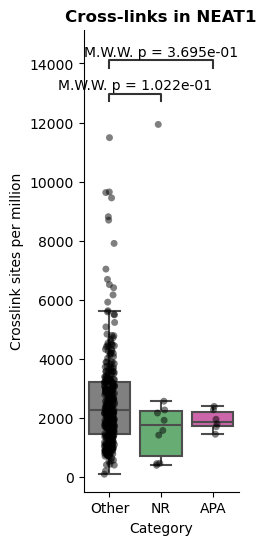

In [72]:
gene = "NEAT1"
df = get_cross_links_on_gene(path_to_paraspeckles, gene, candidates_apa, candidates_nuc_ret)

save_figure(f"{figures_subfolder}/regulators_lncRNA_crosslinks/boxplot_crosslinks_{gene}_R2_regulators_APA_vs_NR.pdf",
            pattern="boxplot_crosslinks_<gene>_R2_regulators_APA_vs_NR.pdf",
            legend="CLIP cross-link density on one transcript per file (NEAT1, XIST, MALAT1, NORAD, SFPQ; cross-link "
                   "sites per million, MN_diff/results/paraspeckles) for each CLIP dataset, grouped as R2 regulators of "
                   "lengthening classified APA (pink) or nuclear retention (NR, green) vs all other CLIPs (grey). Boxes "
                   "without outliers, one dot per CLIP; two-sided Mann-Whitney U, Other vs NR and Other vs APA.")

Other vs. NR: Mann-Whitney-Wilcoxon test two-sided, P_val:3.581e-03 U_stat=7.440e+02
Other vs. APA: Mann-Whitney-Wilcoxon test two-sided, P_val:6.611e-02 U_stat=5.450e+02


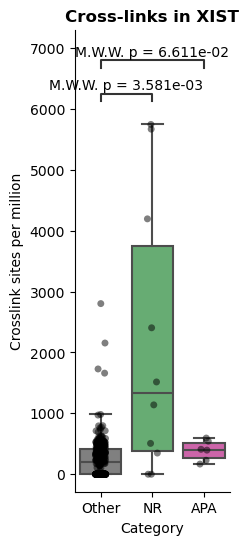

In [73]:
gene = "XIST"
df = get_cross_links_on_gene(path_to_paraspeckles, gene, candidates_apa, candidates_nuc_ret)

save_figure(f"{figures_subfolder}/regulators_lncRNA_crosslinks/boxplot_crosslinks_{gene}_R2_regulators_APA_vs_NR.pdf",
            pattern="boxplot_crosslinks_<gene>_R2_regulators_APA_vs_NR.pdf",
            legend="CLIP cross-link density on one transcript per file (NEAT1, XIST, MALAT1, NORAD, SFPQ; cross-link "
                   "sites per million, MN_diff/results/paraspeckles) for each CLIP dataset, grouped as R2 regulators of "
                   "lengthening classified APA (pink) or nuclear retention (NR, green) vs all other CLIPs (grey). Boxes "
                   "without outliers, one dot per CLIP; two-sided Mann-Whitney U, Other vs NR and Other vs APA.")

Other vs. NR: Mann-Whitney-Wilcoxon test two-sided, P_val:1.697e-01 U_stat=2.021e+03
Other vs. APA: Mann-Whitney-Wilcoxon test two-sided, P_val:2.467e-01 U_stat=6.950e+02


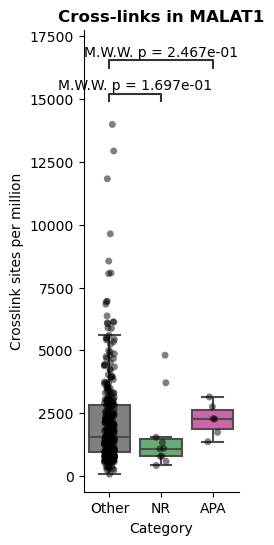

In [74]:
gene = "MALAT1"
df = get_cross_links_on_gene(path_to_paraspeckles, gene, candidates_apa, candidates_nuc_ret)

save_figure(f"{figures_subfolder}/regulators_lncRNA_crosslinks/boxplot_crosslinks_{gene}_R2_regulators_APA_vs_NR.pdf",
            pattern="boxplot_crosslinks_<gene>_R2_regulators_APA_vs_NR.pdf",
            legend="CLIP cross-link density on one transcript per file (NEAT1, XIST, MALAT1, NORAD, SFPQ; cross-link "
                   "sites per million, MN_diff/results/paraspeckles) for each CLIP dataset, grouped as R2 regulators of "
                   "lengthening classified APA (pink) or nuclear retention (NR, green) vs all other CLIPs (grey). Boxes "
                   "without outliers, one dot per CLIP; two-sided Mann-Whitney U, Other vs NR and Other vs APA.")

Other vs. NR: Mann-Whitney-Wilcoxon test two-sided, P_val:9.320e-01 U_stat=1.584e+03
Other vs. APA: Mann-Whitney-Wilcoxon test two-sided, P_val:4.217e-03 U_stat=3.380e+02


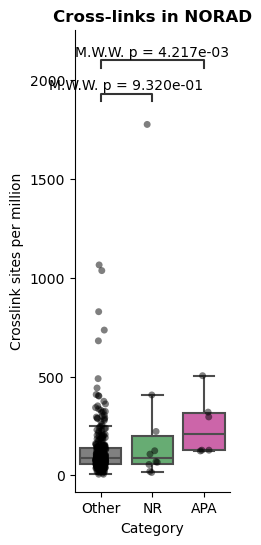

In [75]:
gene = "NORAD"
df = get_cross_links_on_gene(path_to_paraspeckles, gene, candidates_apa, candidates_nuc_ret)

save_figure(f"{figures_subfolder}/regulators_lncRNA_crosslinks/boxplot_crosslinks_{gene}_R2_regulators_APA_vs_NR.pdf",
            pattern="boxplot_crosslinks_<gene>_R2_regulators_APA_vs_NR.pdf",
            legend="CLIP cross-link density on one transcript per file (NEAT1, XIST, MALAT1, NORAD, SFPQ; cross-link "
                   "sites per million, MN_diff/results/paraspeckles) for each CLIP dataset, grouped as R2 regulators of "
                   "lengthening classified APA (pink) or nuclear retention (NR, green) vs all other CLIPs (grey). Boxes "
                   "without outliers, one dot per CLIP; two-sided Mann-Whitney U, Other vs NR and Other vs APA.")

Other vs. NR: Mann-Whitney-Wilcoxon test two-sided, P_val:9.108e-01 U_stat=1.576e+03
Other vs. APA: Mann-Whitney-Wilcoxon test two-sided, P_val:1.520e-01 U_stat=6.330e+02


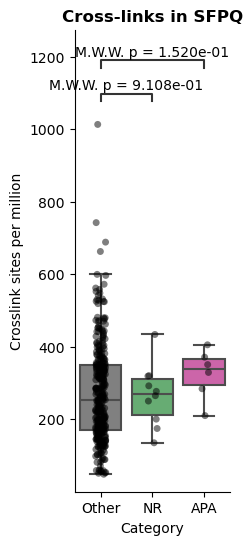

In [76]:
gene = "SFPQ"
df = get_cross_links_on_gene(path_to_paraspeckles, gene, candidates_apa, candidates_nuc_ret)

save_figure(f"{figures_subfolder}/regulators_lncRNA_crosslinks/boxplot_crosslinks_{gene}_R2_regulators_APA_vs_NR.pdf",
            pattern="boxplot_crosslinks_<gene>_R2_regulators_APA_vs_NR.pdf",
            legend="CLIP cross-link density on one transcript per file (NEAT1, XIST, MALAT1, NORAD, SFPQ; cross-link "
                   "sites per million, MN_diff/results/paraspeckles) for each CLIP dataset, grouped as R2 regulators of "
                   "lengthening classified APA (pink) or nuclear retention (NR, green) vs all other CLIPs (grey). Boxes "
                   "without outliers, one dot per CLIP; two-sided Mann-Whitney U, Other vs NR and Other vs APA.")

<a id="sfpq-tdp43-fus-kd"></a>
## Regulators and m6A in SFPQ, TDP-43 and FUS knock-down cells

Same figures as the VCP knock-in section, for the SFPQ / TDP-43 / FUS knock-down experiment (`SFPQ_TDP_FUS_KD/results/3UTR_analysis/CLIP`, same Welch score, 50-nt bins from −1000 to +200 nt). All figures use the nuclear fraction of untreated (light grey), Scramble siRNA (purple, the control of the knock-downs), SFPQ KD (orange), TDP-43 KD (red) and FUS KD (teal) cells. Region scores as in the VCP knock-in section (R1: max Welch score in [−350, −50] upstream of the pPAS; R2: −min in [0, +150] downstream of the pPAS; R3: −min in [−350, −50] upstream of the dPAS).

For the regulators of lengthening (`class_df_R{1,2,3}`, APA then nuclear retention) and the regulators of shortening in VCP (`candidates_vcp_R{1,2,3}`):
- one barplot per region, one panel per CLIP;
- boxplots of the change in score, KD − Scramble, one value per CLIP, one panel per region (no test);
- boxplots of the region scores in the five conditions, one panel per region (own y axis), with paired Wilcoxon signed-rank tests of each KD vs Scramble;
- the same for R2 only, split into APA and nuclear-retention regulators (`class_df_R2`, `class_df_vcp`).

Then the m6A score in each region (`RNA_modifs/m6A/welch`).

Saved in `regulators_SFPQ_TDP43_FUS_KD/`:
- `barplot_R{1,2,3}_welch_nuclear_KD_lengthening_regulators.pdf`, `barplot_R{1,2,3}_welch_nuclear_KD_shortening_in_VCP_regulators.pdf`
- `boxplot_welch_change_KD_vs_Scramble_lengthening_regulators.pdf`, `boxplot_welch_change_KD_vs_Scramble_shortening_in_VCP_regulators.pdf`
- `boxplot_welch_KD_lengthening_regulators.pdf`, `boxplot_welch_KD_shortening_in_VCP_regulators.pdf`
- `boxplot_R2_welch_KD_lengthening_regulators_APA_vs_NR.pdf`, `boxplot_R2_welch_KD_shortening_in_VCP_regulators_APA_vs_NR.pdf`
- `barplot_R1_R2_R3_welch_nuclear_KD_m6A.pdf`

In [77]:
from scipy.stats import wilcoxon

path_to_kd = f"{PROJECT_DIR}/SFPQ_TDP_FUS_KD/results"
kd_proximals = load_and_combine_integrated_CLIP(f"{path_to_kd}/3UTR_analysis/CLIP", prefix='proximal')
kd_distals = load_and_combine_integrated_CLIP(f"{path_to_kd}/3UTR_analysis/CLIP", prefix='distal')

kd_conditions = ["Untreated_Nuc", "Scramble_Nuc", "SFPQ_KD_Nuc", "TDP43_KD_Nuc", "FUS_KD_Nuc"]
kd_labels = {"Untreated_Nuc": "Untreated", "Scramble_Nuc": "Scramble", "SFPQ_KD_Nuc": "SFPQ KD",
             "TDP43_KD_Nuc": "TDP-43 KD", "FUS_KD_Nuc": "FUS KD"}
kd_palette = {"Untreated_Nuc": "#a8a8a8", "Scramble_Nuc": "#6e3ffa", "SFPQ_KD_Nuc": "#f28e2b",
              "TDP43_KD_Nuc": "#e15759", "FUS_KD_Nuc": "#76b7b2"}
kd_control = "Scramble_Nuc"
kd_knockdowns = ["SFPQ_KD_Nuc", "TDP43_KD_Nuc", "FUS_KD_Nuc"]
kd_regions = {"R1": (kd_proximals, positive_proximal_region, 'max'),
              "R2": (kd_proximals, negative_proximal_region, 'negmin'),
              "R3": (kd_distals, positive_distal_region, 'negmin')}
KD_REGION_DEF = "R1: max Welch score (-log10(p) x dPUD) in [-350, -50] nt upstream of the pPAS; R2: -(min Welch score) in [0, +150] nt downstream of the pPAS (positive = depletion); R3: -(min Welch score) in [-350, -50] nt upstream of the dPAS"
KD_CONDITIONS_DEF = "untreated (light grey), Scramble siRNA (purple), SFPQ KD (orange), TDP-43 KD (red) and FUS KD (teal)"


def kd_region_score(profile, region, mode):
    """Region score of one Welch profile (24 bins from -1000 nt) in each KD condition."""
    sub_df = profile[[f"-log10(pval)*dPUD_{t}" for t in kd_conditions]].copy()
    sub_df.columns = kd_conditions
    sub_df.index = [nb_nucleotides_upstream + j * length_region for j in range(sub_df.shape[0])]
    sub_r = sub_df[(sub_df.index >= region[0]) & (sub_df.index <= region[1])]
    return sub_r.max() if mode == 'max' else -sub_r.min()


def kd_scores(clips, region_key):
    """Long table: one row per CLIP x condition, region score of region_key."""
    df_res, region, mode = kd_regions[region_key]
    records = []
    for clip in clips:
        scores = kd_region_score(df_res[clip], region, mode)
        records += [{'regulator': clip, 'condition': t, 'score': scores[t]} for t in kd_conditions]
    return pd.DataFrame(records)


def kd_barplots(clips_per_region, group_name):
    """One figure per region, one panel per CLIP, bars = region score in each condition."""
    for region_key, clips in clips_per_region.items():
        n = len(clips)
        fig, axes = plt.subplots(1, n, figsize=(2 * n, 3))
        axes = np.atleast_1d(axes)
        df_kd = kd_scores(clips, region_key)
        for ax, clip in zip(axes, clips):
            sub = df_kd[df_kd['regulator'] == clip]
            sns.barplot(data=sub, x='condition', y='score', order=kd_conditions,
                        palette=[kd_palette[t] for t in kd_conditions], ax=ax)
            ax.set_title(get_RBP_name(clip), fontsize=8)
            ax.set_xticks([])
            ax.set_xlabel('')
            ax.set_ylabel('')
            ax.axhline(0, color='gray', linewidth=0.5)
            sns.despine(ax=ax)
        fig.suptitle(f"{region_key} - {group_name}", weight='bold')
        plt.tight_layout()
        yield region_key, fig


def kd_change_boxplot(clips_per_region, title):
    """Change in region score, KD - Scramble, one value per CLIP, one panel per region."""
    fig, axes = plt.subplots(1, 3, figsize=(7, 4))
    for ax, (region_key, clips) in zip(axes, clips_per_region.items()):
        paired = kd_scores(clips, region_key).pivot(index='regulator', columns='condition', values='score')
        diff = pd.DataFrame({kd_labels[t]: paired[t] - paired[kd_control] for t in kd_knockdowns})
        sns.boxplot(data=diff, palette=[kd_palette[t] for t in kd_knockdowns], width=0.5, showfliers=False, ax=ax)
        ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
        ax.set_title(f"{region_key} (n = {len(diff)})", weight='bold')
        ax.set_ylabel("Δ score (KD − Scramble)" if region_key == "R1" else "")
        ax.tick_params(axis='x', rotation=45)
        sns.despine(ax=ax)
    plt.suptitle(title, weight='bold')
    plt.tight_layout()


def kd_score_axis(ax, df_kd, title):
    """Boxplot of region scores in the five conditions + paired Wilcoxon of each KD vs Scramble."""
    sns.boxplot(data=df_kd, x='condition', y='score', order=kd_conditions,
                palette=[kd_palette[t] for t in kd_conditions], showfliers=False, ax=ax)
    sns.stripplot(data=df_kd, x='condition', y='score', order=kd_conditions, color='black',
                  size=3, alpha=0.6, ax=ax)
    paired = df_kd.pivot(index='regulator', columns='condition', values='score')
    ymax, yrange = df_kd['score'].max(), df_kd['score'].max() - min(df_kd['score'].min(), 0)
    x0 = kd_conditions.index(kd_control)
    for k, t in enumerate(kd_knockdowns):
        pval = wilcoxon(paired[kd_control], paired[t]).pvalue
        x1 = kd_conditions.index(t)
        y = ymax + yrange * (0.06 + 0.12 * k)
        ax.plot([x0, x1], [y, y], color='black', linewidth=0.8)
        ax.text((x0 + x1) / 2, y + yrange * 0.01, f"p = {pval:.2g}", ha='center', va='bottom', fontsize=7)
        print(f"{title}: {kd_labels[t]} vs Scramble, n = {len(paired)}, median "
              f"{paired[kd_control].median():.2f} -> {paired[t].median():.2f}, Wilcoxon p = {pval:.3g}")
    ax.set_ylim(top=ymax + yrange * 0.45)
    ax.axhline(0, color='gray', linewidth=0.5)
    ax.set_xticks(range(len(kd_conditions)))
    ax.set_xticklabels([kd_labels[t] for t in kd_conditions], rotation=45, ha='right')
    ax.set_xlabel('')
    ax.set_title(f"{title} (n = {len(paired)})", weight='bold')
    sns.despine(ax=ax)


def kd_score_boxplot(clips_per_region, title):
    fig, axes = plt.subplots(1, 3, figsize=(10, 4.2))
    for ax, (region_key, clips) in zip(axes, clips_per_region.items()):
        kd_score_axis(ax, kd_scores(clips, region_key), region_key)
        ax.set_ylabel('Region score (Welch score)' if region_key == "R1" else '')
    plt.suptitle(title, weight='bold')
    plt.tight_layout()


def kd_score_boxplot_R2_by_category(class_df, title):
    fig, axes = plt.subplots(1, 2, figsize=(7, 4.2))
    for ax, category in zip(axes, ['APA', 'Nuclear retention']):
        clips = class_df[class_df['category'] == category]['regulator'].tolist()
        kd_score_axis(ax, kd_scores(clips, "R2"), f"R2 {category}")
        ax.title.set_color(category_palette[category])
        ax.set_ylabel('R2 score (Welch score)' if category == 'APA' else '')
    plt.suptitle(title, weight='bold')
    plt.tight_layout()


# regulators of each region: lengthening (APA then nuclear retention) and shortening in VCP
lengthening_clips = {r: (c[c['category'] == 'APA']['regulator'].tolist()
                         + c[c['category'] == 'Nuclear retention']['regulator'].tolist())
                     for r, c in zip(["R1", "R2", "R3"], [class_df_R1, class_df_R2, class_df_R3])}
shortening_clips = dict(zip(["R1", "R2", "R3"], [candidates_vcp_R1, candidates_vcp_R2, candidates_vcp_R3]))
{r: len(c) for r, c in lengthening_clips.items()}, {r: len(c) for r, c in shortening_clips.items()}

({'R1': 11, 'R2': 17, 'R3': 15}, {'R1': 15, 'R2': 15, 'R3': 4})

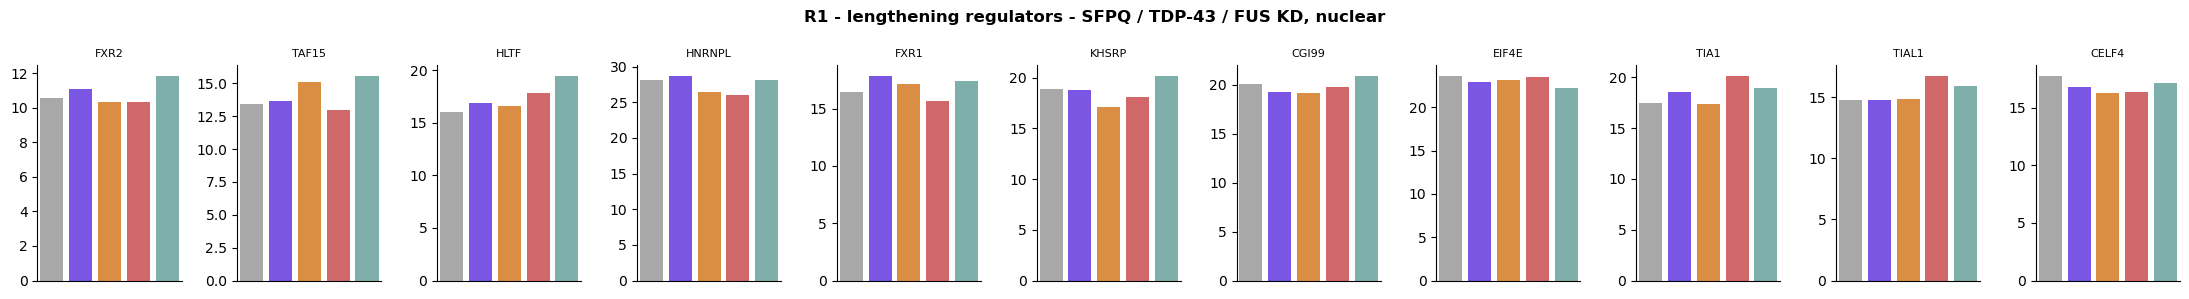

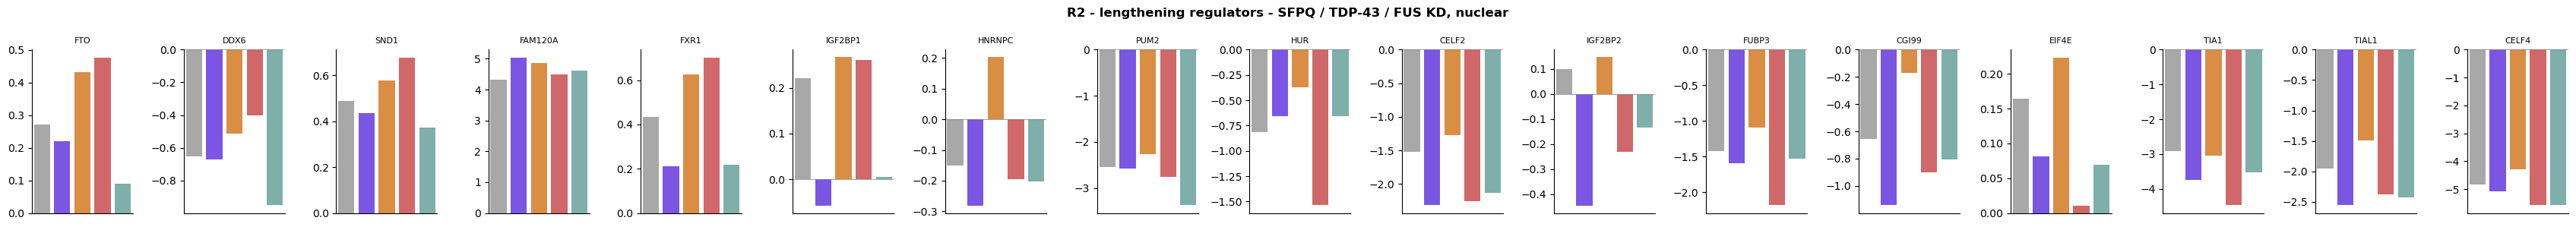

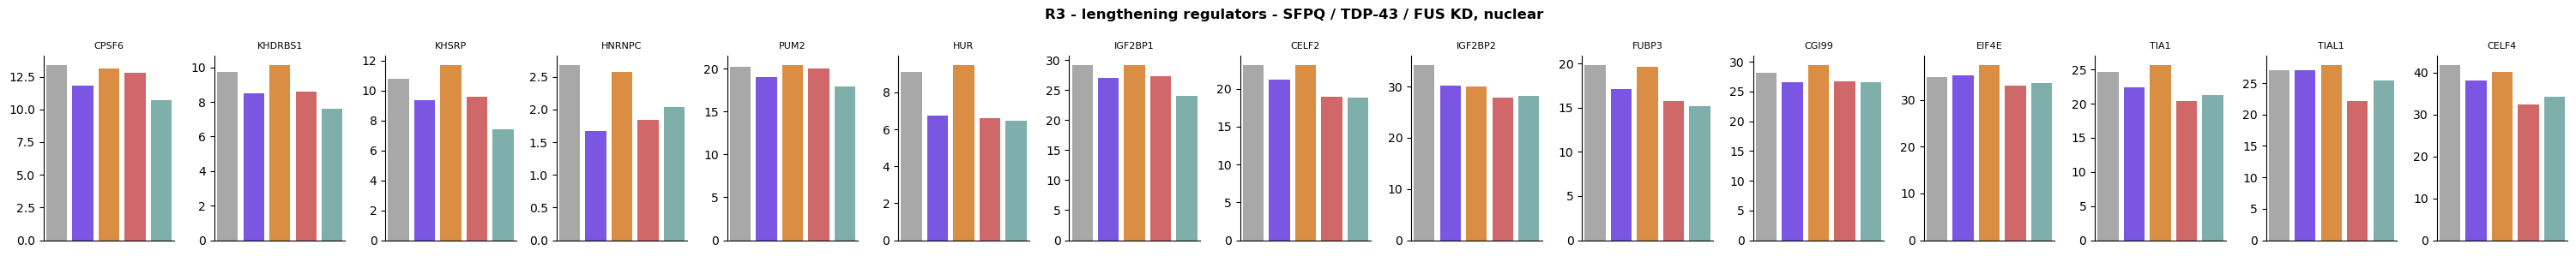

In [78]:
# Barplots, regulators of lengthening: one figure per region, one panel per CLIP
for region_key, fig in kd_barplots(lengthening_clips, "lengthening regulators - SFPQ / TDP-43 / FUS KD, nuclear"):
    save_figure(f"{figures_subfolder}/regulators_SFPQ_TDP43_FUS_KD/barplot_{region_key}_welch_nuclear_KD_lengthening_regulators.pdf",
                legend=f"SFPQ / TDP-43 / FUS knock-down experiment: {region_key} score of each of the {region_key} "
                       "regulators of lengthening (APA, then nuclear retention), one panel per CLIP dataset, in the nuclear fraction of "
                       f"{KD_CONDITIONS_DEF} cells. One value per bar. {KD_REGION_DEF}.")
    plt.show()

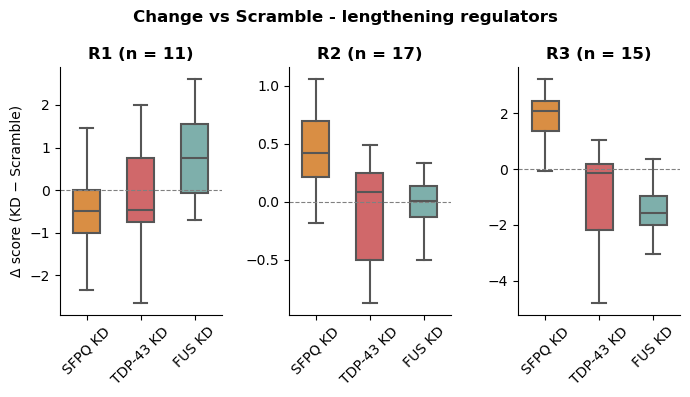

In [79]:
# Change in region score, KD - Scramble, regulators of lengthening
kd_change_boxplot(lengthening_clips, "Change vs Scramble - lengthening regulators")
save_figure(f"{figures_subfolder}/regulators_SFPQ_TDP43_FUS_KD/boxplot_welch_change_KD_vs_Scramble_lengthening_regulators.pdf",
            legend="SFPQ / TDP-43 / FUS knock-down experiment, nuclear fraction: change in region score between each "
                   "knock-down and Scramble siRNA (SFPQ KD orange, TDP-43 KD red, FUS KD teal), for the regulators of lengthening (APA, then nuclear retention) "
                   "of each region. One panel per region; one value per CLIP dataset; boxes without outliers; no "
                   f"statistical test. {KD_REGION_DEF}.")
plt.show()

R1: SFPQ KD vs Scramble, n = 11, median 17.89 -> 17.07, Wilcoxon p = 0.102
R1: TDP-43 KD vs Scramble, n = 11, median 17.89 -> 17.82, Wilcoxon p = 0.765
R1: FUS KD vs Scramble, n = 11, median 17.89 -> 18.96, Wilcoxon p = 0.0674
R2: SFPQ KD vs Scramble, n = 17, median -0.66 -> -0.17, Wilcoxon p = 0.000107
R2: TDP-43 KD vs Scramble, n = 17, median -0.66 -> -0.40, Wilcoxon p = 0.818
R2: FUS KD vs Scramble, n = 17, median -0.66 -> -0.66, Wilcoxon p = 0.963
R3: SFPQ KD vs Scramble, n = 15, median 21.23 -> 23.12, Wilcoxon p = 0.000122
R3: TDP-43 KD vs Scramble, n = 15, median 21.23 -> 20.03, Wilcoxon p = 0.135
R3: FUS KD vs Scramble, n = 15, median 21.23 -> 18.83, Wilcoxon p = 0.000305


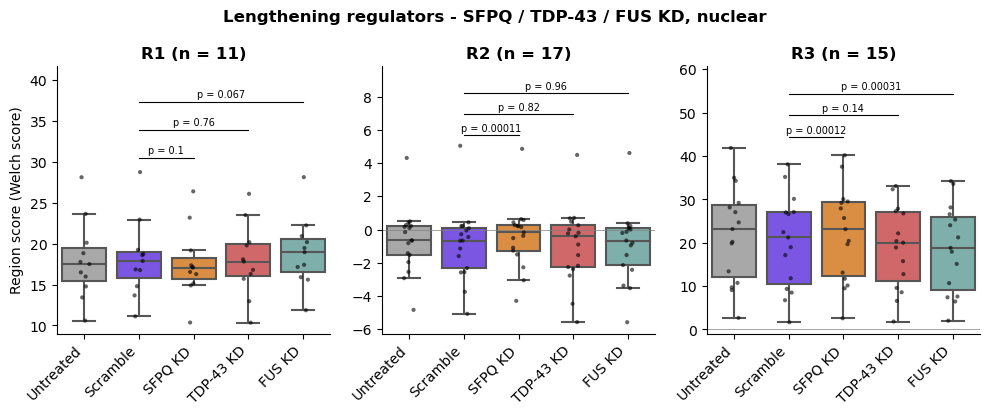

In [80]:
# Region scores in the five conditions, regulators of lengthening; paired Wilcoxon, each KD vs Scramble
kd_score_boxplot(lengthening_clips, "Lengthening regulators - SFPQ / TDP-43 / FUS KD, nuclear")
save_figure(f"{figures_subfolder}/regulators_SFPQ_TDP43_FUS_KD/boxplot_welch_KD_lengthening_regulators.pdf",
            legend="SFPQ / TDP-43 / FUS knock-down experiment, nuclear fraction: region score of the regulators of lengthening (APA, then nuclear retention) "
                   f"of each region (one point per CLIP dataset) in {KD_CONDITIONS_DEF} cells. One panel per region, "
                   f"each with its own y axis. {KD_REGION_DEF}. Boxes: median and interquartile range, whiskers 1.5 x "
                   "IQR. p: two-sided paired Wilcoxon signed-rank tests of each knock-down vs Scramble, uncorrected; "
                   "n = number of CLIP datasets.")
plt.show()

R2 APA: SFPQ KD vs Scramble, n = 6, median 0.22 -> 0.50, Wilcoxon p = 0.156
R2 APA: TDP-43 KD vs Scramble, n = 6, median 0.22 -> 0.58, Wilcoxon p = 0.438
R2 APA: FUS KD vs Scramble, n = 6, median 0.22 -> 0.15, Wilcoxon p = 0.219
R2 Nuclear retention: SFPQ KD vs Scramble, n = 11, median -1.59 -> -1.09, Wilcoxon p = 0.000977
R2 Nuclear retention: TDP-43 KD vs Scramble, n = 11, median -1.59 -> -2.18, Wilcoxon p = 0.32
R2 Nuclear retention: FUS KD vs Scramble, n = 11, median -1.59 -> -1.53, Wilcoxon p = 0.413


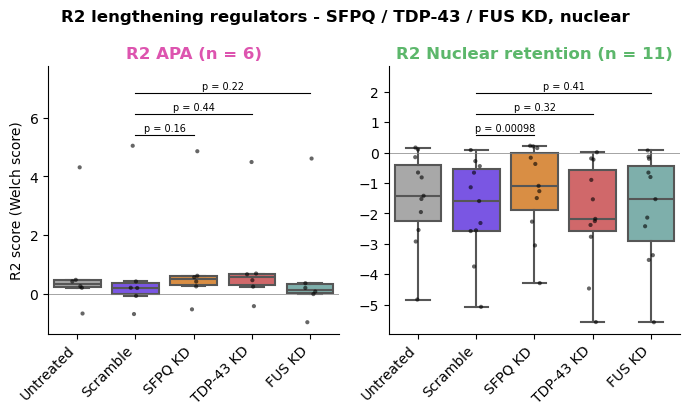

In [81]:
# R2 only, APA vs nuclear-retention regulators of lengthening (class_df_R2; ambiguous ones left out)
kd_score_boxplot_R2_by_category(class_df_R2, "R2 lengthening regulators - SFPQ / TDP-43 / FUS KD, nuclear")
save_figure(f"{figures_subfolder}/regulators_SFPQ_TDP43_FUS_KD/boxplot_R2_welch_KD_lengthening_regulators_APA_vs_NR.pdf",
            legend="SFPQ / TDP-43 / FUS knock-down experiment, nuclear fraction: R2 score of the R2 regulators of lengthening, "
                   "split into APA (left) and nuclear-retention (right) regulators (class_df_R2; significant R2 score in both "
                   "fractions, or in the nucleus only, of CTRL at D35 in the MN differentiation data; ambiguous ones left "
                   f"out), in {KD_CONDITIONS_DEF} cells. One point per CLIP dataset; each panel has its own y axis. "
                   "R2 score: -(min Welch score (-log10(p) x dPUD)) in [0, +150] nt downstream of the pPAS (positive = "
                   "depletion). Boxes: median and interquartile range, whiskers 1.5 x IQR. p: two-sided paired Wilcoxon "
                   "signed-rank tests of each knock-down vs Scramble, uncorrected; n = number of CLIP datasets.")
plt.show()

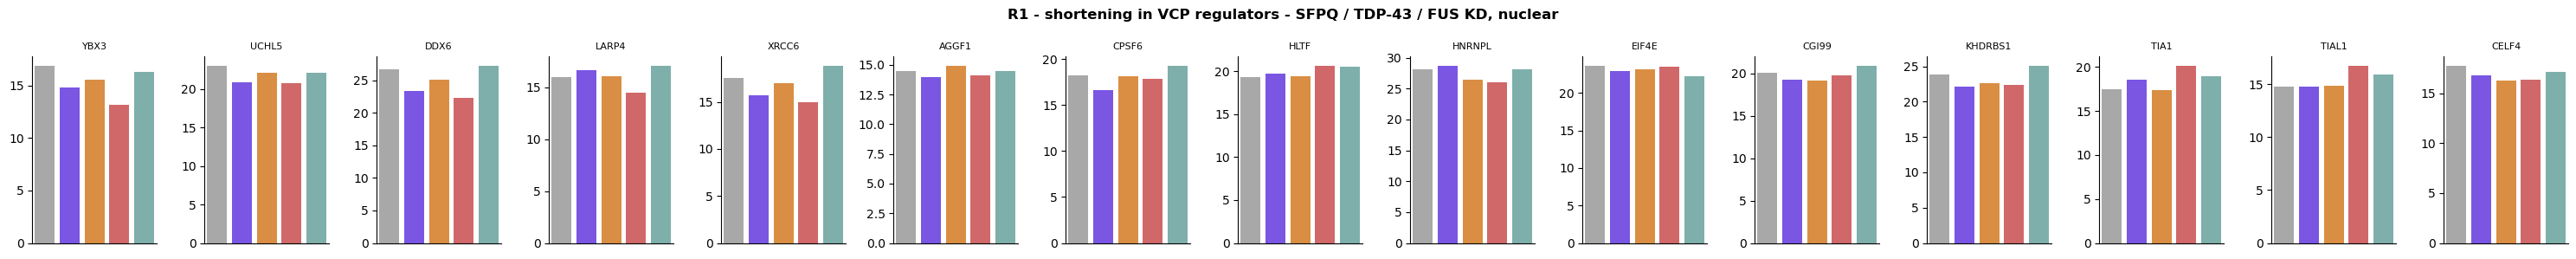

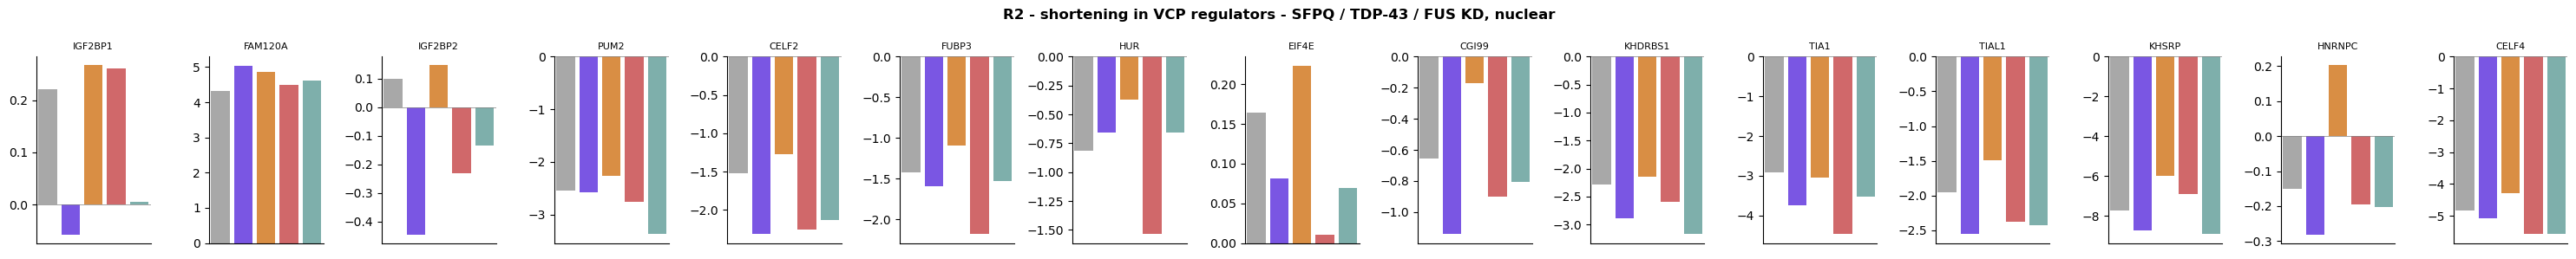

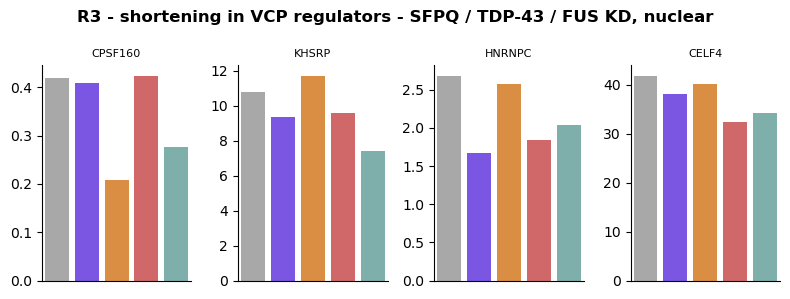

In [82]:
# Barplots, regulators of shortening in VCP: one figure per region, one panel per CLIP
for region_key, fig in kd_barplots(shortening_clips, "shortening in VCP regulators - SFPQ / TDP-43 / FUS KD, nuclear"):
    save_figure(f"{figures_subfolder}/regulators_SFPQ_TDP43_FUS_KD/barplot_{region_key}_welch_nuclear_KD_shortening_in_VCP_regulators.pdf",
                legend=f"SFPQ / TDP-43 / FUS knock-down experiment: {region_key} score of each of the {region_key} "
                       "regulators of shortening in VCP (VCP vs CTRL at D35), one panel per CLIP dataset, in the nuclear fraction of "
                       f"{KD_CONDITIONS_DEF} cells. One value per bar. {KD_REGION_DEF}.")
    plt.show()

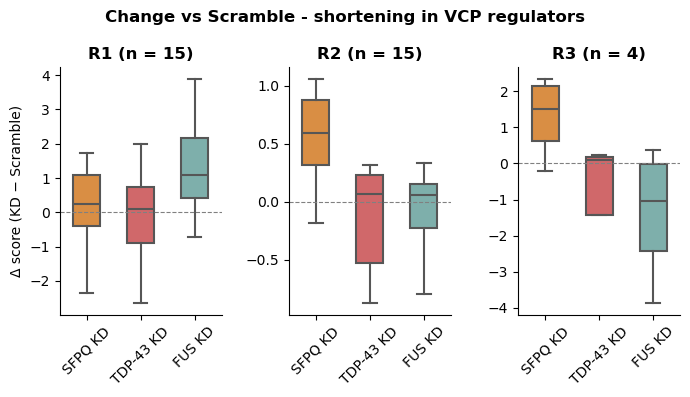

In [83]:
# Change in region score, KD - Scramble, regulators of shortening in VCP
kd_change_boxplot(shortening_clips, "Change vs Scramble - shortening in VCP regulators")
save_figure(f"{figures_subfolder}/regulators_SFPQ_TDP43_FUS_KD/boxplot_welch_change_KD_vs_Scramble_shortening_in_VCP_regulators.pdf",
            legend="SFPQ / TDP-43 / FUS knock-down experiment, nuclear fraction: change in region score between each "
                   "knock-down and Scramble siRNA (SFPQ KD orange, TDP-43 KD red, FUS KD teal), for the regulators of shortening in VCP (VCP vs CTRL at D35) "
                   "of each region. One panel per region; one value per CLIP dataset; boxes without outliers; no "
                   f"statistical test. {KD_REGION_DEF}.")
plt.show()

R1: SFPQ KD vs Scramble, n = 15, median 18.60 -> 18.17, Wilcoxon p = 0.359
R1: TDP-43 KD vs Scramble, n = 15, median 18.60 -> 19.79, Wilcoxon p = 0.89
R1: FUS KD vs Scramble, n = 15, median 18.60 -> 19.32, Wilcoxon p = 0.00336
R2: SFPQ KD vs Scramble, n = 15, median -1.59 -> -1.09, Wilcoxon p = 0.000183
R2: TDP-43 KD vs Scramble, n = 15, median -1.59 -> -2.18, Wilcoxon p = 0.72
R2: FUS KD vs Scramble, n = 15, median -1.59 -> -1.53, Wilcoxon p = 0.978
R3: SFPQ KD vs Scramble, n = 4, median 5.51 -> 7.15, Wilcoxon p = 0.25
R3: TDP-43 KD vs Scramble, n = 4, median 5.51 -> 5.71, Wilcoxon p = 0.875
R3: FUS KD vs Scramble, n = 4, median 5.51 -> 4.73, Wilcoxon p = 0.375


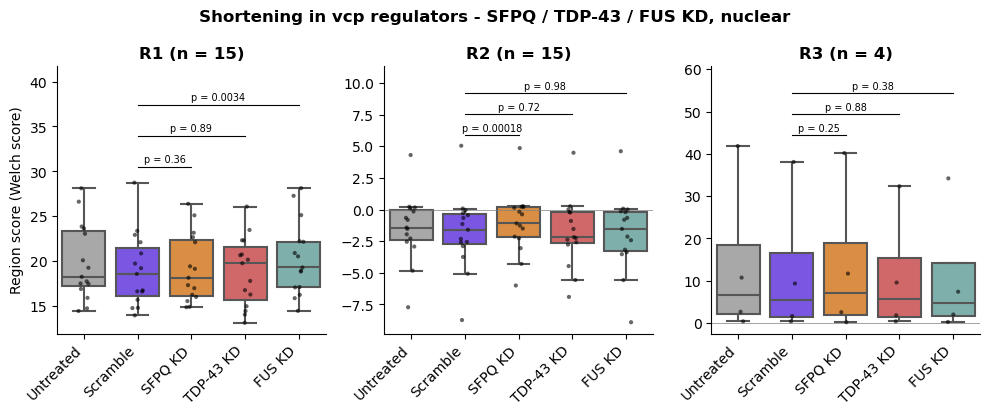

In [84]:
# Region scores in the five conditions, regulators of shortening in VCP; paired Wilcoxon, each KD vs Scramble
kd_score_boxplot(shortening_clips, "Shortening in vcp regulators - SFPQ / TDP-43 / FUS KD, nuclear")
save_figure(f"{figures_subfolder}/regulators_SFPQ_TDP43_FUS_KD/boxplot_welch_KD_shortening_in_VCP_regulators.pdf",
            legend="SFPQ / TDP-43 / FUS knock-down experiment, nuclear fraction: region score of the regulators of shortening in VCP (VCP vs CTRL at D35) "
                   f"of each region (one point per CLIP dataset) in {KD_CONDITIONS_DEF} cells. One panel per region, "
                   f"each with its own y axis. {KD_REGION_DEF}. Boxes: median and interquartile range, whiskers 1.5 x "
                   "IQR. p: two-sided paired Wilcoxon signed-rank tests of each knock-down vs Scramble, uncorrected; "
                   "n = number of CLIP datasets.")
plt.show()

R2 APA: SFPQ KD vs Scramble, n = 2, median 2.49 -> 2.56, Wilcoxon p = 1
R2 APA: TDP-43 KD vs Scramble, n = 2, median 2.49 -> 2.38, Wilcoxon p = 1
R2 APA: FUS KD vs Scramble, n = 2, median 2.49 -> 2.31, Wilcoxon p = 1
R2 Nuclear retention: SFPQ KD vs Scramble, n = 13, median -2.32 -> -1.27, Wilcoxon p = 0.000244
R2 Nuclear retention: TDP-43 KD vs Scramble, n = 13, median -2.32 -> -2.25, Wilcoxon p = 0.839
R2 Nuclear retention: FUS KD vs Scramble, n = 13, median -2.32 -> -2.14, Wilcoxon p = 0.839


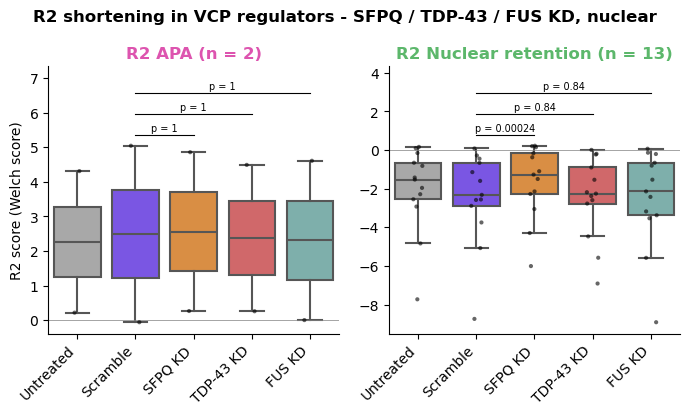

In [85]:
# R2 only, APA vs nuclear-retention regulators of shortening in VCP (class_df_vcp; ambiguous ones left out)
kd_score_boxplot_R2_by_category(class_df_vcp, "R2 shortening in VCP regulators - SFPQ / TDP-43 / FUS KD, nuclear")
save_figure(f"{figures_subfolder}/regulators_SFPQ_TDP43_FUS_KD/boxplot_R2_welch_KD_shortening_in_VCP_regulators_APA_vs_NR.pdf",
            legend="SFPQ / TDP-43 / FUS knock-down experiment, nuclear fraction: R2 score of the R2 regulators of shortening in VCP, "
                   "split into APA (left) and nuclear-retention (right) regulators (class_df_vcp: one CLIP dataset per RBP; significant R2 score in both "
                   "fractions, or in the nucleus only, of CTRL at D35 in the MN differentiation data; ambiguous ones left "
                   f"out), in {KD_CONDITIONS_DEF} cells. One point per CLIP dataset; each panel has its own y axis. "
                   "R2 score: -(min Welch score (-log10(p) x dPUD)) in [0, +150] nt downstream of the pPAS (positive = "
                   "depletion). Boxes: median and interquartile range, whiskers 1.5 x IQR. p: two-sided paired Wilcoxon "
                   "signed-rank tests of each knock-down vs Scramble, uncorrected; n = number of CLIP datasets.")
plt.show()

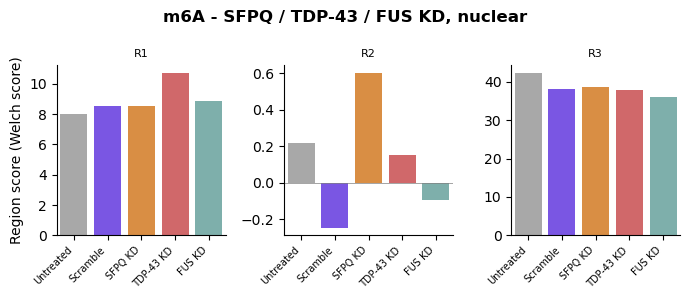

In [86]:
# m6A in the knock-down cells: score of m6A in each region
path_to_kd_m6A = f"{path_to_kd}/RNA_modifs/m6A/welch"
kd_m6A = {"proximal": load_and_combine_integrated_CLIP(path_to_kd_m6A, prefix='proximal')["human.hg38.m6A.gff_RMBase"],
          "distal": load_and_combine_integrated_CLIP(path_to_kd_m6A, prefix='distal')["human.hg38.m6A.gff_RMBase"]}

fig, axes = plt.subplots(1, 3, figsize=(7, 3))
for ax, region_key in zip(axes, ["R1", "R2", "R3"]):
    _, region, mode = kd_regions[region_key]
    scores = kd_region_score(kd_m6A["distal" if region_key == "R3" else "proximal"], region, mode)
    sns.barplot(ax=ax, x=kd_conditions, y=scores.values, palette=[kd_palette[t] for t in kd_conditions])
    ax.set_title(region_key, fontsize=8)
    ax.set_xticklabels([kd_labels[t] for t in kd_conditions], rotation=45, ha='right', fontsize=7)
    ax.axhline(0, color='gray', linewidth=0.5)
    sns.despine(ax=ax)
axes[0].set_ylabel("Region score (Welch score)")
fig.suptitle("m6A - SFPQ / TDP-43 / FUS KD, nuclear", weight='bold')
plt.tight_layout()
save_figure(f"{figures_subfolder}/regulators_SFPQ_TDP43_FUS_KD/barplot_R1_R2_R3_welch_nuclear_KD_m6A.pdf",
            legend="SFPQ / TDP-43 / FUS knock-down experiment, nuclear fraction: score of m6A sites (RMBase) in each "
                   f"region, in {KD_CONDITIONS_DEF} cells. One value per bar. {KD_REGION_DEF}.")
plt.show()